# 뉴스 요약 전체 실험 — Run All 통합본

루트의 `00~06` 실험 노트북과 후속 평가 Python 스크립트 3개를 실행 순서대로 합친 노트북입니다. 원본 파일은 수정하지 않습니다.

- 권장 커널: 프로젝트의 `.venv` (`Python 3.11 (Team4 News GPU)`)
- 실행 순서: 환경 확인 → EDA → 토큰화/임베딩 → baseline → 정제/분할 → ablation/튜닝 → 디코딩 → 최종 test → 오류 분석 → 프로젝트 요약
- 학습 완료 산출물이 있으면 기존 단계의 `SKIP_COMPLETED=True` 설정에 따라 재사용합니다.


In [2]:
from pathlib import Path
import os
import sys

def _find_project_root(start=Path.cwd().resolve()):
    for candidate in (start, *start.parents):
        if (candidate / '00_environment_data_kobart.ipynb').exists() and (candidate / '.venv').exists():
            return candidate
    fixed = Path(r'C:\Users\KDS-30\Desktop\Projects\06_Team_Project4')
    if fixed.exists():
        return fixed
    raise FileNotFoundError('06_Team_Project4 프로젝트 루트를 찾지 못했습니다.')

PROJECT_ROOT = _find_project_root()
PROJECT = PROJECT_ROOT
os.chdir(PROJECT_ROOT)
os.environ['HF_HOME'] = str(PROJECT_ROOT / '.cache' / 'huggingface')
os.environ['HF_HUB_DOWNLOAD_TIMEOUT'] = '120'
os.environ['HF_HUB_DISABLE_SYMLINKS_WARNING'] = '1'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
expected_prefix = (PROJECT_ROOT / '.venv').resolve()
assert Path(sys.prefix).resolve() == expected_prefix, (
    f'커널을 프로젝트 .venv로 변경하세요. 현재: {sys.prefix} / 필요: {expected_prefix}'
)
print('프로젝트 루트:', PROJECT_ROOT)
print('Python:', sys.executable)


프로젝트 루트: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4
Python: c:\Users\KDS-30\Desktop\Projects\06_Team_Project4\.venv\Scripts\python.exe



---

# 원본 단계: `00_environment_data_kobart.ipynb`


# 00. 환경·데이터·KoBART 생성 확인

수업 `7_1.ipynb`의 BART 사용 흐름으로 한국어 뉴스 한 건의 생성을 확인합니다.

커널은 **Python 3.11 (Team4 News GPU)**를 선택하고 위에서부터 Shift+Enter로 실행하세요. 각 코드 셀은 앞 셀의 변수를 사용합니다. 처음 모델을 내려받을 때는 시간이 걸립니다.

이번 단계는 실행 점검입니다. 파인튜닝과 test 성능 평가는 수행하지 않습니다.

## 1. 프로젝트 경로와 실행 환경

프로젝트 가상환경을 선택했는지 확인하고 다운로드 캐시를 프로젝트 폴더에 보관합니다.

In [3]:
import os
import sys
from pathlib import Path

PROJECT = PROJECT_ROOT
assert PROJECT.exists(), "프로젝트 경로를 확인하세요."
assert Path(sys.prefix).resolve() == (PROJECT / ".venv").resolve(), "커널을 Python 3.11 (Team4 News GPU)로 바꾸세요."

os.environ["HF_HOME"] = str(PROJECT / ".cache" / "huggingface")
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "120"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
RESULTS = PROJECT / "results" / "00_environment_data_kobart"
RESULTS.mkdir(parents=True, exist_ok=True)
print("Python:", sys.version)
print("실행 파일:", sys.executable)
print("결과 폴더:", RESULTS)

Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
실행 파일: c:\Users\KDS-30\Desktop\Projects\06_Team_Project4\.venv\Scripts\python.exe
결과 폴더: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\00_environment_data_kobart


## 2. 라이브러리와 GPU 확인

CUDA 사용 여부와 실제 GPU 행렬 연산을 확인합니다. GPU 이름만 표시되는 것보다 확실한 점검입니다.

In [4]:
import json
import time
import platform
import importlib.metadata
import pandas as pd
import torch
from datasets import load_dataset
from huggingface_hub import HfApi
from transformers import AutoTokenizer, BartForConditionalGeneration, set_seed

set_seed(42)
assert torch.cuda.is_available(), "CUDA를 사용할 수 없습니다."
device = torch.device("cuda")
x = torch.randn(128, 128, device=device)
y = x @ x.T
torch.cuda.synchronize()
assert torch.isfinite(y).all().item()
environment = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "cuda": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0),
    "vram_gib": round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2),
    "cuda_matmul_passed": True,
    "packages": {p: importlib.metadata.version(p) for p in
                 ["transformers", "datasets", "tokenizers", "huggingface-hub"]},
}
display(pd.Series(environment, name="환경"))
del x, y

python                                                           3.11.9
torch                                                       2.7.1+cu128
cuda                                                               12.8
gpu                                  NVIDIA GeForce RTX 5060 Laptop GPU
vram_gib                                                           7.96
cuda_matmul_passed                                                 True
packages              {'transformers': '4.44.2', 'datasets': '2.21.0...
Name: 환경, dtype: object

## 3. 데이터 불러오기

입력은 `document`, 정답 요약은 `summary`입니다. 제공된 분할을 유지하고, 이번 점검에서는 train 샘플만 읽습니다. 재현을 위해 다운로드한 버전도 기록합니다.

In [5]:
DATASET_ID = "daekeun-ml/naver-news-summarization-ko"
MODEL_ID = "gogamza/kobart-base-v2"
api = HfApi()
dataset_revision = api.dataset_info(DATASET_ID).sha
model_revision = api.model_info(MODEL_ID).sha
ds = load_dataset(DATASET_ID, revision=dataset_revision)
split_counts = {name: len(data) for name, data in ds.items()}
display(pd.DataFrame(list(split_counts.items()), columns=["split", "건수"]))
print("컬럼:", ds["train"].column_names)
print("데이터 버전:", dataset_revision)

,split,건수
0,train,22194
1,validation,2466
2,test,2740


컬럼: ['date', 'category', 'press', 'title', 'document', 'link', 'summary']
데이터 버전: 916dfe6aed651b2ecd9d04fa0a704f8953e90762


Hugging Face에 있는 뉴스 데이터셋을 내려받아 노트북에서 사용할 수 있게 불러오는 과정
- date: 기사 날짜
- category: 경제 또는 IT과학
- press: 언론사
- title: 제목
- document: 기사 본문, 모델에 넣을 입력
- link: 원문 링크
- summary: 정답 요약, 모델이 학습할 목표

제작자가 미리 train, val, test로 나눠서 제공한것

## 4. 기사와 정답 요약 3건 읽기

제목, 원문, 정답을 함께 확인합니다. 정답에 반복이나 어색한 표현이 있는지도 살펴보세요.

In [6]:
samples = [ds["train"][i] for i in range(3)]
for i, row in enumerate(samples):
    assert isinstance(row["document"], str) and row["document"].strip()
    assert isinstance(row["summary"], str) and row["summary"].strip()
    print(f"샘플 {i} | {row['title']}")
    print("원문:", row["document"])
    print("정답 요약:", row["summary"])
    print()


샘플 0 | 추경호 중기 수출지원 총력 무역금융 40조 확대
원문: 앵커 정부가 올해 하반기 우리 경제의 버팀목인 수출 확대를 위해 총력을 기울이기로 했습니다. 특히 수출 중소기업의 물류난 해소를 위해 무역금융 규모를 40조 원 이상 확대하고 물류비 지원과 임시선박 투입 등을 추진하기로 했습니다. 류환홍 기자가 보도합니다. 기자 수출은 최고의 실적을 보였지만 수입액이 급증하면서 올해 상반기 우리나라 무역수지는 역대 최악인 103억 달러 적자를 기록했습니다. 정부가 수출확대에 총력을 기울이기로 한 것은 원자재 가격 상승 등 대외 리스크가 가중되는 상황에서 수출 증가세 지속이야말로 한국경제의 회복을 위한 열쇠라고 본 것입니다. 추경호 경제부총리 겸 기획재정부 장관 정부는 우리 경제의 성장엔진인 수출이 높은 증가세를 지속할 수 있도록 총력을 다하겠습니다. 우선 물류 부담 증가 원자재 가격 상승 등 가중되고 있는 대외 리스크에 대해 적극 대응하겠습니다. 특히 중소기업과 중견기업 수출 지원을 위해 무역금융 규모를 연초 목표보다 40조 원 늘린 301조 원까지 확대하고 물류비 부담을 줄이기 위한 대책도 마련했습니다. 이창양 산업통상자원부 장관 국제 해상운임이 안정될 때까지 월 4척 이상의 임시선박을 지속 투입하는 한편 중소기업 전용 선복 적재 용량 도 현재보다 주당 50TEU 늘려 공급하겠습니다. 하반기에 우리 기업들의 수출 기회를 늘리기 위해 2 500여 개 수출기업을 대상으로 해외 전시회 참가를 지원하는 등 마케팅 지원도 벌이기로 했습니다. 정부는 또 이달 중으로 반도체를 비롯한 첨단 산업 육성 전략을 마련해 수출 증가세를 뒷받침하고 에너지 소비를 줄이기 위한 효율화 방안을 마련해 무역수지 개선에 나서기로 했습니다. YTN 류환홍입니다.
정답 요약: 올해 상반기 우리나라 무역수지는 역대 최악인 103억 달러 적자를 기록한 가운데, 정부가 하반기에 우리 경제의 버팀목인 수출 확대를 위해 총력을 기울이기로 결정한 가운데, 특히 수출 중소기업의 물류난 해소를 위해 무역금융

train set에서 앞의 기사 3건을 꺼내서 그냥 보여준것

## 5. KoBART 토크나이저와 모델 로딩
- 한국어 문장을 숫자로 바꿔주는 토크나이저와, 그 숫자를 처리해 문장을 생성하는 KoBART 모델을 불러와 GPU에 올리는 단계
- 한국어 사전학습 모델을 사용합니다. 뉴스 요약용 파인튜닝 전이므로 출력 품질보다 생성이 정상 작동하는지 확인합니다.

In [7]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=model_revision)
model = BartForConditionalGeneration.from_pretrained(
    MODEL_ID, revision=model_revision, use_safetensors=True
).to(device)
model.eval()
print("모델:", MODEL_ID)
print("모델 버전:", model_revision)
print("파라미터 수:", f"{sum(p.numel() for p in model.parameters()):,}")
print("모델 장치:", next(model.parameters()).device)
print("특수 토큰:", tokenizer.special_tokens_map)

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
c:\Users\KDS-30\Desktop\Projects\06_Team_Project4\.venv\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


모델: gogamza/kobart-base-v2
모델 버전: f5899cc556216353e23ee36b66fad52b902066c5
파라미터 수: 123,859,968
모델 장치: cuda:0
특수 토큰: {'bos_token': '</s>', 'eos_token': '</s>', 'unk_token': '<unk>', 'pad_token': '<pad>', 'mask_token': '<mask>'}


## 6. 기사 한 건 토큰화

첫 train 기사를 최대 512토큰으로 변환합니다. 원래 토큰 수와 잘림 여부를 함께 기록합니다.

In [8]:
sample_index = 0
row = samples[sample_index]
full_input_tokens = len(tokenizer(row["document"])["input_ids"])
inputs = tokenizer(
    row["document"], return_tensors="pt", truncation=True, max_length=512,
    return_token_type_ids=False  # BART는 문장 구분용 token_type_ids를 사용하지 않습니다.
).to(device)
input_tokens = inputs["input_ids"].shape[1]
print("원래 토큰 수:", full_input_tokens)
print("모델에 들어가는 토큰 수:", input_tokens)
print("잘림 여부:", full_input_tokens > input_tokens)
print("input_ids 크기:", tuple(inputs["input_ids"].shape))
print("attention_mask 크기:", tuple(inputs["attention_mask"].shape))

원래 토큰 수: 315
모델에 들어가는 토큰 수: 315
잘림 여부: False
input_ids 크기: (1, 315)
attention_mask 크기: (1, 315)


ㄴ> 이 코드는 samples에서 문서 하나를 꺼내서, BART 토크나이저에 넣기 전 원래 토큰 수와 max_length=512 적용 후 실제 모델에 들어가는 토큰 수를 비교하는 코드

## 7. 실제 생성 실행

정답 요약을 전달하지 않고 기사만 전달합니다. 가장 높은 확률의 토큰을 선택하는 greedy 방식으로 최대 128개 새 토큰을 생성합니다.

In [9]:
generation_config = {"max_new_tokens": 128, "num_beams": 1, "do_sample": False}
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()
started = time.perf_counter()
with torch.inference_mode():
    generated_ids = model.generate(**inputs, **generation_config)
torch.cuda.synchronize()
generation_seconds = time.perf_counter() - started
prediction = tokenizer.decode(generated_ids[0], skip_special_tokens=True)
assert generated_ids.shape[1] > 1, "생성된 토큰이 없습니다."
print("생성 시간(초):", round(generation_seconds, 3))
print("최대 GPU 텐서 메모리(MiB):", round(torch.cuda.max_memory_allocated() / 2**20, 1))
print("생성 결과:", prediction)

생성 시간(초): 2.172
최대 GPU 텐서 메모리(MiB): 503.0
생성 결과: 가가 올해 상반기 상반기 올해 상반기 올해 상반기 우리나라 상반기 올해 상반기 우리나라 상반기 올해 상반기 우리나라 무역수지는 올해 상반기 올해 상반기 우리나라 무역수지는 역대 올해 올해 올해 상반기 올해 상반기 올해 상반기 우리나라 무역수지는 역대 최악인 103억 적자를 적자를 적자를 적자를 적자를 적자를을을을을을을을을을을 올해 상반기 올해 상반기 수출을을을을을을을을을을을을을을을을을을을을을을을을을을을을을을을을을을을을을을을을을을을을을을을을을을을


## 8. 원문·정답·생성 결과 비교

파인튜닝 전 모델은 원문을 복사하거나 반복할 수 있습니다. 이 출력으로 요약 모델의 최종 성능을 판단하지 않습니다.

In [10]:
print("제목:", row["title"])
print("\n[원문]\n", row["document"])
print("\n[데이터셋 정답 요약]\n", row["summary"])
print("\n[파인튜닝 전 생성 결과]\n", prediction)

제목: 추경호 중기 수출지원 총력 무역금융 40조 확대

[원문]
 앵커 정부가 올해 하반기 우리 경제의 버팀목인 수출 확대를 위해 총력을 기울이기로 했습니다. 특히 수출 중소기업의 물류난 해소를 위해 무역금융 규모를 40조 원 이상 확대하고 물류비 지원과 임시선박 투입 등을 추진하기로 했습니다. 류환홍 기자가 보도합니다. 기자 수출은 최고의 실적을 보였지만 수입액이 급증하면서 올해 상반기 우리나라 무역수지는 역대 최악인 103억 달러 적자를 기록했습니다. 정부가 수출확대에 총력을 기울이기로 한 것은 원자재 가격 상승 등 대외 리스크가 가중되는 상황에서 수출 증가세 지속이야말로 한국경제의 회복을 위한 열쇠라고 본 것입니다. 추경호 경제부총리 겸 기획재정부 장관 정부는 우리 경제의 성장엔진인 수출이 높은 증가세를 지속할 수 있도록 총력을 다하겠습니다. 우선 물류 부담 증가 원자재 가격 상승 등 가중되고 있는 대외 리스크에 대해 적극 대응하겠습니다. 특히 중소기업과 중견기업 수출 지원을 위해 무역금융 규모를 연초 목표보다 40조 원 늘린 301조 원까지 확대하고 물류비 부담을 줄이기 위한 대책도 마련했습니다. 이창양 산업통상자원부 장관 국제 해상운임이 안정될 때까지 월 4척 이상의 임시선박을 지속 투입하는 한편 중소기업 전용 선복 적재 용량 도 현재보다 주당 50TEU 늘려 공급하겠습니다. 하반기에 우리 기업들의 수출 기회를 늘리기 위해 2 500여 개 수출기업을 대상으로 해외 전시회 참가를 지원하는 등 마케팅 지원도 벌이기로 했습니다. 정부는 또 이달 중으로 반도체를 비롯한 첨단 산업 육성 전략을 마련해 수출 증가세를 뒷받침하고 에너지 소비를 줄이기 위한 효율화 방안을 마련해 무역수지 개선에 나서기로 했습니다. YTN 류환홍입니다.

[데이터셋 정답 요약]
 올해 상반기 우리나라 무역수지는 역대 최악인 103억 달러 적자를 기록한 가운데, 정부가 하반기에 우리 경제의 버팀목인 수출 확대를 위해 총력을 기울이기로 결정한 가운데, 특히 수출 중소기업의 물류난 해소를

## 9. 점검 결과 저장

환경, 데이터 개수, 모델 버전, 생성 설정과 실제 결과를 JSON으로 저장합니다.

In [11]:
report = {
    "status": "passed",
    "environment": environment,
    "dataset": DATASET_ID,
    "dataset_revision": dataset_revision,
    "split_counts": split_counts,
    "columns": ds["train"].column_names,
    "model": MODEL_ID,
    "model_revision": model_revision,
    "sample_split": "train",
    "sample_index": sample_index,
    "full_input_tokens": full_input_tokens,
    "input_tokens": input_tokens,
    "truncated": full_input_tokens > input_tokens,
    "generation_config": generation_config,
    "generation_seconds": round(generation_seconds, 3),
    "peak_gpu_allocated_mib": round(torch.cuda.max_memory_allocated() / 2**20, 1),
    "prediction": prediction,
    "sample": row,
    "note": "파인튜닝 전 실행 점검. 학습 및 test 성능 평가 미실시.",
}
(RESULTS / "report.json").write_text(
    json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8"
)
(RESULTS / "train_samples.json").write_text(
    json.dumps(samples, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("점검 완료:", RESULTS / "report.json")

점검 완료: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\00_environment_data_kobart\report.json


## 다음 단계

환경·데이터 로딩·GPU 생성이 확인되면 데이터 길이, 중복, 노이즈를 분석하고 소량 데이터로 파인튜닝을 시작합니다.

환경 설치 메모: 원본 requirements는 보존했습니다. Korpora의 의존성으로 설치되는 dataclasses 0.8은 Python 3.11과 버전 조건이 충돌하여 0.6으로 고정했습니다. 실제 Python 3.11 코드는 표준 라이브러리 dataclasses를 사용합니다.


---

# 원본 단계: `01_data_eda.ipynb`


# 01. 뉴스 요약 데이터 탐색(EDA)

이 노트북은 모델 학습 전에 데이터의 상태를 숫자와 그래프로 확인합니다.

- 제공된 train / validation / test 분할은 그대로 유지합니다.
- 결측치, 빈 문자열, 길이, 중복, 요약 노이즈 후보를 확인합니다.
- KoBART 토큰 길이를 측정해 입력 길이 512와 1024 비교 실험의 근거를 만듭니다.
- 이 단계에서는 데이터를 삭제하거나 모델을 학습하지 않습니다.
- test는 분할 구조와 입력 분포·중복 여부만 확인하며, test 정답을 보고 설정을 선택하지 않습니다.

커널: **Python 3.11 (Team4 News GPU)**

## 1. 프로젝트 경로와 라이브러리

프로젝트 가상환경을 사용 중인지 확인하고 결과 폴더를 준비합니다.

In [12]:
import os
import sys
from pathlib import Path

PROJECT = PROJECT_ROOT
assert PROJECT.exists(), "프로젝트 경로를 확인하세요."
assert Path(sys.prefix).resolve() == (PROJECT / ".venv").resolve(), (
    "커널을 Python 3.11 (Team4 News GPU)로 바꾸세요."
)

os.environ["HF_HOME"] = str(PROJECT / ".cache" / "huggingface")
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "120"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

RESULTS = PROJECT / "results" / "01_data_eda"
FIGURES = RESULTS / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("실행 파일:", sys.executable)
print("결과 폴더:", RESULTS)

Python: 3.11.9
실행 파일: c:\Users\KDS-30\Desktop\Projects\06_Team_Project4\.venv\Scripts\python.exe
결과 폴더: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\01_data_eda


In [13]:
import hashlib
import json
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from datasets import load_dataset
from huggingface_hub import HfApi
from transformers import AutoTokenizer

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

SEED = 42
DATASET_ID = "daekeun-ml/naver-news-summarization-ko"
MODEL_ID = "gogamza/kobart-base-v2"

## 2. 원본 데이터 불러오기

Hugging Face에 저장된 원본 버전을 기록하고 세 분할을 DataFrame으로 변환합니다. `split` 컬럼은 각 행이 어느 분할에서 왔는지 표시합니다.

In [14]:
api = HfApi()
dataset_revision = api.dataset_info(DATASET_ID).sha
model_revision = api.model_info(MODEL_ID).sha

ds = load_dataset(DATASET_ID, revision=dataset_revision)
frames = {}
for split, dataset in ds.items():
    frame = dataset.to_pandas()
    frame["split"] = split
    frames[split] = frame

all_df = pd.concat(frames.values(), ignore_index=True)
split_order = ["train", "validation", "test"]

print("데이터 버전:", dataset_revision)
print("모델 버전:", model_revision)
display(pd.DataFrame({
    "split": split_order,
    "건수": [len(frames[s]) for s in split_order],
    "비율(%)": [len(frames[s]) / len(all_df) * 100 for s in split_order],
}).round(2))
print("전체:", f"{len(all_df):,}건")
print("컬럼:", list(ds["train"].column_names))

데이터 버전: 916dfe6aed651b2ecd9d04fa0a704f8953e90762
모델 버전: f5899cc556216353e23ee36b66fad52b902066c5


,split,건수,비율(%)
0,train,22194,81.0
1,validation,2466,9.0
2,test,2740,10.0


전체: 27,400건
컬럼: ['date', 'category', 'press', 'title', 'document', 'link', 'summary']


## 3. 컬럼 형태와 실제 한 건 확인

각 컬럼의 자료형과 첫 번째 train 기사 한 건을 확인합니다. `document`가 입력이고 `summary`가 학습 정답입니다.

In [15]:
display(frames["train"].dtypes.rename("dtype").to_frame())
example_columns = ["date", "category", "press", "title", "document", "summary", "link"]
display(frames["train"].loc[[0], example_columns].T.rename(columns={0: "train[0]"}))

,dtype
date,object
category,object
press,object
title,object
document,object
link,object
summary,object
split,object


,train[0]
date,2022-07-03 17:14:37
category,economy
press,YTN
title,추경호 중기 수출지원 총력 무역금융 40조 확대
document,앵커 정부가 올해 하반기 우리 경제의 버팀목인 수출 확대를 위해 총력을 기울이기로 했습니다. 특히 수출 중소기업의 물류난 해소를 위해 무역금융 규모를 40조 원 이상 확대하...
summary,"올해 상반기 우리나라 무역수지는 역대 최악인 103억 달러 적자를 기록한 가운데, 정부가 하반기에 우리 경제의 버팀목인 수출 확대를 위해 총력을 기울이기로 결정한 가운데, ..."
link,https://n.news.naver.com/mnews/article/052/0001759333?sid=101


## 4. 결측치와 빈 문자열

결측치는 값 자체가 없는 경우이고, 빈 문자열은 문자열은 있지만 공백을 제거하면 내용이 없는 경우입니다.

In [16]:
text_columns = ["date", "category", "press", "title", "document", "link", "summary"]
quality_rows = []
for split in split_order:
    frame = frames[split]
    for column in text_columns:
        quality_rows.append({
            "split": split,
            "column": column,
            "missing": int(frame[column].isna().sum()),
            "empty": int(frame[column].fillna("").astype(str).str.strip().eq("").sum()),
        })

quality_df = pd.DataFrame(quality_rows)
display(quality_df)
print("전체 결측치:", int(quality_df["missing"].sum()))
print("전체 빈 문자열:", int(quality_df["empty"].sum()))

,split,column,missing,empty
0,train,date,0,0
1,train,category,0,0
2,train,press,0,0
3,train,title,0,0
4,train,document,0,0
5,train,link,0,0
6,train,summary,0,0
7,validation,date,0,0
8,validation,category,0,0
9,validation,press,0,0


전체 결측치: 0
전체 빈 문자열: 0


## 5. 날짜·분야·언론사 분포

세 분할에 같은 날짜 범위와 비슷한 분야 비율이 들어 있는지 확인합니다.

In [17]:
for frame in frames.values():
    frame["date"] = pd.to_datetime(frame["date"], errors="coerce")
all_df = pd.concat(frames.values(), ignore_index=True)

split_profile = []
for split in split_order:
    frame = frames[split]
    split_profile.append({
        "split": split,
        "건수": len(frame),
        "시작일": frame["date"].min(),
        "종료일": frame["date"].max(),
        "언론사 수": frame["press"].nunique(),
        "경제 비율(%)": frame["category"].eq("economy").mean() * 100,
        "IT과학 비율(%)": frame["category"].eq("IT과학").mean() * 100,
    })
split_profile_df = pd.DataFrame(split_profile)
display(split_profile_df.round(2))

category_table = pd.crosstab(all_df["split"], all_df["category"]).reindex(split_order)
display(category_table)

,split,건수,시작일,종료일,언론사 수,경제 비율(%),IT과학 비율(%)
0,train,22194,2022-07-01 00:01:01,2022-07-10 23:11:01,79,76.99,23.01
1,validation,2466,2022-07-01 00:00:00,2022-07-10 21:25:44,74,75.95,24.05
2,test,2740,2022-07-01 00:01:08,2022-07-10 21:08:01,72,76.20,23.80


category,IT과학,economy
split,,
train,5106,17088
validation,593,1873
test,652,2088


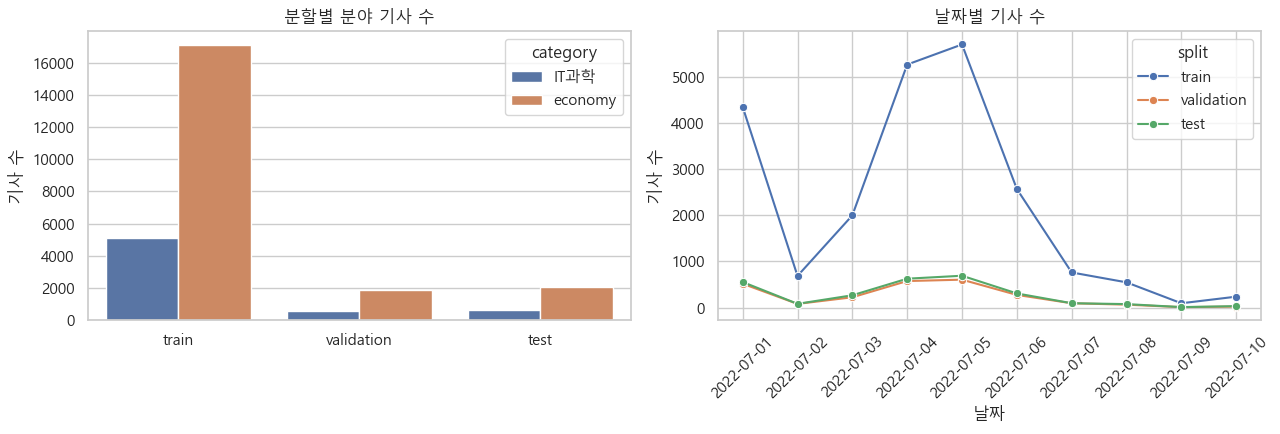

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

category_plot = (
    all_df.groupby(["split", "category"], observed=True)
    .size().rename("count").reset_index()
)
sns.barplot(data=category_plot, x="split", y="count", hue="category",
            order=split_order, ax=axes[0])
axes[0].set_title("분할별 분야 기사 수")
axes[0].set_xlabel("")
axes[0].set_ylabel("기사 수")

date_plot = (
    all_df.assign(day=all_df["date"].dt.date)
    .groupby(["day", "split"], observed=True)
    .size().rename("count").reset_index()
)
sns.lineplot(data=date_plot, x="day", y="count", hue="split",
             hue_order=split_order, marker="o", ax=axes[1])
axes[1].set_title("날짜별 기사 수")
axes[1].set_xlabel("날짜")
axes[1].set_ylabel("기사 수")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(FIGURES / "01_category_date_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. 글자·어절 길이

- 글자 수: Python의 `len()`으로 센 문자 개수
- 어절 수: 공백으로 나눈 덩어리 수
- 압축 비율: 요약 글자 수 ÷ 본문 글자 수

토큰 수와는 다른 값이며, 먼저 데이터의 대략적인 길이와 극단값을 확인하는 용도입니다.

In [19]:
for frame in frames.values():
    frame["document_chars"] = frame["document"].fillna("").str.len()
    frame["summary_chars"] = frame["summary"].fillna("").str.len()
    frame["document_words"] = frame["document"].fillna("").str.split().str.len()
    frame["summary_words"] = frame["summary"].fillna("").str.split().str.len()
    frame["char_compression_ratio"] = (
        frame["summary_chars"] / frame["document_chars"].replace(0, np.nan)
    )

all_df = pd.concat(frames.values(), ignore_index=True)
length_columns = [
    "document_chars", "summary_chars",
    "document_words", "summary_words", "char_compression_ratio"
]
length_summary = (
    all_df.groupby("split")[length_columns]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
)
display(length_summary.round(2))

document_chars                                                \
                    count    mean     std   min     25%    50%      75%   
split                                                                     
test               2740.0   995.7  762.79  49.0  508.00  861.0  1257.25   
train             22194.0   998.6  798.01  29.0  517.00  854.0  1286.75   
validation         2466.0  1016.1  831.85  48.0  515.25  864.5  1302.75   

                                              summary_chars                 \
               90%      95%      99%      max         count    mean    std   
split                                                                        
test        1864.1  2344.05  3728.81   9221.0        2740.0  184.16  91.31   
train       1857.7  2306.35  3734.35  16889.0       22194.0  183.22  81.57   
validation  1867.5  2326.75  3916.75  15384.0        2466.0  180.92  75.62   

                  ... summary_words                      \
             min  ...           90%   95%    99%    max   
split             ...                                     
test        66.0  ...          58.0  67.0  105.0  464.0   
train       59.0  ...          58.0  66.0   99.0  484.0   
validation  60.0  ...          57.0  64.0   96.0  484.0   

           char_compression_ratio                                            \
                            count  mean   std   min   25%   50%   75%   90%   
split                                                                         
test                       2740.0  0.42  1.08  0.02  0.13  0.20  0.35  0.79   
train                     22194.0  0.43  1.10  0.01  0.13  0.21  0.35  0.81   
validation                 2466.0  0.40  0.87  0.01  0.13  0.20  0.34  0.84   

                               
             95%   99%    max  
split                          
test        1.30  2.88  29.17  
train       1.43  3.26  39.00  
validation  1.43  2.66  26.44  

[3 rows x 55 columns]

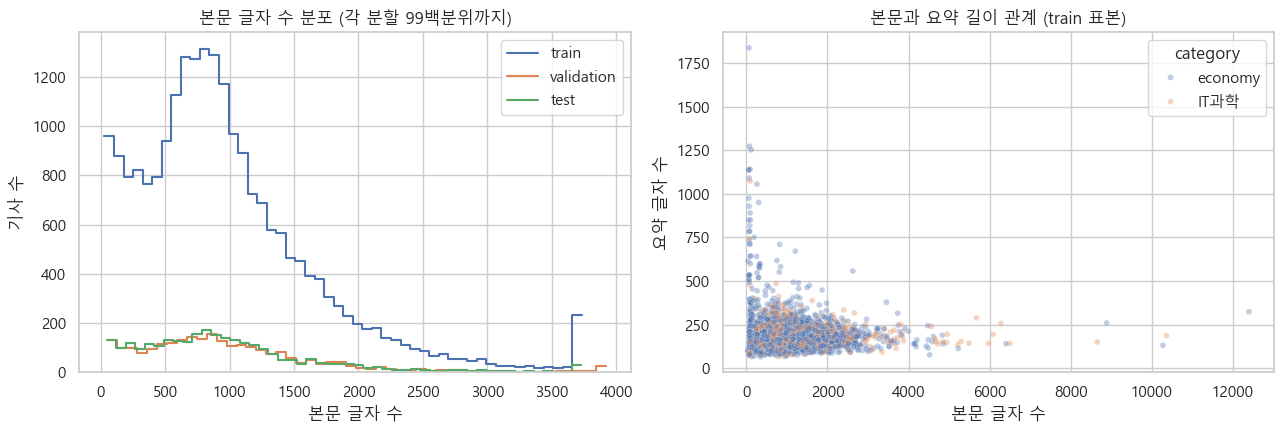

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for split in split_order:
    values = frames[split]["document_chars"].clip(upper=frames[split]["document_chars"].quantile(0.99))
    sns.histplot(values, bins=50, element="step", fill=False, label=split, ax=axes[0])
axes[0].set_title("본문 글자 수 분포 (각 분할 99백분위까지)")
axes[0].set_xlabel("본문 글자 수")
axes[0].set_ylabel("기사 수")
axes[0].legend()

sample_for_scatter = frames["train"].sample(
    min(5000, len(frames["train"])), random_state=SEED
)
sns.scatterplot(
    data=sample_for_scatter, x="document_chars", y="summary_chars",
    hue="category", alpha=0.35, s=18, ax=axes[1]
)
axes[1].set_title("본문과 요약 길이 관계 (train 표본)")
axes[1].set_xlabel("본문 글자 수")
axes[1].set_ylabel("요약 글자 수")

plt.tight_layout()
plt.savefig(FIGURES / "02_character_length_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. KoBART 토큰 길이

실제 KoBART 토크나이저로 모든 본문과 요약의 토큰 수를 셉니다. 여기서는 길이를 측정할 뿐 자르지 않습니다. 512·1024토큰 초과 비율은 이후 입력 길이 실험의 근거가 됩니다.

In [21]:
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID, revision=model_revision, clean_up_tokenization_spaces=False
)

def token_lengths(texts, batch_size=512):
    lengths = []
    texts = texts.fillna("").astype(str).tolist()
    for start in range(0, len(texts), batch_size):
        encoded = tokenizer(
            texts[start:start + batch_size],
            add_special_tokens=True,
            truncation=False,
            return_attention_mask=False,
            return_token_type_ids=False,
            return_length=True,
            verbose=False,
        )
        lengths.extend(encoded["length"])
    return lengths

for split in split_order:
    frame = frames[split]
    frame["document_tokens"] = token_lengths(frame["document"])
    frame["summary_tokens"] = token_lengths(frame["summary"])

all_df = pd.concat(frames.values(), ignore_index=True)
token_stats = []
for split in split_order:
    frame = frames[split]
    token_stats.append({
        "split": split,
        "본문 토큰 중앙값": frame["document_tokens"].median(),
        "본문 토큰 90%": frame["document_tokens"].quantile(0.90),
        "본문 토큰 95%": frame["document_tokens"].quantile(0.95),
        "본문 토큰 99%": frame["document_tokens"].quantile(0.99),
        "본문 최대": frame["document_tokens"].max(),
        "512 초과(건)": frame["document_tokens"].gt(512).sum(),
        "512 초과(%)": frame["document_tokens"].gt(512).mean() * 100,
        "1024 초과(건)": frame["document_tokens"].gt(1024).sum(),
        "1024 초과(%)": frame["document_tokens"].gt(1024).mean() * 100,
        "요약 토큰 중앙값": frame["summary_tokens"].median(),
        "요약 토큰 99%": frame["summary_tokens"].quantile(0.99),
        "요약 최대": frame["summary_tokens"].max(),
    })
token_stats_df = pd.DataFrame(token_stats)
display(token_stats_df.round(2))

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


,split,본문 토큰 중앙값,본문 토큰 90%,본문 토큰 95%,본문 토큰 99%,본문 최대,512 초과(건),512 초과(%),1024 초과(건),1024 초과(%),요약 토큰 중앙값,요약 토큰 99%,요약 최대
0,train,357.0,776.0,970.00,1548.28,6781,6108,27.52,918,4.14,72.0,213.07,510
1,validation,364.5,777.0,975.25,1630.25,6511,718,29.12,102,4.14,71.0,192.35,509
2,test,361.0,771.1,974.20,1578.98,4445,725,26.46,124,4.53,72.0,249.22,509


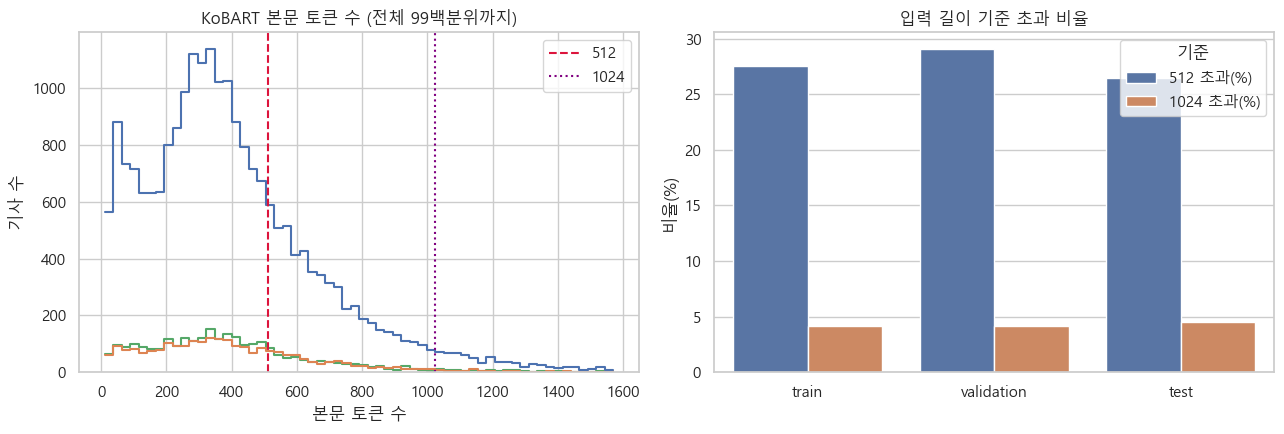

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

plot_tokens = all_df.loc[all_df["document_tokens"] <= all_df["document_tokens"].quantile(0.99)]
sns.histplot(
    data=plot_tokens, x="document_tokens", hue="split",
    hue_order=split_order, bins=60, element="step", fill=False, ax=axes[0]
)
axes[0].axvline(512, color="crimson", linestyle="--", label="512")
axes[0].axvline(1024, color="purple", linestyle=":", label="1024")
axes[0].set_title("KoBART 본문 토큰 수 (전체 99백분위까지)")
axes[0].set_xlabel("본문 토큰 수")
axes[0].set_ylabel("기사 수")
axes[0].legend()

threshold_plot = token_stats_df.melt(
    id_vars="split",
    value_vars=["512 초과(%)", "1024 초과(%)"],
    var_name="기준", value_name="비율"
)
sns.barplot(data=threshold_plot, x="split", y="비율", hue="기준",
            order=split_order, ax=axes[1])
axes[1].set_title("입력 길이 기준 초과 비율")
axes[1].set_xlabel("")
axes[1].set_ylabel("비율(%)")

plt.tight_layout()
plt.savefig(FIGURES / "03_kobart_token_length.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. 각 분할 내부의 정확히 동일한 값

동일 링크·제목·본문·요약이 한 분할 안에 몇 행 있는지 셉니다. `duplicated(keep=False)`는 중복 묶음에 속한 모든 행을 표시합니다.

In [23]:
duplicate_rows = []
for split in split_order:
    frame = frames[split]
    for column in ["link", "title", "document", "summary"]:
        duplicate_rows.append({
            "split": split,
            "기준": column,
            "중복 묶음에 속한 행": int(frame[column].duplicated(keep=False).sum()),
            "첫 행 제외 중복 행": int(frame[column].duplicated(keep="first").sum()),
        })
within_duplicate_df = pd.DataFrame(duplicate_rows)
display(within_duplicate_df)

,split,기준,중복 묶음에 속한 행,첫 행 제외 중복 행
0,train,link,0,0
1,train,title,3082,1815
2,train,document,2834,1907
3,train,summary,2856,1927
4,validation,link,0,0
5,validation,title,68,35
6,validation,document,108,62
7,validation,summary,112,64
8,test,link,0,0
9,test,title,74,37


## 9. 분할 사이의 정확한 중복

같은 내용이 train과 validation/test에 동시에 있으면 모델이 이미 본 기사를 평가받을 수 있습니다. 링크 중복과 내용 중복을 따로 확인합니다. 여기서는 발견만 하고 제거하지 않습니다.

In [24]:
cross_rows = []
for i, left in enumerate(split_order):
    for right in split_order[i + 1:]:
        for column in ["link", "title", "document", "summary"]:
            overlap = set(frames[left][column]) & set(frames[right][column])
            cross_rows.append({
                "left": left,
                "right": right,
                "기준": column,
                "공통 고유값 수": len(overlap),
            })
cross_duplicate_df = pd.DataFrame(cross_rows)
display(cross_duplicate_df.pivot(
    index=["left", "right"], columns="기준", values="공통 고유값 수"
).reset_index())

기준,left,right,document,link,summary,title
0,train,test,274,0,273,331
1,train,validation,259,0,259,332
2,validation,test,79,0,78,78


In [25]:
cross_document_examples = []
for i, left in enumerate(split_order):
    for right in split_order[i + 1:]:
        left_frame = frames[left]
        right_frame = frames[right]
        common_documents = set(left_frame["document"]) & set(right_frame["document"])
        for document in common_documents:
            lrow = left_frame.loc[left_frame["document"].eq(document)].iloc[0]
            rrow = right_frame.loc[right_frame["document"].eq(document)].iloc[0]
            cross_document_examples.append({
                "left": left,
                "right": right,
                "document_sha256": hashlib.sha256(document.encode("utf-8")).hexdigest(),
                "left_title": lrow["title"],
                "right_title": rrow["title"],
                "left_link": lrow["link"],
                "right_link": rrow["link"],
                "document_chars": len(document),
            })

cross_document_examples_df = pd.DataFrame(cross_document_examples)
print("분할 사이 동일 본문 사례:", f"{len(cross_document_examples_df):,}건")
display(cross_document_examples_df.head(10))

분할 사이 동일 본문 사례: 612건


,left,right,document_sha256,left_title,right_title,left_link,right_link,document_chars
0,train,validation,bc1089e830ebd1d88c697eff0eb3abce98daa3efe5ba267d3077f9ec8066c086,오유경 식약처장 규제혁신으로 반도체 활용 의료기기 개발 지원,오유경 식약처장 규제혁신으로 반도체 활용 의료기기 개발 지원,https://n.news.naver.com/mnews/article/421/0006199162?sid=101,https://n.news.naver.com/mnews/article/421/0006199162?sid=105,594
1,train,validation,18dbde4c29b66dde10cd4e8dfb43aadb528c9ea8215c154a0507682f98f087f0,LG U 5G 주파수 품나… SKT·KT 불참 전망,LG U 5G 주파수 품나… SKT·KT 불참 전망,https://n.news.naver.com/mnews/article/014/0004861287?sid=105,https://n.news.naver.com/mnews/article/014/0004861287?sid=101,1352
2,train,validation,c9b0352b1f2ab002633a694c5efc8c0896f03ced6518773bfd83e8bbb50b9b6b,2030 부산세계박람회 유치를 위한 한아세안 만찬,2030 부산세계박람회 유치를 위한 한아세안 만찬,https://n.news.naver.com/mnews/article/001/0013284250?sid=101,https://n.news.naver.com/mnews/article/001/0013284251?sid=101,159
3,train,validation,e1e459763a4f276adf0d3130e77bee8d153f1abc2dd3709c9a13f46dac9ed06b,온라인 반려동물 사료 유해물질 점검,온라인 판매 반려동물 사료 성분·표시 점검,https://n.news.naver.com/mnews/article/001/0013283269?sid=101,https://n.news.naver.com/mnews/article/001/0013283273?sid=101,112
4,train,validation,b242aa497feae0270c4cfec6209f12d0e858bfd1691deb237b0e54612c53120f,우주경제 비전 선포식서 박수치는 윤석열 대통령,박수치는 윤석열 대통령,https://n.news.naver.com/mnews/article/001/0013292982?sid=101,https://n.news.naver.com/mnews/article/001/0013292980?sid=101,75
5,train,validation,9bea8a9f93d67d76b37398c62d43e0af24550c6451691fe9831943f7760bbfed,코빗 상반기 거래 10명 중 6명은 4050…MZ세대 비중 소폭 ↑,코빗 상반기 거래 10명 중 6명은 4050…MZ세대 비중 소폭 ↑,https://n.news.naver.com/mnews/article/243/0000028327?sid=105,https://n.news.naver.com/mnews/article/243/0000028327?sid=101,1427
6,train,validation,97a2bf372cb48594d43792b57efa8d1f7be57d3123edb7963556c57d11cdfc28,모처럼 웃은 코스피 2340선 회복,2340선 회복하며 장 마감한 코스피,https://n.news.naver.com/mnews/article/421/0006198928?sid=101,https://n.news.naver.com/mnews/article/421/0006198929?sid=101,170
7,train,validation,05345a16f1b75eb7790c99c03185a5c2de32e7d1f065f977367d1e71856a60e2,진짜가 돌아왔다,쌍용자동차 토레스 출시,https://n.news.naver.com/mnews/article/079/0003660830?sid=101,https://n.news.naver.com/mnews/article/079/0003660837?sid=101,133
8,train,validation,63be6895559aae875f7718d1456d2787ea4505c192ae77b66841e6d41fd5e0f9,아파트 매매 시장 침체 장기화…중개업소 운영난,아파트 매매 시장 침체 장기화…중개업소 운영난,https://n.news.naver.com/mnews/article/001/0013287665?sid=101,https://n.news.naver.com/mnews/article/001/0013287660?sid=101,138
9,train,validation,3c66977d47569ffebf31780fc63afe0441b0e4d42f472325b1ff2bbda491c716,모다모다 샴푸 위해성 평가 소비자단체가 주도,식약처 논란의 모다모다 샴푸 추가 위해 평가 계획 발표,https://n.news.naver.com/mnews/article/421/0006196161?sid=101,https://n.news.naver.com/mnews/article/421/0006196156?sid=101,264


## 10. train 정답 요약의 노이즈 후보 탐지

자동 규칙은 오류를 확정하지 않고 사람이 읽을 후보를 좁힙니다.

- `repeat_4gram`: 같은 4어절 묶음이 3회 이상 등장
- `low_overlap`: 요약 어절 중 본문에도 등장하는 비율이 30% 미만
- `extreme_ratio`: 요약/본문 글자 비율이 2% 미만 또는 80% 초과
- `summary_longer`: 요약이 본문보다 김

조사와 표현 변화 때문에 정상 요약도 낮은 overlap으로 잡힐 수 있으므로 삭제 전에 반드시 직접 확인해야 합니다.

In [26]:
word_pattern = re.compile(r"[가-힣A-Za-z0-9]+(?:[.,]\d+)?")

def normalized_words(text):
    return word_pattern.findall(str(text).lower())

def repeated_ngram(text, n=4, min_count=3):
    words = normalized_words(text)
    if len(words) < n:
        return False
    counts = Counter(tuple(words[i:i+n]) for i in range(len(words) - n + 1))
    return max(counts.values(), default=0) >= min_count

def overlap_ratio(document, summary):
    document_words = set(normalized_words(document))
    summary_words = normalized_words(summary)
    if not summary_words:
        return np.nan
    return sum(word in document_words for word in summary_words) / len(summary_words)

train_df = frames["train"].copy()
train_df["repeat_4gram"] = train_df["summary"].map(repeated_ngram)
train_df["summary_document_overlap"] = [
    overlap_ratio(document, summary)
    for document, summary in zip(train_df["document"], train_df["summary"])
]
train_df["low_overlap"] = train_df["summary_document_overlap"].lt(0.30)
train_df["extreme_ratio"] = (
    train_df["char_compression_ratio"].lt(0.02)
    | train_df["char_compression_ratio"].gt(0.80)
)
train_df["summary_longer"] = train_df["summary_chars"].gt(train_df["document_chars"])
flag_columns = ["repeat_4gram", "low_overlap", "extreme_ratio", "summary_longer"]
train_df["noise_flag_count"] = train_df[flag_columns].sum(axis=1)

noise_summary_df = pd.DataFrame({
    "규칙": flag_columns,
    "후보 수": [int(train_df[c].sum()) for c in flag_columns],
    "비율(%)": [train_df[c].mean() * 100 for c in flag_columns],
})
display(noise_summary_df.round(2))
print("규칙 하나 이상에 걸린 train 기사:",
      f"{train_df['noise_flag_count'].gt(0).sum():,}건")

,규칙,후보 수,비율(%)
0,repeat_4gram,1121,5.05
1,low_overlap,6,0.03
2,extreme_ratio,2287,10.30
3,summary_longer,1739,7.84


규칙 하나 이상에 걸린 train 기사: 2,484건


In [27]:
candidate_columns = [
    "date", "category", "press", "title", "document", "summary",
    "document_tokens", "summary_tokens", "char_compression_ratio",
    "summary_document_overlap", *flag_columns, "noise_flag_count", "link"
]
noise_candidates_df = (
    train_df.loc[train_df["noise_flag_count"].gt(0), candidate_columns]
    .sort_values(
        ["noise_flag_count", "summary_document_overlap"],
        ascending=[False, True],
        na_position="first",
    )
)
display(noise_candidates_df.head(10))

,date,category,press,title,document,summary,document_tokens,summary_tokens,char_compression_ratio,summary_document_overlap,repeat_4gram,low_overlap,extreme_ratio,summary_longer,noise_flag_count,link
6408,2022-07-05 23:39:55,economy,SBS,경기 화성시 향남읍 200세대 정전…3시간 만에 복구 완료,오늘 5일 저녁 7시 45분 경기 화성시 향남읍에서 전기 공급이 끊겨 3시간 동안 모두 200세대가 불편을 겪었습니다. 한국전력은 최근 이어진 무더위로 인해 전기 사용량이 ...,"화성 향남읍에서 5일 저녁 7시 45분 경기 화성시 향남읍 전기 공급이 끊겨 3시간 동안 모두 200세대가 불편을 겪었는데, 한국전력은 최근 이어진 무더위로 인해 전기 사용...",71,508,6.782353,0.165919,True,True,True,True,4,https://n.news.naver.com/mnews/article/055/0000984031?sid=101
293,2022-07-03 13:10:37,economy,뉴스1,무더위에 냉방 용품 찾는 시민들,서울 뉴스1 송원영 기자 전국적으로 무더위가 지속된 3일 서울 한 대형마트에서 시민들이 냉방용품을 살펴보고 있다.,3일 3일 시민들이 시민들이 냉방 용품을 살펴볼 냉방용품을 살펴보고 있는 모습의 냉방용품 살펴보고 있는 모습의 냉방용품에 대해 송원영 기자의 무더위가 지속된 3일 3일 서울...,25,510,15.476190,0.194245,True,True,True,True,4,https://n.news.naver.com/mnews/article/421/0006193841?sid=101
9154,2022-07-03 13:10:40,economy,뉴스1,선풍기가 필요해,서울 뉴스1 송원영 기자 전국적으로 무더위가 지속된 3일 서울 한 대형마트에서 시민들이 냉방용품을 살펴보고 있다.,3일 3일 시민들이 시민들이 냉방 용품을 살펴볼 냉방용품을 살펴보고 있는 모습의 냉방용품 살펴보고 있는 모습의 냉방용품에 대해 송원영 기자의 무더위가 지속된 3일 3일 서울...,25,510,15.476190,0.194245,True,True,True,True,4,https://n.news.naver.com/mnews/article/421/0006193842?sid=101
15522,2022-07-03 13:10:43,economy,뉴스1,무더위에 냉방 용품 찾는 시민들,서울 뉴스1 송원영 기자 전국적으로 무더위가 지속된 3일 서울 한 대형마트에서 시민들이 냉방용품을 살펴보고 있다.,3일 3일 시민들이 시민들이 냉방 용품을 살펴볼 냉방용품을 살펴보고 있는 모습의 냉방용품 살펴보고 있는 모습의 냉방용품에 대해 송원영 기자의 무더위가 지속된 3일 3일 서울...,25,510,15.476190,0.194245,True,True,True,True,4,https://n.news.naver.com/mnews/article/421/0006193843?sid=101
17433,2022-07-03 13:10:59,economy,뉴스1,선풍기가 필요해,서울 뉴스1 송원영 기자 전국적으로 무더위가 지속된 3일 서울 한 대형마트에서 시민들이 냉방용품을 살펴보고 있다.,3일 3일 시민들이 시민들이 냉방 용품을 살펴볼 냉방용품을 살펴보고 있는 모습의 냉방용품 살펴보고 있는 모습의 냉방용품에 대해 송원영 기자의 무더위가 지속된 3일 3일 서울...,25,510,15.476190,0.194245,True,True,True,True,4,https://n.news.naver.com/mnews/article/421/0006193845?sid=101
21691,2022-07-05 16:36:04,economy,매일경제,포토 금감원장 여신금융 CEO들과 간담회 개최,이복현 금융감독원장이 5일 오전 서울 중구 여신금융협회에서 열린 여신전문금융사 최고경영자 간담회에서 발언하고 있다. 5일 오전 서울 중구 여신금융협회에서 열린 여신전문금융사...,5일 여신전문금융협회에서 열린 여신전문금융사 최고경영자 간담회에서 이복현 금융감독원장이 이복현 금융감독원장의 이복현 금융감독원장의 발언을 듣고 이복현 금융감독원장의 발언 발...,54,509,9.613139,0.201657,True,True,True,True,4,https://n.news.naver.com/mnews/article/009/0004987165?sid=101
12211,2022-07-05 11:23:16,economy,연합뉴스,이임하는 고승범 금융위원장,서울 연합뉴스 김승두 기자 고승범 금융위원장이 5일 정부서울청사에서 열린 이임식에서 이임사를 하고 있다.,"5일 정부서울청사에서 열린 이임식에서 고승범 금융위원장이 5일 정부서울청사에서 열린 이임식에서 이임사를 했으며, 5일 정부서울청사에서 열린 이임식에서는 고승범 금융위원장이 ...",25,509,19.603448,0.310241,True,False,True,True,3,https://n.news.naver.com/mnews/article/001/0013289309?sid=101
20614,2022-07-05 11:25:13,economy,연합뉴스,이임사 하는 고승범 금융위원장,서울 연합뉴스 김승두 기자 고승범 금융위원장이 5일 정부서울청사에서 열린 이임식에서 이임사를 하고 있다.,"5일 정부서울청사에서 열린 이임식에서 고승범 금융위원장이 5일 정부서울청사에서 열린 이임식에서 이임사를 했으며, 5일 정부서울청사에서 열린 이임식에서는 고승범 금융위원장이 ...",25,509,19.603448,0.310241,True,False,True,True,3,https://n.news.naver.com/mnews/article/001/0013289335?sid=101
21450,2022-07-05 11:21:11,economy,연합뉴스,이임하는 고승범 금융위원장,서울 연합뉴스 김승두 기자 고승범 금융위원장이 5일 정부서울청사에서 열린 이임식에서 이임사를 하고 있다.,"5일 정부서울청사에서 열린 이임식에서 고승범 금융위원장이 5일 정부서울청사에서 열린 이임식에서 이임사를 했으며, 5일 정부서울청사에서 열린 이임식에서는 고승범 금융위원장이 ...",25,509,19.603448,0.310241,True,False,True,True,3,https://n.news.naver.com/mnews/article/001/0013289301?sid=101
10154,2022-07-03 14:28:11,economy,연합뉴스,비상경제장관회의 참석하는 추경호 부총리,서울 연합뉴스 김승두 기자 추경호 경제부총리 겸 기획재정부 장관이 3일 정부서울청사에서 열린 제3차 비상경제장관회의에 참석하고 있다.,3일 정부서울청사에서 추경호 경제부총리 겸 기획재정부 장관이 정부서울청사에서 열린 제3차 비상경제장관회의에 추경호 경제부총리 겸 기획재정부 장관 3일 정부서울청사에서 추경호...,28,509,17.202703,0.339196,True,False,True,True,3,https://n.news.naver.com/mnews/article/001/0013285359?sid=101


## 11. 결과 저장

통계표, 중복 사례, 노이즈 후보와 그래프를 저장합니다. 원본 데이터는 변경하지 않습니다.

In [28]:
# 각 행의 길이 분석 결과는 이후 전처리와 표본 추출에 재사용합니다.
length_rows = []
for split in split_order:
    temp = frames[split][[
        "date", "category", "press", "title", "link",
        "document_chars", "summary_chars",
        "document_words", "summary_words",
        "document_tokens", "summary_tokens",
        "char_compression_ratio",
    ]].copy()
    temp.insert(0, "split", split)
    length_rows.append(temp)
length_rows_df = pd.concat(length_rows, ignore_index=True)

quality_df.to_csv(RESULTS / "missing_empty_summary.csv", index=False, encoding="utf-8-sig")
split_profile_df.to_csv(RESULTS / "split_profile.csv", index=False, encoding="utf-8-sig")
token_stats_df.to_csv(RESULTS / "token_length_summary.csv", index=False, encoding="utf-8-sig")
within_duplicate_df.to_csv(RESULTS / "within_split_duplicates.csv", index=False, encoding="utf-8-sig")
cross_duplicate_df.to_csv(RESULTS / "cross_split_duplicate_counts.csv", index=False, encoding="utf-8-sig")
cross_document_examples_df.to_csv(
    RESULTS / "cross_split_document_examples.csv", index=False, encoding="utf-8-sig"
)
noise_summary_df.to_csv(RESULTS / "noise_candidate_summary.csv", index=False, encoding="utf-8-sig")
try:
    noise_candidates_df.to_csv(RESULTS / "train_noise_candidates.csv", index=False, encoding="utf-8-sig")
except PermissionError:
    fallback = RESULTS / "train_noise_candidates_latest.csv"
    noise_candidates_df.to_csv(fallback, index=False, encoding="utf-8-sig")
    print("기존 CSV가 열려 있어 새 파일로 저장:", fallback)
length_rows_df.to_csv(RESULTS / "article_length_features.csv", index=False, encoding="utf-8-sig")

run_summary = {
    "dataset": DATASET_ID,
    "dataset_revision": dataset_revision,
    "model_tokenizer": MODEL_ID,
    "model_revision": model_revision,
    "split_counts": {split: len(frames[split]) for split in split_order},
    "missing_total": int(quality_df["missing"].sum()),
    "empty_total": int(quality_df["empty"].sum()),
    "token_stats": token_stats_df.to_dict(orient="records"),
    "within_split_duplicates": within_duplicate_df.to_dict(orient="records"),
    "cross_split_duplicates": cross_duplicate_df.to_dict(orient="records"),
    "noise_candidate_summary_train": noise_summary_df.to_dict(orient="records"),
    "notes": [
        "원본 행을 삭제하거나 수정하지 않음",
        "노이즈 규칙은 검토 후보이며 오류 확정이 아님",
        "test 정답을 모델/하이퍼파라미터 선택에 사용하지 않음",
    ],
}
(RESULTS / "eda_run_summary.json").write_text(
    json.dumps(run_summary, ensure_ascii=False, indent=2, default=str),
    encoding="utf-8",
)

print("저장 완료:", RESULTS)
for path in sorted(RESULTS.rglob("*")):
    if path.is_file():
        print("-", path.relative_to(PROJECT))

저장 완료: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\01_data_eda
- results\01_data_eda\article_length_features.csv
- results\01_data_eda\cross_split_document_examples.csv
- results\01_data_eda\cross_split_duplicate_counts.csv
- results\01_data_eda\duplicate_relationship_rows.csv
- results\01_data_eda\duplicate_relationship_summary.csv
- results\01_data_eda\eda_run_summary.json
- results\01_data_eda\extreme_pair_examples.csv
- results\01_data_eda\figures\01_category_date_distribution.png
- results\01_data_eda\figures\02_character_length_distribution.png
- results\01_data_eda\figures\03_kobart_token_length.png
- results\01_data_eda\figures\04_document_summary_pair_coverage.png
- results\01_data_eda\figures\05_lead_bias.png
- results\01_data_eda\figures\06_press_distribution.png
- results\01_data_eda\figures\07_duplicate_relationships.png
- results\01_data_eda\lead_bias_summary.csv
- results\01_data_eda\missing_empty_summary.csv
- results\01_data_eda\noise_candidate_summary.cs

## 12. 기본 분석의 중간 정리

이 노트북에서 확인한 수치를 근거로 다음 단계에서 결정합니다.

1. 512토큰 초과 비율을 근거로 512와 1024 입력 길이를 비교할지 결정합니다.
2. 동일 본문이 분할 사이에 존재하므로, 원본 분할 베이스라인과 중복·유사 기사 그룹 분할을 별도 실험으로 비교합니다.
3. 자동 노이즈 후보를 사람이 읽고 실제 오류 여부를 확인합니다.
4. 전처리 규칙을 확정하기 전에는 원본 행을 삭제하지 않습니다.
5. 모델 설정은 validation으로 선택하고, test는 최종 평가에만 사용합니다.

## 13. document–summary 쌍의 내용 일치도

요약의 개별 어절(unigram)과 연속 2·3어절 묶음이 본문에도 등장하는 비율을 계산합니다. 값이 높으면 본문 표현을 많이 가져온 추출형 성격이 강합니다. 값이 낮으면 표현을 바꾼 생성형 요약이거나 잘못 연결된 정답일 수 있으므로 사례 확인이 필요합니다.
- coverage : 원문과 요약이 표현을 얼마나 공유하는가?
- novel_unigram_coverage : 원문에 없던 표현이 얼마나 나왔는가?

In [29]:
def ngram_coverage(document, summary, n=1):
    document_words = normalized_words(document)
    summary_words = normalized_words(summary)
    if len(summary_words) < n:
        return np.nan
    document_ngrams = {tuple(document_words[i:i+n]) for i in range(len(document_words)-n+1)}
    summary_ngrams = [tuple(summary_words[i:i+n]) for i in range(len(summary_words)-n+1)]
    return sum(g in document_ngrams for g in summary_ngrams) / len(summary_ngrams)

for size, column in [(1, "unigram_coverage"), (2, "bigram_coverage"), (3, "trigram_coverage")]:
    train_df[column] = [
        ngram_coverage(document, summary, size)
        for document, summary in zip(train_df["document"], train_df["summary"])
    ]
train_df["novel_unigram_ratio"] = 1 - train_df["unigram_coverage"]

pair_columns = ["char_compression_ratio", "unigram_coverage", "bigram_coverage",
                "trigram_coverage", "novel_unigram_ratio"]
pair_quality_summary_df = train_df[pair_columns].describe(
    percentiles=[.01, .05, .25, .5, .75, .95, .99]
).T
display(pair_quality_summary_df.round(3))

display(train_df[["document_tokens", "summary_tokens", *pair_columns]]
        .corr(method="spearman").round(3))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
char_compression_ratio,22194.0,0.426,1.101,0.007,0.040,0.068,0.130,0.206,0.350,1.435,3.264,39.000
unigram_coverage,22194.0,0.912,0.059,0.166,0.714,0.805,0.889,0.925,0.951,0.976,1.000,1.000
bigram_coverage,22194.0,0.799,0.104,0.000,0.455,0.608,0.750,0.821,0.872,0.922,0.947,1.000
trigram_coverage,22194.0,0.708,0.135,0.000,0.286,0.452,0.636,0.733,0.806,0.879,0.912,1.000
novel_unigram_ratio,22194.0,0.088,0.059,0.000,0.000,0.024,0.049,0.075,0.111,0.195,0.286,0.834


,document_tokens,summary_tokens,char_compression_ratio,unigram_coverage,bigram_coverage,trigram_coverage,novel_unigram_ratio
document_tokens,1.000,0.048,-0.909,0.031,0.039,0.045,-0.031
summary_tokens,0.048,1.000,0.309,0.308,0.413,0.438,-0.308
char_compression_ratio,-0.909,0.309,1.000,0.095,0.133,0.137,-0.095
unigram_coverage,0.031,0.308,0.095,1.000,0.826,0.752,-1.000
bigram_coverage,0.039,0.413,0.133,0.826,1.000,0.976,-0.826
trigram_coverage,0.045,0.438,0.137,0.752,0.976,1.000,-0.752
novel_unigram_ratio,-0.031,-0.308,-0.095,-1.000,-0.826,-0.752,1.000


ㄴ> 스피어만 상관: 얼마나 비례하는가

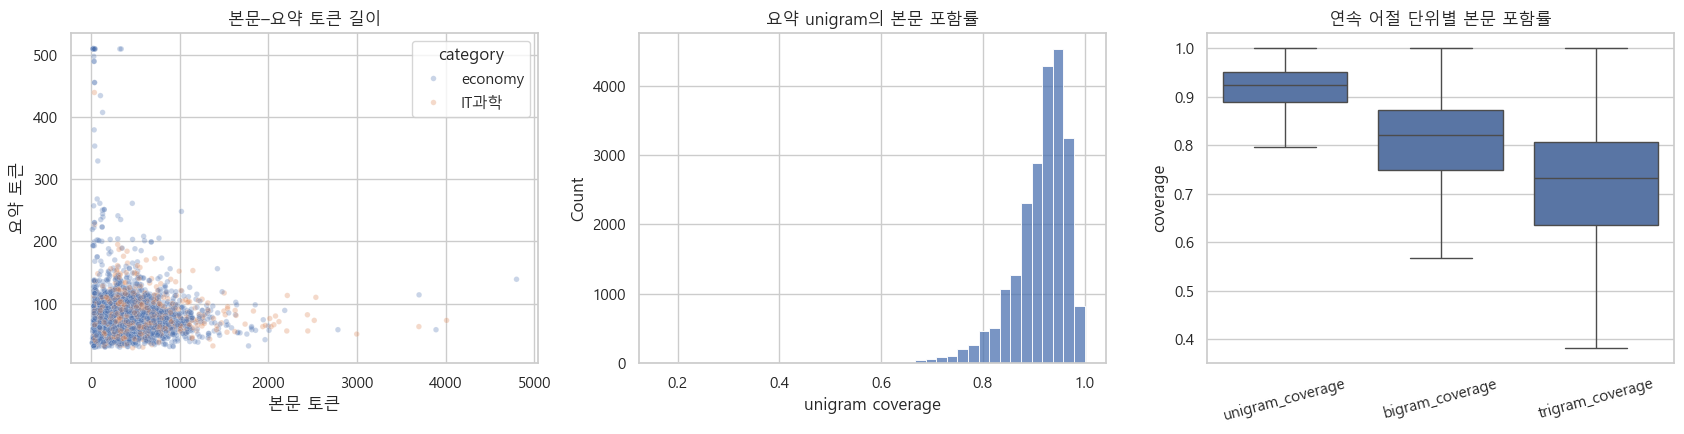

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
pair_sample = train_df.sample(min(5000, len(train_df)), random_state=SEED)
sns.scatterplot(data=pair_sample, x="document_tokens", y="summary_tokens",
                hue="category", alpha=.3, s=16, ax=axes[0])
axes[0].set(title="본문–요약 토큰 길이", xlabel="본문 토큰", ylabel="요약 토큰")
sns.histplot(train_df["unigram_coverage"], bins=40, color="#4c72b0", ax=axes[1])
axes[1].set(title="요약 unigram의 본문 포함률", xlabel="unigram coverage")
coverage_long = train_df[["unigram_coverage", "bigram_coverage", "trigram_coverage"]].melt(
    var_name="단위", value_name="coverage")
sns.boxplot(data=coverage_long, x="단위", y="coverage", showfliers=False, ax=axes[2])
axes[2].set(title="연속 어절 단위별 본문 포함률", xlabel="", ylabel="coverage")
axes[2].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig(FIGURES / "04_document_summary_pair_coverage.png", dpi=160, bbox_inches="tight")
plt.show()

## 14. 숫자·금액·날짜 불일치 후보

요약의 숫자가 본문에 없으면 정답 사실 오류나 다른 기사 요약일 가능성이 있습니다. 쉼표·소수점 표기를 단순 정규화하며, 한글 단위 차이는 완전히 처리하지 못하므로 자동 삭제가 아닌 검토 후보로 사용합니다.

In [31]:
number_pattern = re.compile(r"\d+(?:[,.]\d+)*")

def normalized_numbers(text):
    return {v.replace(",", "").rstrip(".") for v in number_pattern.findall(str(text))}

def unsupported_summary_numbers(document, summary):
    return sorted(normalized_numbers(summary) - normalized_numbers(document))

train_df["unsupported_numbers"] = [
    unsupported_summary_numbers(d, s)
    for d, s in zip(train_df["document"], train_df["summary"])
]
train_df["number_mismatch_candidate"] = train_df["unsupported_numbers"].str.len().gt(0)
number_mismatch_summary_df = (
    train_df.groupby("category")["number_mismatch_candidate"].agg(["sum", "count", "mean"])
    .rename(columns={"sum": "후보 수", "count": "전체 수", "mean": "후보 비율(%)"})
)
number_mismatch_summary_df["후보 비율(%)"] *= 100
display(number_mismatch_summary_df.round(2))

number_mismatch_examples_df = train_df.loc[
    train_df["number_mismatch_candidate"],
    ["date", "category", "press", "title", "document", "summary",
     "unsupported_numbers", "link"]
].copy()
display(number_mismatch_examples_df.head(10))

,후보 수,전체 수,후보 비율(%)
category,,,
IT과학,73,5106,1.43
economy,296,17088,1.73


,date,category,press,title,document,summary,unsupported_numbers,link
43,2022-07-05 18:18:04,economy,파이낸셜뉴스,근로복지공단 부산의원 개원…산재 맞춤재활서비스,근로복지공단은 부산·경상권의 산재노동자들이 보다 가까운 곳에서 전문재활서비스를 받을 수 있도록 부산진구 범천동에 근로복지공단 부산의원 사진 을 설치하고 5일 개원식을 개최했...,근로복지공단은 5일 부산진구 범천동에 근로복지공단 부산의원 사진 을 설치하고 5일 개원식을 개최했다고 밝혔으며 근로복지공단 부산의원 은 신체 회복을 통한 직업 및 사회복귀 ...,[2],https://n.news.naver.com/mnews/article/014/0004862782?sid=101
61,2022-07-06 18:10:04,economy,파이낸셜뉴스,코웨이 취약계층 주거 실내환경 진단해준다,환경부 등과 환경성질환 예방협약 지난 5일 한두원 코웨이 AirCare필터개발팀장 유제철 환경부 차관 이우원 한국환경산업기술원장 직무대행 왼쪽부터 이 기념촬영을 하고 있다....,68년부터 5년 연속 환경성질환 예방사업에 동참하고 있는 코웨이가 취약계층의 실내환경 유해인자를 진단하고 주거시설을 개선하는 사업을 진행하기 위해 6일 환경부 및 한국환경산...,[68],https://n.news.naver.com/mnews/article/014/0004863400?sid=101
92,2022-07-03 21:57:08,economy,KBS,충북 인적자원개발위 청년 구직자 디지털 교육 지원,KBS 청주 충북 인적자원개발위원회가 20 30대 청년 구직자의 디지털 실무 능력을 높이기 위한 교육을 진행합니다. 교육 내용은 인공지능을 활용한 소프트웨어 개발과 빅데이터...,KBS 청주 충북 인적자원개발위원회가 2030세대 구직자의 디지털 실무 능력을 향상시키기 위해 인공지능을 활용한 소프트웨어 개발과 빅데이터 응용으로 한국직업개발원과 한국 I...,[2030],https://n.news.naver.com/mnews/article/056/0011295143?sid=101
253,2022-07-03 17:58:03,IT과학,파이낸셜뉴스,MZ세대 공략 위해… 침체장에도 식지 않는 명품들의 블록체인 사랑,구찌·브라이틀링·페레가모·불가리 가상자산 결제 허용·NFT 발행 최근 가상자산 시장 침체에도 불구하고 구찌나 페라가모 불가리 위블로 브라이틀링 등 명품 브랜드들이 속속 가상...,20 가상자산 시장이 2030 젊은층이 주도하고 있는 가운데 이탈리아 명품 브랜드 구찌 GUCCI가 슈퍼래어 SuperRare 의 가상자산 RARE를 약 3236만5000원...,[20],https://n.news.naver.com/mnews/article/014/0004861308?sid=105
293,2022-07-03 13:10:37,economy,뉴스1,무더위에 냉방 용품 찾는 시민들,서울 뉴스1 송원영 기자 전국적으로 무더위가 지속된 3일 서울 한 대형마트에서 시민들이 냉방용품을 살펴보고 있다.,3일 3일 시민들이 시민들이 냉방 용품을 살펴볼 냉방용품을 살펴보고 있는 모습의 냉방용품 살펴보고 있는 모습의 냉방용품에 대해 송원영 기자의 무더위가 지속된 3일 3일 서울...,[7],https://n.news.naver.com/mnews/article/421/0006193841?sid=101
315,2022-07-08 13:14:01,IT과학,동아일보,김 소장의 ‘핏FIT’ 고인의 모습과 고인의 목소리 당신의 추억 방법은,시대의 흐름은 너무나도 빠르게 우리가 상상하던 미래의 모습을 향해 달려가고 있습니다. 때로는 그 속도의 차이가 분야마다 너무 커서 어떤 장단에 맞추어 살아야 할지 고민되고 ...,201 2022년 6월 23일 현지시간 아마존이 미국 라스베이거스에서 개최된 리 마스 re MARS 컨퍼런스에서 AI 음성인식 서비스 ‘알렉사 Alexa ’를 통해 생을 떠...,[201],https://n.news.naver.com/mnews/article/020/0003438915?sid=105
338,2022-07-06 18:15:01,IT과학,한국경제,허준이 교수 고교때부터 수학 집중…사실 수포자는 아니었죠,수학계 노벨상 필즈상 받은 허준이 교수 기자 간담회 순수 수학 강의 듣고 수학에 푹 아직도 헤어나질 못하고 있어 아내 수상 소식에 될 줄 알았어 제2 3 필즈상 수상자 나오...,허준이 한국고등과학원 석학교수 미국 프린스턴대 교수·39 는 6일 서울 역삼동 한국과학기술회관에서 열린 기자간담회에 온라인으로 참석해 ‘수학계의 노벨상’으로 알려진 필즈상 ...,[23],https://n.news.naver.com/mnews/article/015/0004721217?sid=105
393,2022-07-01 23:35:34,economy,머니투데이,현대차 노조 71.8% 파업 찬성...4년만에 파업 벌어질까,서울 뉴시스 김진아 기자 전국금속노동조합 현대차그룹사 노조원들이 26일 오전 서울 서초구 현대기아자동차 본사 앞에서 ‘현대기아그룹사 차별적 가이드라인 분쇄 격려금 동일지급 ...,20차그룹사 노조원들이 26일 오전 서울 서초구 현대기아자동차 본사 앞에서 ‘현대기아그룹사 차별적 가이드라인 분쇄 격려금 동일지급 쟁취 그룹사 공동투쟁 선포 기자회견’을 하...,[20],https://n.news.naver.com/mnews/article/008/0004765955?sid=101
461,2022-07-04 07:55:02,IT과학,스포츠조선,올 상반기 게임사 주가 반토막 속출한 이유는,2022년 상반기 게임사들의 주가는 직격탄 을 맞았다. 코로나19 엔데믹 전환 이후 글로벌 긴축과 경기 침체 우려 우크라이나 전쟁발 급격한 인플레이션 등 엄청난 위기 속에서...,202년 상반기 게임사들의 주가는 코로나19 엔데믹 전환 이후 글로벌 긴축과 경기 침체 우려 우크라이나 전쟁발 급격한 인플레이션 등 엄청난 위기 속에서 다른 나라에 비해 코...,[202],https://n.news.naver.com/mnews/article/076/0003888487?sid=105
463,2022-07-09 07:30:00,IT과학,뉴시스,내달 3일 달로 떠나는 韓 다누리호…맡겨진 임무는,기사내용 요약 미국 발사장로 이송 완료 후 발사 준비 중 내달 3일 스페이스X 팰콘9로 우주行…세계 7번째 달 탐사국 등극 기대↑ 12월 달 상공 100Km 임무궤도 안착 ...,859년 러시아 구 소련가 세계 최초로 달에 무인 우주선을 보냈고 1969년 미국의 닐 암스트롱이 인류 최초로 달을 밟을 때만 해도 세계 최빈국이었던 우리나라가 50 60여...,[859],https://n.news.naver.com/mnews/article/003/0011294695?sid=105


## 15. 기사 앞부분 편향

정답 요약 어절이 본문의 앞 10%, 25%, 50%와 전체에서 얼마나 발견되는지 비교합니다. 앞부분 포함률은 Lead 베이스라인과 긴 본문 자르기 방식의 근거가 됩니다.

,본문 범위,평균 coverage,중앙값 coverage
0,앞 10%,0.246,0.211
1,앞 25%,0.532,0.524
2,앞 50%,0.737,0.822
3,앞 100%,0.912,0.925


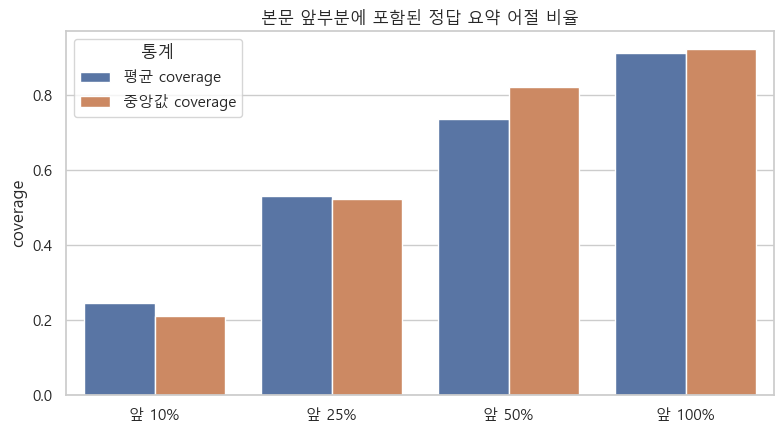

In [32]:
def prefix_word_coverage(document, summary, fraction):
    document_words = normalized_words(document)
    summary_words = normalized_words(summary)
    if not document_words or not summary_words:
        return np.nan
    size = max(1, int(np.ceil(len(document_words) * fraction)))
    prefix = set(document_words[:size])
    return sum(word in prefix for word in summary_words) / len(summary_words)

lead_columns = {}
for fraction in [.10, .25, .50, 1.00]:
    column = f"prefix_{int(fraction*100)}_coverage"
    train_df[column] = [
        prefix_word_coverage(d, s, fraction)
        for d, s in zip(train_df["document"], train_df["summary"])
    ]
    lead_columns[f"앞 {int(fraction*100)}%"] = column

lead_bias_summary_df = pd.DataFrame({
    "본문 범위": list(lead_columns),
    "평균 coverage": [train_df[c].mean() for c in lead_columns.values()],
    "중앙값 coverage": [train_df[c].median() for c in lead_columns.values()],
})
display(lead_bias_summary_df.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=lead_bias_summary_df.melt(
    id_vars="본문 범위", var_name="통계", value_name="coverage"),
    x="본문 범위", y="coverage", hue="통계", ax=ax)
ax.set(title="본문 앞부분에 포함된 정답 요약 어절 비율", xlabel="", ylabel="coverage")
plt.tight_layout()
plt.savefig(FIGURES / "05_lead_bias.png", dpi=160, bbox_inches="tight")
plt.show()

## 16. TF-IDF 기반 유사 기사 후보

수업에서 배운 TF-IDF로 제목의 unigram·bigram 벡터를 만들고 가까운 제목을 찾습니다. 코사인 유사도 0.8 이상은 같은 사건 후보이며, 실제 그룹 확정 전 사람이 확인해야 합니다.

In [33]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors

similarity_source_df = all_df[["split", "date", "category", "press", "title", "link"]].reset_index(drop=True)
title_vectorizer = TfidfVectorizer(
    token_pattern=r"(?u)\b\w+\b", ngram_range=(1, 2),
    min_df=2, max_features=50_000, sublinear_tf=True)
title_matrix = title_vectorizer.fit_transform(similarity_source_df["title"].fillna(""))
neighbors = NearestNeighbors(n_neighbors=4, metric="cosine", algorithm="brute", n_jobs=-1)
distances, indices = neighbors.fit(title_matrix).kneighbors(title_matrix)

pairs = {}
for left_index, (row_distances, row_indices) in enumerate(zip(distances, indices)):
    for distance, right_index in zip(row_distances[1:], row_indices[1:]):
        similarity = 1 - float(distance)
        if similarity >= .80 and left_index != right_index:
            pair = tuple(sorted((left_index, int(right_index))))
            pairs[pair] = max(pairs.get(pair, 0), similarity)

similar_rows = []
for (li, ri), similarity in pairs.items():
    left, right = similarity_source_df.iloc[li], similarity_source_df.iloc[ri]
    if left["link"] == right["link"]:
        continue
    similar_rows.append({
        "similarity": similarity, "left_index": li, "right_index": ri,
        "left_split": left["split"], "right_split": right["split"],
        "cross_split": left["split"] != right["split"],
        "left_title": left["title"], "right_title": right["title"],
        "left_press": left["press"], "right_press": right["press"],
        "left_link": left["link"], "right_link": right["link"],
    })

similar_title_candidates_df = pd.DataFrame(similar_rows).sort_values(
    "similarity", ascending=False).reset_index(drop=True)
print("유사 제목 후보 쌍:", f"{len(similar_title_candidates_df):,}")
print("분할 사이 후보 쌍:", f"{similar_title_candidates_df['cross_split'].sum():,}")
display(similar_title_candidates_df.tail())

유사 제목 후보 쌍: 7,769
분할 사이 후보 쌍: 2,536


,similarity,left_index,right_index,left_split,right_split,cross_split,left_title,right_title,left_press,right_press,left_link,right_link
7764,0.800128,9196,24415,train,validation,True,이마트24 타이포그래픽 디자인을 강조한 ‘아임e 스낵’ 판매,이마트24 타이포그래픽 강조한 아임e 스낵 출시,데일리안,뉴시스,https://n.news.naver.com/mnews/article/119/0002618157?sid=101,https://n.news.naver.com/mnews/article/003/0011285406?sid=101
7765,0.800039,14093,20364,train,train,False,드론인재양성 2022서울드론 아카데미 개소,메타버스 아카데미 개소,한국경제TV,전자신문,https://n.news.naver.com/mnews/article/215/0001040612?sid=101,https://n.news.naver.com/mnews/article/030/0003028275?sid=105
7766,0.800030,3741,17821,train,train,False,우리은행 마스크 업사이클링 작품 전시회 개최,우리은행 6일까지 마스크 업사이클링 작품 전시회,데일리안,머니투데이,https://n.news.naver.com/mnews/article/119/0002617389?sid=101,https://n.news.naver.com/mnews/article/008/0004765821?sid=101
7767,0.800030,17821,21231,train,train,False,우리은행 6일까지 마스크 업사이클링 작품 전시회,우리은행 마스크 업사이클링 작품 전시회 개최,머니투데이,연합뉴스,https://n.news.naver.com/mnews/article/008/0004765821?sid=101,https://n.news.naver.com/mnews/article/001/0013283350?sid=101
7768,0.800030,1551,17821,train,train,False,우리은행 마스크 업사이클링 작품 전시회 개최,우리은행 6일까지 마스크 업사이클링 작품 전시회,뉴시스,머니투데이,https://n.news.naver.com/mnews/article/003/0011279495?sid=101,https://n.news.naver.com/mnews/article/008/0004765821?sid=101


## 17. 언론사 편중과 텍스트 품질

특정 언론사의 과대표집 여부와 URL·이메일·저작권 문구·연속 공백·매우 짧은 기사 빈도를 확인합니다.

split,train,validation,test,total,전체 비율(%)
press,,,,,
연합뉴스,2060,209,260,2529,9.23
뉴스1,1787,202,221,2210,8.07
뉴시스,1662,187,215,2064,7.53
이데일리,1278,159,156,1593,5.81
파이낸셜뉴스,961,123,116,1200,4.38
머니투데이,825,89,101,1015,3.70
한국경제,832,70,107,1009,3.68
아시아경제,815,71,92,978,3.57
서울경제,715,67,80,862,3.15


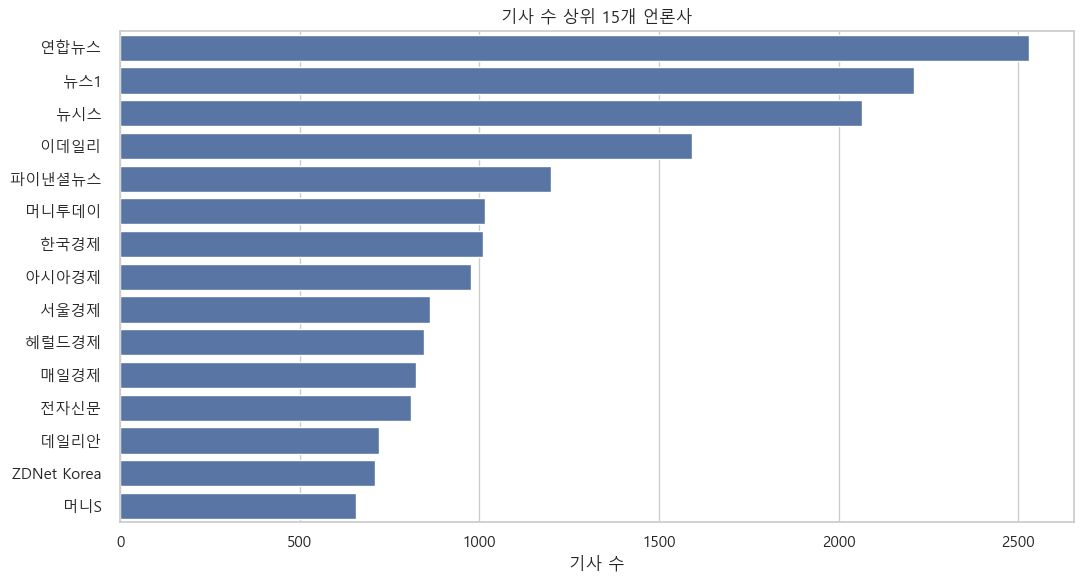

In [34]:
press_counts_df = (all_df.groupby(["press", "split"], observed=True).size()
                   .unstack(fill_value=0).reindex(columns=split_order, fill_value=0))
press_counts_df["total"] = press_counts_df.sum(axis=1)
press_counts_df["전체 비율(%)"] = press_counts_df["total"] / len(all_df) * 100
press_counts_df = press_counts_df.sort_values("total", ascending=False)
display(press_counts_df.head(20).round(2))

fig, ax = plt.subplots(figsize=(11, 6))
top_press = press_counts_df.head(15).reset_index()
sns.barplot(data=top_press, y="press", x="total", color="#4c72b0", ax=ax)
ax.set(title="기사 수 상위 15개 언론사", xlabel="기사 수", ylabel="")
plt.tight_layout()
plt.savefig(FIGURES / "06_press_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

In [35]:
quality_patterns = {
    "URL 포함": re.compile(r"https?://|www\.", re.I),
    "이메일 포함": re.compile(r"[\w.+-]+@[\w.-]+\.\w+", re.I),
    "저작권/재배포 문구": re.compile(r"무단전재|재배포\s*금지|저작권자|copyright", re.I),
    "연속 공백": re.compile(r"\s{2,}"),
    "기자 표현": re.compile(r"[가-힣]{2,4}\s*기자"),
}
text_quality_rows = []
for split in split_order:
    frame = frames[split]
    documents = frame["document"].fillna("").astype(str)
    for name, pattern in quality_patterns.items():
        mask = documents.str.contains(pattern, regex=True)
        text_quality_rows.append({"split": split, "패턴": name,
                                  "건수": int(mask.sum()), "비율(%)": mask.mean()*100})
    short_mask = frame["document_words"].lt(30)
    text_quality_rows.append({"split": split, "패턴": "30어절 미만 본문",
                              "건수": int(short_mask.sum()), "비율(%)": short_mask.mean()*100})
text_quality_summary_df = pd.DataFrame(text_quality_rows)
display(text_quality_summary_df.pivot(index="패턴", columns="split", values="건수")
        .reindex(columns=split_order))

split,train,validation,test
패턴,,,
30어절 미만 본문,1292,140,142
URL 포함,62,6,15
기자 표현,9259,1035,1144
연속 공백,0,0,0
이메일 포함,0,0,0
저작권/재배포 문구,25,1,0


## 18. 극단값과 의심 쌍 직접 확인

긴·짧은 본문, 긴 요약, 낮은 내용 일치도, 반복 요약과 숫자 불일치 사례를 원문·정답 쌍으로 저장합니다.

In [36]:
review_sets = []
def add_review_set(label, frame):
    temp = frame.copy()
    temp.insert(0, "review_reason", label)
    review_sets.append(temp)

base_review = ["date", "category", "press", "title", "document", "summary", "link",
               "document_tokens", "summary_tokens", "char_compression_ratio"]
add_review_set("가장 긴 본문", train_df.nlargest(5, "document_tokens")[base_review])
add_review_set("가장 짧은 본문", train_df.nsmallest(5, "document_tokens")[base_review])
add_review_set("가장 긴 요약", train_df.nlargest(5, "summary_tokens")[base_review])
add_review_set("가장 낮은 unigram coverage",
               train_df.nsmallest(10, "unigram_coverage")[
                   base_review + ["unigram_coverage", "bigram_coverage", "trigram_coverage"]])
add_review_set("반복 요약", train_df.loc[train_df["repeat_4gram"]]
               .sort_values("summary_tokens", ascending=False).head(10)[base_review + ["repeat_4gram"]])
add_review_set("숫자 불일치 후보", train_df.loc[train_df["number_mismatch_candidate"]]
               .head(10)[base_review + ["unsupported_numbers"]])
extreme_pair_examples_df = pd.concat(review_sets, ignore_index=True, sort=False)
display(extreme_pair_examples_df[["review_reason", "title", "document_tokens",
    "summary_tokens", "char_compression_ratio", "unigram_coverage",
    "unsupported_numbers"]].head(30))

,review_reason,title,document_tokens,summary_tokens,char_compression_ratio,unigram_coverage,unsupported_numbers
0,가장 긴 본문,성공예감 실전 귀농 꿀팁 핸드폰은 제2의 농기구 – 표성미 작가『나는 시골에서 비즈니스한다』,6781,86,0.012904,NaN,NaN
1,가장 긴 본문,성공예감 패션 브랜드에서 ‘옷 사지 마세요’ 하는 이유 낫아워스 박진영·신하나 대표,6727,47,0.006868,NaN,NaN
2,가장 긴 본문,성공예감 30% 빠진 코스피 더 빠지면 금융 위기 국면으로 김학균 신영증권 리서치센터장,6240,119,0.019010,NaN,NaN
3,가장 긴 본문,생활경제뉴스 아이허브 네이버페이 결제 서비스 시작 外,4833,68,0.017354,NaN,NaN
4,가장 긴 본문,내년 최저임금 5%↑ 9620원...노사 모두 반발,4798,139,0.026053,NaN,NaN
5,가장 짧은 본문,속보6월 소비자물가 6.0% 상승…1998년 11월 이후 최고,11,79,6.758621,NaN,NaN
6,가장 짧은 본문,재송4일 장마감 후 주요 종목 뉴스,12,509,28.531250,NaN,NaN
7,가장 짧은 본문,5일 장마감 후 주요 종목 뉴스,12,60,4.937500,NaN,NaN
8,가장 짧은 본문,4일 장마감 후 주요 종목 뉴스,12,509,28.531250,NaN,NaN
9,가장 짧은 본문,6일 장마감 후 주요 뉴스,12,40,3.406250,NaN,NaN


## 19. 전처리 판단표

자동 탐지 결과와 실제 처리를 분리합니다. 이번 단계에서는 후보만 기록하고, 사례 검토와 비교 실험 전에 삭제하지 않습니다.

In [37]:
decision_table_df = pd.DataFrame([
    ["결측치/빈 문자열", int(quality_df["missing"].sum()+quality_df["empty"].sum()),
     "없음", "발견 시 해당 행 검토"],
    ["분할 사이 동일 본문", len(cross_document_examples_df),
     "유지", "원본 분할과 그룹 분할 비교"],
    ["TF-IDF 유사 제목 쌍(0.8 이상)", len(similar_title_candidates_df),
     "유지", "사례 확인 후 사건 그룹 후보로 사용"],
    ["반복 요약", int(train_df["repeat_4gram"].sum()),
     "유지", "사람 검토 후 노이즈 제거 비교"],
    ["숫자 불일치 후보", int(train_df["number_mismatch_candidate"].sum()),
     "유지", "표기 차이를 고려해 사람 검토"],
    ["낮은 본문–요약 일치도", int(train_df["unigram_coverage"].lt(.30).sum()),
     "유지", "다른 기사 요약 여부 확인"],
    ["512토큰 초과 본문(train)", int(train_df["document_tokens"].gt(512).sum()),
     "삭제하지 않음", "512와 1024 입력 길이 비교"],
], columns=["문제", "탐지 건수", "현재 처리", "다음 계획"])
display(decision_table_df)

,문제,탐지 건수,현재 처리,다음 계획
0,결측치/빈 문자열,0,없음,발견 시 해당 행 검토
1,분할 사이 동일 본문,612,유지,원본 분할과 그룹 분할 비교
2,TF-IDF 유사 제목 쌍(0.8 이상),7769,유지,사례 확인 후 사건 그룹 후보로 사용
3,반복 요약,1121,유지,사람 검토 후 노이즈 제거 비교
4,숫자 불일치 후보,369,유지,표기 차이를 고려해 사람 검토
5,낮은 본문–요약 일치도,6,유지,다른 기사 요약 여부 확인
6,512토큰 초과 본문(train),6108,삭제하지 않음,512와 1024 입력 길이 비교


## 20. 추가 분석 결과 저장

입력–정답 쌍, 숫자 불일치, 앞부분 편향, 유사 기사, 언론사와 텍스트 품질 결과를 CSV·JSON으로 저장합니다.

In [38]:
pair_feature_columns = [
    "date", "category", "press", "title", "link", "document_chars", "summary_chars",
    "document_tokens", "summary_tokens", "char_compression_ratio",
    "unigram_coverage", "bigram_coverage", "trigram_coverage", "novel_unigram_ratio",
    "prefix_10_coverage", "prefix_25_coverage", "prefix_50_coverage",
    "prefix_100_coverage", "number_mismatch_candidate", "unsupported_numbers"]
pair_features_df = train_df[pair_feature_columns].copy()
pair_features_df["unsupported_numbers"] = pair_features_df["unsupported_numbers"].map("|".join)

pair_quality_summary_df.to_csv(RESULTS/"pair_quality_summary.csv", encoding="utf-8-sig")
pair_features_df.to_csv(RESULTS/"train_pair_features.csv", index=False, encoding="utf-8-sig")
number_mismatch_summary_df.to_csv(RESULTS/"number_mismatch_summary.csv", encoding="utf-8-sig")
number_mismatch_examples_df.assign(
    unsupported_numbers=number_mismatch_examples_df["unsupported_numbers"].map("|".join)
).to_csv(RESULTS/"number_mismatch_candidates.csv", index=False, encoding="utf-8-sig")
lead_bias_summary_df.to_csv(RESULTS/"lead_bias_summary.csv", index=False, encoding="utf-8-sig")
similar_title_candidates_df.to_csv(RESULTS/"similar_title_candidates.csv", index=False, encoding="utf-8-sig")
press_counts_df.to_csv(RESULTS/"press_distribution.csv", encoding="utf-8-sig")
text_quality_summary_df.to_csv(RESULTS/"text_quality_summary.csv", index=False, encoding="utf-8-sig")
extreme_pair_examples_df.to_csv(RESULTS/"extreme_pair_examples.csv", index=False, encoding="utf-8-sig")
decision_table_df.to_csv(RESULTS/"preprocessing_decision_table.csv", index=False, encoding="utf-8-sig")

pair_run_summary = {
    "pair_quality": pair_quality_summary_df.reset_index().rename(
        columns={"index":"metric"}).to_dict(orient="records"),
    "number_mismatch_candidates": int(train_df["number_mismatch_candidate"].sum()),
    "lead_bias": lead_bias_summary_df.to_dict(orient="records"),
    "similar_title_pairs_threshold_0_8": len(similar_title_candidates_df),
    "cross_split_similar_title_pairs": int(similar_title_candidates_df["cross_split"].sum()),
    "preprocessing_decisions": decision_table_df.to_dict(orient="records"),
    "warning": "자동 규칙은 검토 후보이며 오류 확정이나 자동 삭제 기준이 아님",
}
(RESULTS/"pair_analysis_summary.json").write_text(
    json.dumps(pair_run_summary, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print("추가 분석 저장 완료:", RESULTS)
print("그래프 수:", len(list(FIGURES.glob("*.png"))))
print("CSV 수:", len(list(RESULTS.glob("*.csv"))))

추가 분석 저장 완료: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\01_data_eda
그래프 수: 7
CSV 수: 22


## 21. EDA 결론

- train 요약 어절의 평균 91.2%가 본문에도 등장하고, bigram은 79.9%, trigram은 70.8%가 그대로 등장했습니다. 정답 요약은 생성형이지만 본문 표현을 많이 유지하는 편입니다.
- 요약 어절의 평균 25%가 본문 앞 10%, 53%가 앞 25%, 74%가 앞 50% 안에서 발견됐습니다. Lead 베이스라인과 앞부분 입력 전략을 비교할 근거가 있습니다.
- 숫자 불일치 후보 369건, 반복 요약 후보 1,121건을 찾았습니다. 표기 차이와 정상 반복이 포함될 수 있어 사람이 사례를 확인한 뒤 노이즈 제거 전후를 비교합니다.
- TF-IDF 제목 유사도 0.8 이상 후보는 7,769쌍이며 그중 2,536쌍이 서로 다른 분할에 걸쳐 있습니다. 이는 같은 사건의 확정 개수가 아니라 그룹 분할을 위한 검토 후보입니다.
- train 본문의 27.52%가 512토큰을 초과하고 약 4.14%가 1024토큰을 초과합니다. 이후 512와 1024 입력 길이를 validation 성능·학습 시간·GPU 메모리로 비교합니다.
- 이번 단계에서는 원본 데이터를 삭제하거나 수정하지 않았습니다. 자동 규칙은 검토 대상을 좁히는 용도입니다.

## 22. 제목·본문·요약의 중복 관계

단일 컬럼의 중복 개수에서 한 단계 더 나아가 다음 관계를 정확한 문자열 기준으로 구분합니다.

1. 같은 본문인데 정답 요약이 다른 경우
2. 서로 다른 본문인데 정답 요약이 같은 경우
3. 제목은 같지만 본문과 요약이 모두 다른 경우
4. 제목은 같고 요약도 같지만 본문만 다른 경우

각 그룹이 train·validation·test 중 둘 이상에 걸쳐 있는지도 확인합니다. 띄어쓰기나 일부 문구가 다른 유사 중복은 이 표에 포함되지 않으며 TF-IDF 후보 분석에서 별도로 다룹니다.

In [39]:
relation_source_df = all_df[[
    "split", "date", "category", "press", "title",
    "document", "summary", "link"
]].reset_index(drop=True).copy()

def aggregate_relation(key):
    return (
        relation_source_df.groupby(key, dropna=False)
        .agg(
            rows=("link", "size"),
            split_count=("split", "nunique"),
            unique_documents=("document", "nunique"),
            unique_summaries=("summary", "nunique"),
            unique_titles=("title", "nunique"),
            unique_links=("link", "nunique"),
        )
        .reset_index()
    )

document_groups = aggregate_relation("document")
summary_groups = aggregate_relation("summary")
title_groups = aggregate_relation("title")

relation_definitions = {
    "같은 본문-다른 요약": (
        "document",
        document_groups.loc[document_groups["unique_summaries"].gt(1)].copy(),
    ),
    "다른 본문-같은 요약": (
        "summary",
        summary_groups.loc[summary_groups["unique_documents"].gt(1)].copy(),
    ),
    "같은 제목-다른 본문·요약": (
        "title",
        title_groups.loc[
            title_groups["unique_documents"].gt(1)
            & title_groups["unique_summaries"].gt(1)
        ].copy(),
    ),
    "같은 제목·요약-다른 본문": (
        "title",
        title_groups.loc[
            title_groups["unique_documents"].gt(1)
            & title_groups["unique_summaries"].eq(1)
        ].copy(),
    ),
}

relationship_summary_rows = []
for relation, (key, groups) in relation_definitions.items():
    relationship_summary_rows.append({
        "관계": relation,
        "그룹 수": len(groups),
        "포함 행 수": int(groups["rows"].sum()),
        "분할 간 그룹 수": int(groups["split_count"].gt(1).sum()),
        "그룹 기준": key,
    })

duplicate_relationship_summary_df = pd.DataFrame(relationship_summary_rows)
display(duplicate_relationship_summary_df)

,관계,그룹 수,포함 행 수,분할 간 그룹 수,그룹 기준
0,같은 본문-다른 요약,0,0,0,document
1,다른 본문-같은 요약,21,100,9,summary
2,같은 제목-다른 본문·요약,726,1942,295,title
3,같은 제목·요약-다른 본문,6,18,1,title


In [40]:
def relation_memberships(relation, key, groups):
    if groups.empty:
        return pd.DataFrame()
    selected = groups[[key]].copy()
    members = relation_source_df.merge(selected, on=key, how="inner")
    members.insert(0, "관계", relation)
    members.insert(
        1,
        "group_id",
        members[key].astype(str).map(
            lambda value: hashlib.sha256(value.encode("utf-8")).hexdigest()
        ),
    )
    members.insert(
        2,
        "group_value_preview",
        members[key].astype(str).str.slice(0, 200),
    )
    return members

relationship_membership_frames = [
    relation_memberships(relation, key, groups)
    for relation, (key, groups) in relation_definitions.items()
]
relationship_membership_frames = [
    frame for frame in relationship_membership_frames if not frame.empty
]
duplicate_relationship_rows_df = pd.concat(
    relationship_membership_frames, ignore_index=True, sort=False
)

example_columns = [
    "관계", "group_id", "split", "title", "document", "summary", "link"
]
for relation in duplicate_relationship_summary_df["관계"]:
    examples = duplicate_relationship_rows_df.loc[
        duplicate_relationship_rows_df["관계"].eq(relation), example_columns
    ]
    print(f"\n[{relation}]")
    if examples.empty:
        print("해당 사례 없음")
    else:
        first_group = examples["group_id"].iloc[0]
        display(examples.loc[examples["group_id"].eq(first_group)])


[같은 본문-다른 요약]
해당 사례 없음

[다른 본문-같은 요약]


,관계,group_id,split,title,document,summary,link
0,다른 본문-같은 요약,74214d89acff04eb34996aa4727629a2785dbb26b96ff4089e0db084234ff619,train,개문냉방 영업 속출…전력난 어쩌나,서울 연합뉴스 임화영 기자 30도가 넘는 무더운 날씨를 보인 3일 오후 서울 중구 명동시내의 한 가게가 에어컨을 가동하지만 문을 열고 장사하는 개문냉방 영업을 하고 있다. ...,정부는 예년보다 더 더울 것으로 예상되는 올여름 엎친 데 덮친 격으로 전력 수급에도 차질을 보일 것으로 전망하며 최대 전력 수요가 91.7 95.7GW 기가와트 에 달해 지...,https://n.news.naver.com/mnews/article/001/0013285584?sid=101
1,다른 본문-같은 요약,74214d89acff04eb34996aa4727629a2785dbb26b96ff4089e0db084234ff619,train,개문냉방 영업 속출…전력난 어쩌나,서울 연합뉴스 임화영 기자 30도가 넘는 무더운 날씨를 보인 3일 오후 서울 중구 명동시내의 한 가게가 에어컨을 가동하지만 문을 열고 장사하는 개문냉방 영업을 하고 있다. ...,정부는 예년보다 더 더울 것으로 예상되는 올여름 엎친 데 덮친 격으로 전력 수급에도 차질을 보일 것으로 전망하며 최대 전력 수요가 91.7 95.7GW 기가와트 에 달해 지...,https://n.news.naver.com/mnews/article/001/0013285548?sid=101
22,다른 본문-같은 요약,74214d89acff04eb34996aa4727629a2785dbb26b96ff4089e0db084234ff619,train,전력난에도 폭염에 개문냉방 영업,서울 연합뉴스 임화영 기자 30도가 넘는 무더운 날씨를 보인 3일 오후 서울 중구 명동시내의 한 가게가 에어컨을 가동하지만 문을 열고 장사하는 개문냉방 영업을 하고 있다. ...,정부는 예년보다 더 더울 것으로 예상되는 올여름 엎친 데 덮친 격으로 전력 수급에도 차질을 보일 것으로 전망하며 최대 전력 수요가 91.7 95.7GW 기가와트 에 달해 지...,https://n.news.naver.com/mnews/article/001/0013285533?sid=101
41,다른 본문-같은 요약,74214d89acff04eb34996aa4727629a2785dbb26b96ff4089e0db084234ff619,train,전력난에도 폭염에 개문냉방 영업,서울 연합뉴스 임화영 기자 30도가 넘는 무더운 날씨를 보인 3일 오후 서울 중구 명동시내의 한 가게가 에어컨을 가동하지만 문을 열고 장사하는 개문냉방 영업을 하고 있다. ...,정부는 예년보다 더 더울 것으로 예상되는 올여름 엎친 데 덮친 격으로 전력 수급에도 차질을 보일 것으로 전망하며 최대 전력 수요가 91.7 95.7GW 기가와트 에 달해 지...,https://n.news.naver.com/mnews/article/001/0013285530?sid=101
43,다른 본문-같은 요약,74214d89acff04eb34996aa4727629a2785dbb26b96ff4089e0db084234ff619,train,전력난에도 폭염에 개문냉방 영업,서울 연합뉴스 임화영 기자 30도가 넘는 무더운 날씨를 보인 3일 오후 서울 중구 명동시내의 한 가게가 에어컨을 가동하지만 문을 열고 장사하는 개문냉방 영업을 하고 있다. ...,정부는 예년보다 더 더울 것으로 예상되는 올여름 엎친 데 덮친 격으로 전력 수급에도 차질을 보일 것으로 전망하며 최대 전력 수요가 91.7 95.7GW 기가와트 에 달해 지...,https://n.news.naver.com/mnews/article/001/0013285532?sid=101
48,다른 본문-같은 요약,74214d89acff04eb34996aa4727629a2785dbb26b96ff4089e0db084234ff619,train,줄줄이 개문냉방 영업,서울 연합뉴스 임화영 기자 30도가 넘는 무더운 날씨를 보인 3일 오후 서울 중구 명동시내의 한 가게가 에어컨을 가동하지만 문을 열고 장사하는 개문냉방 영업을 하고 있다. ...,정부는 예년보다 더 더울 것으로 예상되는 올여름 엎친 데 덮친 격으로 전력 수급에도 차질을 보일 것으로 전망하며 최대 전력 수요가 91.7 95.7GW 기가와트 에 달해 지...,https://n.news.naver.com/mnews/article/001/0013285587?sid=101
72,다른 본문-같은 요약,74214d89acff04eb34996aa4727629a2785dbb26b96ff4089e0db084234ff619,train,개문냉방 영업 속출…전력난 어쩌나,서울 연합뉴스 임화영 기자 30도가 넘는 무더운 날씨를 보인 3일 오후 서울 중구 명동시내의 한 가게가 에어컨을 가동하지만 문을 열고 장사하는 개문냉방 영업을 하고 있다. ...,정부는 예년보다 더 더울 것으로 예상되는 올여름 엎친 데 덮친 격으로 전력 수급에도 차질을 보일 것으로 전망하며 최대 전력 수요가 91.7 95.7GW 기가와트 에 달해 지...,https://n.news.naver.com/mnews/article/001/0013285541?sid=101



[같은 제목-다른 본문·요약]


,관계,group_id,split,title,document,summary,link
100,같은 제목-다른 본문·요약,a589d64b60354c9d0e1a545c5d3344fe3a9ee049528ef527845ddc510aaf9793,train,에디슨이노 이승훈 제이스페이스 대표 사내이사 선임,기사내용 요약 우주발사체 사업 본격화 서울 뉴시스 김경택 기자 에디슨이노가 우주발사체 사업에 본격 진출한다고 1일 밝혔다. 에디슨이노는 전날 임시주주총회를 통해 사명을 이노...,에디슨이노는 1일 임시주주총회를 통해 사명을 이노시스 로 변경하고 이승훈 제이스페이스홀딩스 대표이사를 사내이사로 선임하고 위성체 발사와 우주선 위성시스템 등 항공 우주 분야...,https://n.news.naver.com/mnews/article/003/0011279060?sid=101
1390,같은 제목-다른 본문·요약,a589d64b60354c9d0e1a545c5d3344fe3a9ee049528ef527845ddc510aaf9793,train,에디슨이노 이승훈 제이스페이스 대표 사내이사 선임,우주발사체 사업 본격화 에디슨이노 CI 파이낸셜뉴스 에디슨이노 INNO 는 제이스페이스홀딩스를 통해 우주발사체 사업을 확대한다고 1일 밝혔다. 1일 금융감독원 전자공시시스템...,에 금융감독원 전자공시시스템에 따르면 에디슨이노는 전일 임시 주주총회를 열고 사명을 이노시스 로 변경하고 제이스페이스홀딩스를 통해 우주발사체 사업을 확대한다고 1일 밝혔으며...,https://n.news.naver.com/mnews/article/014/0004860623?sid=101



[같은 제목·요약-다른 본문]


,관계,group_id,split,title,document,summary,link
2042,같은 제목·요약-다른 본문,4e38455c5dc54ee48f1774792634061295114cf01524ac020269ed67d5062d09,train,한·일 재계 3년만에 만나… 무비자 입국제도 부활 인적교류 확대해야,일본의 수출규제 신종 코로나바이러스 감염증 코로나19 유행으로 교류가 끊겼던 한·일 경제단체가 3년 만에 만났다. 한·일 재계는 양국 관계 개선과 무비자 입국제도 부활을 통...,최근 4일 서울 여의도 전경련회관에서 일본 경제단체연합회 게이단렌 과 제29회 한일재계회의가 열려 신종 코로나바이러스감염증 코로나19 여파로 교류가 끊겼던 한·일 경제단체가...,https://n.news.naver.com/mnews/article/025/0003207197?sid=101
2044,같은 제목·요약-다른 본문,4e38455c5dc54ee48f1774792634061295114cf01524ac020269ed67d5062d09,train,한·일 재계 3년만에 만나… 무비자 입국제도 부활 인적교류 확대해야,일본의 수출규제 신종 코로나바이러스 감염증 코로나19 유행으로 교류가 끊겼던 한·일 경제단체가 3년 만에 만났다. 한·일 재계는 양국 관계 개선과 무비자 입국제도 부활을 통...,최근 4일 서울 여의도 전경련회관에서 일본 경제단체연합회 게이단렌 과 제29회 한일재계회의가 열려 신종 코로나바이러스감염증 코로나19 여파로 교류가 끊겼던 한·일 경제단체가...,https://n.news.naver.com/mnews/article/025/0003207104?sid=101


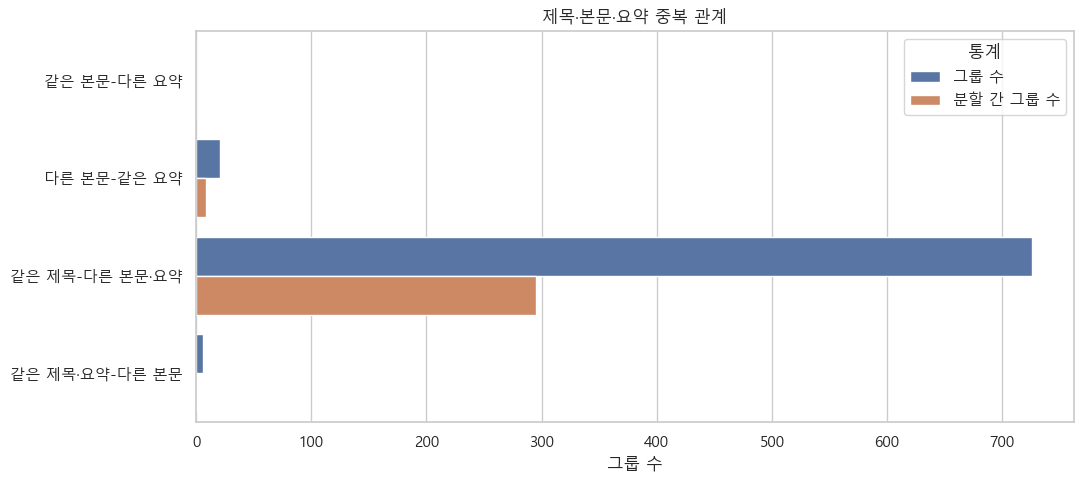

In [41]:
plot_df = duplicate_relationship_summary_df.melt(
    id_vars="관계",
    value_vars=["그룹 수", "분할 간 그룹 수"],
    var_name="통계", value_name="개수",
)

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=plot_df, y="관계", x="개수", hue="통계", ax=ax)
ax.set_title("제목·본문·요약 중복 관계")
ax.set_xlabel("그룹 수")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(
    FIGURES / "07_duplicate_relationships.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

### 관계 중복의 해석

- 같은 본문에 서로 다른 요약이 붙은 사례가 없다면, 정확히 동일한 본문 중복은 같은 정답을 공유합니다.
- 다른 본문에 같은 요약이 붙은 사례는 사진 연속 기사처럼 정상일 수도 있고 정답 재사용 문제일 수도 있습니다.
- 같은 제목에 서로 다른 본문·요약이 붙은 사례는 동일 사건의 후속 기사, 사진 기사 또는 동일 제목 재사용일 수 있습니다.
- 이 관계가 분할 사이에 걸치면 같은 사건을 학습하고 평가할 가능성이 있으므로 그룹 분할 후보가 됩니다.
- 자동 삭제하지 않고 원문·요약·링크를 함께 검토합니다.

In [42]:
duplicate_relationship_summary_df.to_csv(
    RESULTS / "duplicate_relationship_summary.csv",
    index=False,
    encoding="utf-8-sig",
)
duplicate_relationship_rows_df.to_csv(
    RESULTS / "duplicate_relationship_rows.csv",
    index=False,
    encoding="utf-8-sig",
)

# 기존 판단표에도 관계 중복 결과를 연결합니다.
relation_decisions = duplicate_relationship_summary_df.loc[
    duplicate_relationship_summary_df["그룹 수"].gt(0),
    ["관계", "그룹 수"],
].rename(columns={"관계": "문제", "그룹 수": "탐지 건수"})
relation_decisions["현재 처리"] = "유지"
relation_decisions["다음 계획"] = "사례 확인 후 그룹 분할·노이즈 제거 비교"

decision_table_with_relations_df = pd.concat(
    [decision_table_df, relation_decisions],
    ignore_index=True,
).drop_duplicates(subset=["문제"], keep="last")
decision_table_with_relations_df.to_csv(
    RESULTS / "preprocessing_decision_table.csv",
    index=False,
    encoding="utf-8-sig",
)

print("저장:", RESULTS / "duplicate_relationship_summary.csv")
print("저장:", RESULTS / "duplicate_relationship_rows.csv")
display(decision_table_with_relations_df)

저장: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\01_data_eda\duplicate_relationship_summary.csv
저장: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\01_data_eda\duplicate_relationship_rows.csv


,문제,탐지 건수,현재 처리,다음 계획
0,결측치/빈 문자열,0,없음,발견 시 해당 행 검토
1,분할 사이 동일 본문,612,유지,원본 분할과 그룹 분할 비교
2,TF-IDF 유사 제목 쌍(0.8 이상),7769,유지,사례 확인 후 사건 그룹 후보로 사용
3,반복 요약,1121,유지,사람 검토 후 노이즈 제거 비교
4,숫자 불일치 후보,369,유지,표기 차이를 고려해 사람 검토
5,낮은 본문–요약 일치도,6,유지,다른 기사 요약 여부 확인
6,512토큰 초과 본문(train),6108,삭제하지 않음,512와 1024 입력 길이 비교
7,다른 본문-같은 요약,21,유지,사례 확인 후 그룹 분할·노이즈 제거 비교
8,같은 제목-다른 본문·요약,726,유지,사례 확인 후 그룹 분할·노이즈 제거 비교
9,같은 제목·요약-다른 본문,6,유지,사례 확인 후 그룹 분할·노이즈 제거 비교


## 23. 중복 관계 분석 결론

정확한 문자열 기준으로 **같은 본문–다른 요약은 발견되지 않았습니다.** 반면 다른 본문–같은 요약과 같은 제목–다른 본문·요약 관계가 존재합니다. 특히 서로 다른 분할에 걸친 그룹은 무작위 분할에서 동일 사건이 학습과 평가 양쪽에 들어갈 수 있음을 보여줍니다.

따라서 기본 실험은 제공된 원본 분할을 유지하고, 비교 실험에서는 제목·본문 유사도를 이용해 동일 사건 후보가 한 분할에만 들어가도록 그룹 분할을 구성합니다. 이때 현재 표의 정확 중복과 TF-IDF 유사 후보를 함께 사용하고, test 설정은 최종 평가 전에 고정합니다.


---

# 원본 단계: `02_tokenize_embedding.ipynb`


# 02. 토큰화와 임베딩

이 노트북에서 하는 일: 같은 한국어 문장이 모델별로 어떻게 토큰화되는지 비교하고, Word2Vec 고정 임베딩과 KoBART 문맥 임베딩의 차이를 확인한다.

가이드 요구사항:

- KoBART BPE, KoGPT2 BPE, KoELECTRA WordPiece 토큰 분리 비교
- 모델별 토큰 길이 분포와 512·1,024토큰 초과 비율 비교
- Word2Vec으로 train 기사 단어 임베딩 학습 및 유사 단어 확인
- 동일 단어의 기본 임베딩과 문맥 반영 인코더 출력 비교
- 토큰 ID → 임베딩 → 인코더 → 디코더 logits의 shape 기록

이 노트북에서는 요약 모델을 파인튜닝하거나 test 성능을 평가하지 않는다.


## 1. 환경과 설정

In [43]:
import os
import sys
from pathlib import Path

PROJECT = PROJECT_ROOT
assert PROJECT.exists(), "프로젝트 경로를 확인하세요."
assert Path(sys.prefix).resolve() == (PROJECT / ".venv").resolve(), (
    "커널을 Python 3.11 (Team4 News GPU)로 바꾸세요."
)

os.environ["HF_HOME"] = str(PROJECT / ".cache" / "huggingface")
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "120"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

RESULTS = PROJECT / "results" / "02_tokenize_embedding"
FIGURES = RESULTS / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

SEED = 42
DATASET_ID = "daekeun-ml/naver-news-summarization-ko"
MODEL_SPECS = {
    "KoBART_BPE": "gogamza/kobart-base-v2",
    "KoGPT2_BPE": "skt/kogpt2-base-v2",
    "KoELECTRA_WordPiece": "monologg/koelectra-base-v3-discriminator",
}
TOKENIZATION_EXAMPLE = "정부가 수출 중소기업의 물류난 해소를 위해 무역금융 규모를 40조 원 이상 확대한다"
WORD2VEC_MAX_DOCS = None  # 빠른 점검은 5000처럼 지정, 전체 분석은 None

print("Python:", sys.version.split()[0])
print("결과 폴더:", RESULTS)

Python: 3.11.9
결과 폴더: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\02_tokenize_embedding


In [44]:
import json
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from datasets import load_dataset
from gensim.models import Word2Vec
from huggingface_hub import HfApi
from konlpy.tag import Okt
from transformers import AutoTokenizer, BartForConditionalGeneration

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


## 2. train 데이터와 모델 revision 확인

In [45]:
api = HfApi()
dataset_revision = api.dataset_info(DATASET_ID).sha
model_revisions = {
    name: api.model_info(model_id).sha
    for name, model_id in MODEL_SPECS.items()
}

raw_dataset = load_dataset(DATASET_ID, revision=dataset_revision)
train_df = raw_dataset["train"].to_pandas().reset_index(drop=True)

assert len(train_df) == 22194
assert train_df["document"].notna().all()

print("dataset revision:", dataset_revision)
display(pd.Series(model_revisions, name="model revision"))
print("train rows:", len(train_df))

dataset revision: 916dfe6aed651b2ecd9d04fa0a704f8953e90762


KoBART_BPE             f5899cc556216353e23ee36b66fad52b902066c5
KoGPT2_BPE             d0c0df48bf2b2c9350dd855021a5b216f560c0c7
KoELECTRA_WordPiece    68b30cd259f34a4b5aa8786392612ba2a2617fcc
Name: model revision, dtype: object

train rows: 22194


## 3. 같은 문장의 토크나이저 비교

KoBART와 KoGPT2는 BPE 계열이지만 학습 말뭉치와 어휘가 달라 분리 결과가 같지 않을 수 있다. KoELECTRA는 WordPiece를 사용하며 요약 생성 모델이 아니라 토큰화 방식 비교 대상으로만 사용한다.


In [46]:
tokenizers = {
    name: AutoTokenizer.from_pretrained(
        model_id,
        revision=model_revisions[name],
        clean_up_tokenization_spaces=False,
    )
    for name, model_id in MODEL_SPECS.items()
}

tokenization_rows = []
for name, tokenizer in tokenizers.items():
    tokens = tokenizer.tokenize(TOKENIZATION_EXAMPLE)
    token_ids = tokenizer.encode(TOKENIZATION_EXAMPLE, add_special_tokens=True)
    tokenization_rows.append({
        "tokenizer": name,
        "model_id": MODEL_SPECS[name],
        "tokenizer_class": tokenizer.__class__.__name__,
        "vocab_size": tokenizer.vocab_size,
        "tokens_without_special_count": len(tokens),
        "ids_with_special_count": len(token_ids),
        "tokens": " | ".join(tokens),
    })

tokenization_comparison_df = pd.DataFrame(tokenization_rows)
display(tokenization_comparison_df.T)
tokenization_comparison_df.to_csv(
    RESULTS / "tokenizer_example_comparison.csv",
    index=False,
    encoding="utf-8-sig",
)

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


,0,1,2
tokenizer,KoBART_BPE,KoGPT2_BPE,KoELECTRA_WordPiece
model_id,gogamza/kobart-base-v2,skt/kogpt2-base-v2,monologg/koelectra-base-v3-discriminator
tokenizer_class,PreTrainedTokenizerFast,GPT2TokenizerFast,ElectraTokenizerFast
vocab_size,30000,51200,35000
tokens_without_special_count,17,19,20
ids_with_special_count,17,19,22
tokens,▁정부가 | ▁수출 | ▁중소기업의 | ▁물류 | 난 | ▁해 | 소를 | ▁위해 | ▁무역 | 금융 | ▁규모를 | ▁40 | 조 | ▁원 | ▁이상 | ▁확대 | 한다,▁정부가 | ▁수출 | ▁중소기업 | 의 | ▁물류 | 난 | ▁해 | 소를 | ▁위해 | ▁무역 | 금융 | ▁규모를 | ▁40 | 조 | ▁원 | ▁이상 | ▁확 | 대...,정부 | ##가 | 수출 | 중소기업 | ##의 | 물류 | ##난 | 해소 | ##를 | 위해 | 무역 | ##금융 | 규모 | ##를 | 40 | ##조 | 원 | 이상...


## 4. train 전체 토큰 길이 비교

,tokenizer,rows,mean,median,p95,p99,max,over_512_count,over_512_pct,over_1024_count,over_1024_pct
0,KoBART_BPE,22194,418.12,357.0,970.00,1548.28,6781,6108,27.52,918,4.14
1,KoGPT2_BPE,22194,422.66,361.0,977.00,1564.07,6993,6231,28.08,943,4.25
2,KoELECTRA_WordPiece,22194,501.96,428.0,1163.35,1875.07,8431,8397,37.83,1692,7.62


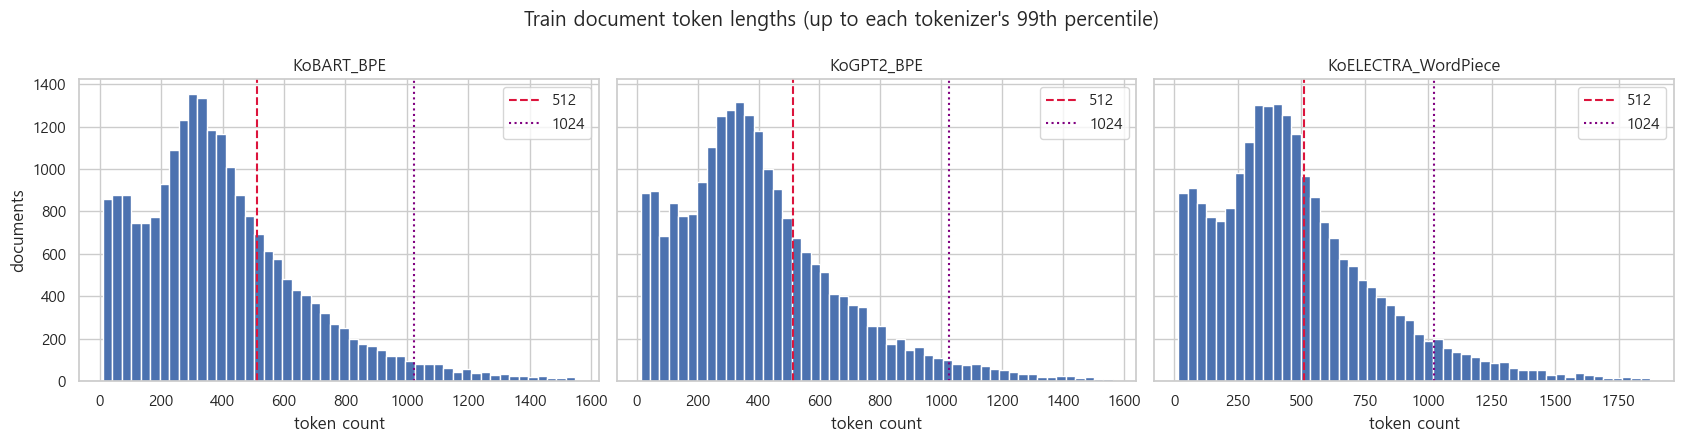

In [47]:
def token_lengths(tokenizer, texts, batch_size=256):
    lengths = []
    values = texts.astype(str).tolist()
    for start in range(0, len(values), batch_size):
        encoded = tokenizer(
            values[start:start + batch_size],
            add_special_tokens=True,
            truncation=False,
            return_attention_mask=False,
            return_token_type_ids=False,
            verbose=False,
        )
        lengths.extend(len(input_ids) for input_ids in encoded["input_ids"])
    return np.asarray(lengths, dtype=np.int32)

length_frames = []
length_summary_rows = []
for name, tokenizer in tokenizers.items():
    lengths = token_lengths(tokenizer, train_df["document"])
    length_frames.append(pd.DataFrame({"tokenizer": name, "tokens": lengths}))
    length_summary_rows.append({
        "tokenizer": name,
        "rows": len(lengths),
        "mean": lengths.mean(),
        "median": np.median(lengths),
        "p95": np.quantile(lengths, 0.95),
        "p99": np.quantile(lengths, 0.99),
        "max": lengths.max(),
        "over_512_count": int((lengths > 512).sum()),
        "over_512_pct": float((lengths > 512).mean() * 100),
        "over_1024_count": int((lengths > 1024).sum()),
        "over_1024_pct": float((lengths > 1024).mean() * 100),
    })

token_lengths_df = pd.concat(length_frames, ignore_index=True)
token_length_summary_df = pd.DataFrame(length_summary_rows)
display(token_length_summary_df.round(2))

token_length_summary_df.to_csv(
    RESULTS / "token_length_comparison.csv", index=False, encoding="utf-8-sig"
)

fig, axes = plt.subplots(1, len(MODEL_SPECS), figsize=(17, 4.5), sharey=True)
for axis, (name, group) in zip(axes, token_lengths_df.groupby("tokenizer", sort=False)):
    upper = group["tokens"].quantile(0.99)
    axis.hist(group.loc[group["tokens"].le(upper), "tokens"], bins=50, color="#4C72B0")
    axis.axvline(512, color="crimson", linestyle="--", label="512")
    axis.axvline(1024, color="purple", linestyle=":", label="1024")
    axis.set_title(name)
    axis.set_xlabel("token count")
    axis.legend()
axes[0].set_ylabel("documents")
plt.suptitle("Train document token lengths (up to each tokenizer's 99th percentile)")
plt.tight_layout()
plt.savefig(FIGURES / "token_length_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. KoBART와 KoGPT2 구조 비교 및 모델 선택

KoBART와 KoGPT2는 모두 한국어 생성에 사용할 수 있지만 구조와 학습 입력 방식이 다르다. 이 프로젝트는 본문 전체를 읽고 요약을 생성하는 `document → summary` task이므로, 구조 비교와 토큰 길이 결과를 함께 근거로 모델을 선택한다. KoELECTRA는 생성 모델이 아니므로 토큰화 비교 대상으로만 둔다.

In [48]:
architecture_comparison_df = pd.DataFrame([
    {
        "model": "KoBART",
        "tokenization": "BPE",
        "architecture": "encoder-decoder",
        "document_handling": "encoder가 본문 전체를 읽어 문맥 표현 생성",
        "summary_training": "decoder가 정답 summary 토큰을 순차 예측",
        "summarization_fit": "document → summary 구조와 직접 일치",
        "decision": "selected",
    },
    {
        "model": "KoGPT2",
        "tokenization": "BPE",
        "architecture": "decoder-only",
        "document_handling": "본문과 summary를 하나의 인과적(causal) 시퀀스로 연결",
        "summary_training": "앞 토큰을 바탕으로 다음 토큰 예측; 본문 부분 loss mask 필요",
        "summarization_fit": "가능하지만 별도 입력 형식과 학습 구현이 필요",
        "decision": "not selected",
    },
    {
        "model": "KoELECTRA",
        "tokenization": "WordPiece",
        "architecture": "encoder-only discriminator",
        "document_handling": "본문 표현을 생성하지만 요약 decoder가 없음",
        "summary_training": "문장 생성용 학습 구조가 아님",
        "summarization_fit": "분류·판별에는 적합, 생성 요약에는 부적합",
        "decision": "tokenization comparison only",
    },
])

kobart_length = token_length_summary_df.loc[
    token_length_summary_df["tokenizer"].eq("KoBART_BPE")
].iloc[0]
kogpt2_length = token_length_summary_df.loc[
    token_length_summary_df["tokenizer"].eq("KoGPT2_BPE")
].iloc[0]

selection_evidence_df = pd.DataFrame([
    {
        "criterion": "요약 task 구조 적합성",
        "evidence": "KoBART는 encoder-decoder로 document → summary를 직접 모델링",
        "conclusion": "KoBART 선택",
    },
    {
        "criterion": "토크나이저·사전학습 가중치 호환성",
        "evidence": "KoBART BPE token ID와 KoBART 사전학습 임베딩을 동일한 쌍으로 사용",
        "conclusion": "KoBART BPE 유지",
    },
    {
        "criterion": "본문 토큰 길이",
        "evidence": (
            f"KoBART 평균 {kobart_length['mean']:.1f}, 512 초과 {kobart_length['over_512_pct']:.2f}% / "
            f"KoGPT2 평균 {kogpt2_length['mean']:.1f}, 512 초과 {kogpt2_length['over_512_pct']:.2f}%"
        ),
        "conclusion": "길이 면에서도 KoBART가 불리하지 않음",
    },
])

display(architecture_comparison_df)
display(selection_evidence_df)
architecture_comparison_df.to_csv(
    RESULTS / "model_architecture_comparison.csv", index=False, encoding="utf-8-sig"
)
selection_evidence_df.to_csv(
    RESULTS / "kobart_selection_evidence.csv", index=False, encoding="utf-8-sig"
)
(RESULTS / "model_selection_decision.json").write_text(
    json.dumps({
        "selected_model": "gogamza/kobart-base-v2",
        "decision": "KoBART를 본문-요약 encoder-decoder 파인튜닝 모델로 사용",
        "note": "이 노트북은 구조·토큰화 근거를 비교한 것이며, KoBART와 KoGPT2의 동일 조건 성능 대결은 수행하지 않음",
    }, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

,model,tokenization,architecture,document_handling,summary_training,summarization_fit,decision
0,KoBART,BPE,encoder-decoder,encoder가 본문 전체를 읽어 문맥 표현 생성,decoder가 정답 summary 토큰을 순차 예측,document → summary 구조와 직접 일치,selected
1,KoGPT2,BPE,decoder-only,본문과 summary를 하나의 인과적(causal) 시퀀스로 연결,앞 토큰을 바탕으로 다음 토큰 예측; 본문 부분 loss mask 필요,가능하지만 별도 입력 형식과 학습 구현이 필요,not selected
2,KoELECTRA,WordPiece,encoder-only discriminator,본문 표현을 생성하지만 요약 decoder가 없음,문장 생성용 학습 구조가 아님,"분류·판별에는 적합, 생성 요약에는 부적합",tokenization comparison only


,criterion,evidence,conclusion
0,요약 task 구조 적합성,KoBART는 encoder-decoder로 document → summary를 직접 모델링,KoBART 선택
1,토크나이저·사전학습 가중치 호환성,KoBART BPE token ID와 KoBART 사전학습 임베딩을 동일한 쌍으로 사용,KoBART BPE 유지
2,본문 토큰 길이,"KoBART 평균 418.1, 512 초과 27.52% / KoGPT2 평균 422.7, 512 초과 28.08%",길이 면에서도 KoBART가 불리하지 않음


184

## 6. Word2Vec 고정 임베딩

수업에서 사용한 `Okt`로 train 기사를 형태소 단위로 나누고 Word2Vec을 학습한다. Word2Vec에서는 한 단어가 문맥과 관계없이 하나의 고정 벡터를 가진다.

`WORD2VEC_MAX_DOCS=None`이면 train 전체를 사용한다. 실행 시간을 먼저 확인하려면 설정 셀에서 5,000처럼 지정할 수 있다.


In [49]:
word2vec_source = train_df["document"]
if WORD2VEC_MAX_DOCS is not None:
    word2vec_source = word2vec_source.sample(
        n=min(WORD2VEC_MAX_DOCS, len(word2vec_source)),
        random_state=SEED,
    )

okt = Okt()
word2vec_corpus = []
for index, document in enumerate(word2vec_source.astype(str), start=1):
    morphs = okt.morphs(document, stem=True)
    if morphs:
        word2vec_corpus.append(morphs)
    if index % 1000 == 0:
        print(f"형태소 분석: {index:,}/{len(word2vec_source):,}")

word2vec_model = Word2Vec(
    sentences=word2vec_corpus,
    vector_size=100,
    window=5,
    min_count=5,
    workers=1,
    sg=1,
    seed=SEED,
    epochs=5,
)
word2vec_model.save(str(RESULTS / "news_word2vec.model"))

similar_word_rows = []
for query in ["수출", "반도체", "기업", "경제"]:
    if query not in word2vec_model.wv:
        print(f"Word2Vec 어휘에 없음: {query}")
        continue
    for rank, (word, similarity) in enumerate(
        word2vec_model.wv.most_similar(query, topn=10), start=1
    ):
        similar_word_rows.append({
            "query": query,
            "rank": rank,
            "similar_word": word,
            "cosine_similarity": similarity,
        })

word2vec_similar_words_df = pd.DataFrame(similar_word_rows)
display(word2vec_similar_words_df)
word2vec_similar_words_df.to_csv(
    RESULTS / "word2vec_similar_words.csv", index=False, encoding="utf-8-sig"
)

형태소 분석: 1,000/22,194
형태소 분석: 2,000/22,194
형태소 분석: 3,000/22,194
형태소 분석: 4,000/22,194
형태소 분석: 5,000/22,194
형태소 분석: 6,000/22,194
형태소 분석: 7,000/22,194
형태소 분석: 8,000/22,194
형태소 분석: 9,000/22,194
형태소 분석: 10,000/22,194
형태소 분석: 11,000/22,194
형태소 분석: 12,000/22,194
형태소 분석: 13,000/22,194
형태소 분석: 14,000/22,194
형태소 분석: 15,000/22,194
형태소 분석: 16,000/22,194
형태소 분석: 17,000/22,194
형태소 분석: 18,000/22,194
형태소 분석: 19,000/22,194
형태소 분석: 20,000/22,194
형태소 분석: 21,000/22,194
형태소 분석: 22,000/22,194


,query,rank,similar_word,cosine_similarity
0,수출,1,교역,0.659205
1,수출,2,3424,0.656423
2,수출,3,34.0%,0.633179
3,수출,4,수출입,0.632438
4,수출,5,4496,0.631038
5,수출,6,對,0.629846
6,수출,7,577억,0.628941
7,수출,8,70억달러,0.622664
8,수출,9,242억,0.619676
9,수출,10,3503억달러,0.619079


## 6. KoBART 기본 임베딩과 문맥 임베딩 비교

같은 `수출`이라는 표현을 서로 다른 문장에 넣는다. 입력 임베딩은 토큰 자체를 나타내고, 인코더 출력은 문장 전체를 읽은 뒤 문맥이 반영된 벡터다.


In [50]:
kobart_tokenizer = tokenizers["KoBART_BPE"]
kobart_model = BartForConditionalGeneration.from_pretrained(
    MODEL_SPECS["KoBART_BPE"],
    revision=model_revisions["KoBART_BPE"],
    use_safetensors=True,
).to(device)
kobart_model.eval()

context_sentences = [
    "한국 경제에서 수출 비중이 크게 증가했다.",
    "정부는 수출 기업의 물류비를 지원하기로 했다.",
]
keyword = "수출"

def keyword_vectors(sentence, keyword):
    encoded = kobart_tokenizer(
        sentence,
        return_tensors="pt",
        return_offsets_mapping=True,
        return_token_type_ids=False,
    )
    offsets = encoded.pop("offset_mapping")[0].tolist()
    keyword_start = sentence.index(keyword)
    keyword_end = keyword_start + len(keyword)
    positions = [
        index
        for index, (start, end) in enumerate(offsets)
        if end > keyword_start and start < keyword_end
    ]
    assert positions, f"키워드 토큰 위치를 찾지 못했습니다: {sentence}"

    model_inputs = {key: value.to(device) for key, value in encoded.items()}
    with torch.no_grad():
        input_embeddings = kobart_model.model.shared(model_inputs["input_ids"])
        encoder_output = kobart_model.model.encoder(**model_inputs).last_hidden_state

    input_vector = input_embeddings[0, positions].mean(dim=0).cpu()
    contextual_vector = encoder_output[0, positions].mean(dim=0).cpu()
    keyword_tokens = kobart_tokenizer.convert_ids_to_tokens(
        model_inputs["input_ids"][0, positions].detach().cpu().tolist()
    )
    return input_vector, contextual_vector, keyword_tokens

first_input, first_context, first_tokens = keyword_vectors(context_sentences[0], keyword)
second_input, second_context, second_tokens = keyword_vectors(context_sentences[1], keyword)

embedding_comparison_df = pd.DataFrame([
    {
        "representation": "input_embedding",
        "cosine_similarity": F.cosine_similarity(
            first_input.unsqueeze(0), second_input.unsqueeze(0)
        ).item(),
        "interpretation": "토큰 자체의 기본 벡터",
    },
    {
        "representation": "encoder_contextual_output",
        "cosine_similarity": F.cosine_similarity(
            first_context.unsqueeze(0), second_context.unsqueeze(0)
        ).item(),
        "interpretation": "문장 전체 문맥이 반영된 벡터",
    },
])

print("문장 1의 키워드 토큰:", first_tokens)
print("문장 2의 키워드 토큰:", second_tokens)
display(embedding_comparison_df)
embedding_comparison_df.to_csv(
    RESULTS / "embedding_context_comparison.csv", index=False, encoding="utf-8-sig"
)

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


문장 1의 키워드 토큰: ['▁수출']
문장 2의 키워드 토큰: ['▁수출']


,representation,cosine_similarity,interpretation
0,input_embedding,1.000000,토큰 자체의 기본 벡터
1,encoder_contextual_output,0.355976,문장 전체 문맥이 반영된 벡터


## 7. KoBART 내부 데이터 흐름과 shape

In [51]:
sample_text = train_df.loc[0, "document"]
sample_inputs = kobart_tokenizer(
    sample_text,
    return_tensors="pt",
    max_length=512,
    truncation=True,
    return_token_type_ids=False,
)
sample_inputs = {key: value.to(device) for key, value in sample_inputs.items()}

decoder_start_token_id = kobart_model.config.decoder_start_token_id
if decoder_start_token_id is None:
    decoder_start_token_id = (
        kobart_tokenizer.bos_token_id
        if kobart_tokenizer.bos_token_id is not None
        else kobart_tokenizer.eos_token_id
    )
decoder_input_ids = torch.tensor([[decoder_start_token_id]], device=device)

with torch.no_grad():
    input_embeddings = kobart_model.model.shared(sample_inputs["input_ids"])
    encoder_output = kobart_model.model.encoder(**sample_inputs).last_hidden_state
    model_output = kobart_model(
        **sample_inputs,
        decoder_input_ids=decoder_input_ids,
    )

shape_log = {
    "input_ids": list(sample_inputs["input_ids"].shape),
    "attention_mask": list(sample_inputs["attention_mask"].shape),
    "token_embedding": list(input_embeddings.shape),
    "encoder_last_hidden_state": list(encoder_output.shape),
    "decoder_input_ids": list(decoder_input_ids.shape),
    "decoder_logits": list(model_output.logits.shape),
    "hidden_size": kobart_model.config.d_model,
    "vocab_size": kobart_model.config.vocab_size,
}

display(pd.Series(shape_log, name="shape"))
(RESULTS / "kobart_shape_log.json").write_text(
    json.dumps(shape_log, ensure_ascii=False, indent=2), encoding="utf-8"
)

input_ids                         [1, 315]
attention_mask                    [1, 315]
token_embedding              [1, 315, 768]
encoder_last_hidden_state    [1, 315, 768]
decoder_input_ids                   [1, 1]
decoder_logits               [1, 1, 30000]
hidden_size                            768
vocab_size                           30000
Name: shape, dtype: object

334

## 8. 해석 기준과 산출물

실행 후 다음 내용을 정리한다.

1. 동일 문장이 모델별로 몇 토큰으로 나뉘었는가?
2. 어떤 토크나이저에서 512·1,024토큰 초과가 더 많은가?
3. Word2Vec에서 주요 경제·IT 단어와 가까운 단어는 무엇인가?
4. 같은 단어의 입력 임베딩과 문맥 임베딩 cosine similarity가 어떻게 다른가?
5. 토큰 ID부터 decoder logits까지 각 텐서 shape는 무엇을 의미하는가?


In [52]:
run_summary = {
    "dataset_id": DATASET_ID,
    "dataset_revision": dataset_revision,
    "model_specs": MODEL_SPECS,
    "model_revisions": model_revisions,
    "seed": SEED,
    "tokenization_example": TOKENIZATION_EXAMPLE,
    "train_rows_for_token_lengths": len(train_df),
    "word2vec_source_rows": len(word2vec_source),
    "word2vec_vector_size": word2vec_model.vector_size,
    "word2vec_window": word2vec_model.window,
    "word2vec_min_count": word2vec_model.min_count,
    "context_sentences": context_sentences,
    "context_keyword": keyword,
}
(RESULTS / "run_summary.json").write_text(
    json.dumps(run_summary, ensure_ascii=False, indent=2), encoding="utf-8"
)

for path in sorted(RESULTS.rglob("*")):
    if path.is_file():
        print("-", path.relative_to(PROJECT))

- results\02_tokenize_embedding\embedding_context_comparison.csv
- results\02_tokenize_embedding\figures\token_length_comparison.png
- results\02_tokenize_embedding\kobart_selection_evidence.csv
- results\02_tokenize_embedding\kobart_shape_log.json
- results\02_tokenize_embedding\model_architecture_comparison.csv
- results\02_tokenize_embedding\model_selection_decision.json
- results\02_tokenize_embedding\news_word2vec.model
- results\02_tokenize_embedding\run_summary.json
- results\02_tokenize_embedding\token_length_comparison.csv
- results\02_tokenize_embedding\tokenizer_example_comparison.csv
- results\02_tokenize_embedding\word2vec_similar_words.csv



---

# 원본 단계: `03-1_baseline_no_summary.ipynb`


# 03-1 baseline - no summary training

이 노트북에서 하는 일: **파인튜닝하지 않은 KoBART**에 뉴스 원문 `document`만 입력해 요약을 생성한다.

이 실험은 수업의 사전학습 BART와 `model.generate()` 사용법을 적용한 zero-shot 기준선입니다.

- 학습하지 않는다.
- optimizer와 `loss.backward()`를 사용하지 않는다.
- 모델 입력에는 `document`만 들어간다.
- 데이터의 `summary`는 생성이 끝난 뒤 ROUGE 평가와 사례 비교에만 사용한다.
- 원본 test 2,740건을 그대로 사용한다.

따라서 이 실험의 점수는 이후 KoBART 파인튜닝 결과와 비교할 **학습 전 성능**이다.


## 1. 환경 및 생성 설정

In [53]:
import os
import sys
from pathlib import Path

PROJECT = PROJECT_ROOT
assert PROJECT.exists(), "프로젝트 경로를 확인하세요."
assert Path(sys.prefix).resolve() == (PROJECT / ".venv").resolve(), (
    "커널을 Python 3.11 (Team4 News GPU)로 바꾸세요."
)

os.environ["HF_HOME"] = str(PROJECT / ".cache" / "huggingface")
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "120"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

RESULTS = PROJECT / "results" / "03-1_baseline_no_summary"
RESULTS.mkdir(parents=True, exist_ok=True)

SEED = 42
DATASET_ID = "daekeun-ml/naver-news-summarization-ko"
MODEL_ID = "gogamza/kobart-base-v2"
MAX_SOURCE_LENGTH = 512
MAX_NEW_TOKENS = 128
BATCH_SIZE = 4
RUN_GENERATION = True
MAX_EVAL_SAMPLES = None  # 빠른 점검은 20처럼 지정, 전체 평가는 None

print("Python:", sys.version.split()[0])
print("결과 폴더:", RESULTS)

Python: 3.11.9
결과 폴더: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\03-1_baseline_no_summary


In [54]:
import json
import random
import time

import evaluate
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from huggingface_hub import HfApi
from torch.utils.data import DataLoader, SequentialSampler, TensorDataset
from transformers import AutoTokenizer, BartForConditionalGeneration

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert device.type == "cuda", "CUDA를 사용할 수 없습니다."
print("device:", device)
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM(GB):", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))

device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
VRAM(GB): 7.96


## 2. 원본 test 데이터 로드

In [55]:
api = HfApi()
dataset_revision = api.dataset_info(DATASET_ID).sha
model_revision = api.model_info(MODEL_ID).sha
raw_dataset = load_dataset(DATASET_ID, revision=dataset_revision)

test_df = raw_dataset["test"].to_pandas().reset_index(drop=True)
test_df.insert(0, "source_index", np.arange(len(test_df), dtype=np.int64))
test_df.insert(0, "row_id", "test:" + test_df["source_index"].astype(str))

assert len(test_df) == 2740
assert test_df["document"].notna().all()
assert test_df["document"].str.strip().ne("").all()

if MAX_EVAL_SAMPLES is not None:
    evaluation_df = test_df.iloc[:MAX_EVAL_SAMPLES].copy()
else:
    evaluation_df = test_df.copy()

print("dataset revision:", dataset_revision)
print("model revision:", model_revision)
print("원본 test:", len(test_df))
print("이번 실행 대상:", len(evaluation_df))
display(evaluation_df[["title", "document"]].head(3))

dataset revision: 916dfe6aed651b2ecd9d04fa0a704f8953e90762
model revision: f5899cc556216353e23ee36b66fad52b902066c5
원본 test: 2740
이번 실행 대상: 2740


,title,document
0,아이트로닉스 차량용 복합기능형 졸음 방지 단말기 특허 출원,아이엘사이언스의 자회사 아이트로닉스는 차량용 복합기능형 졸음 방지 단말기 특허를 출원했다고 4일 밝혔다. 신규 특허는 자동차 주행 중 운전자의 졸음운전을 방지하는 상태 검출...
1,뉴스페이스로 가는 한국… 우주기업 성장할 기술·터전 만든다,한국형 우주발사체 누리호 가 지난 6월 21일 전남 고흥 나로우주센터 발사대에서 날아올라 성공적으로 발사됐다. 한국항공우주연구원 제공 파이낸셜뉴스 한국형 우주발사체 누리호 ...
2,SP500 올 상반기 21%↓…50년래 최악 월가월부,닥터둠 루비니 주가 50% 폭락할 것 뉴욕 증시 3대지수 모두 하락 대형주 중심의 미국 스탠더드앤드푸어스 S P 500 지수가 올 상반기 50여년만에 최악의 실적을 기록했다...


## 3. document만 토큰화

아래 `TensorDataset`에는 `input_ids`와 `attention_mask`만 존재합니다. 정답 `summary` tensor는 만들지 않습니다.


In [56]:
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    revision=model_revision,
    clean_up_tokenization_spaces=False,
)

def make_document_dataset(data, tokenizer):
    source = tokenizer(
        text=data["document"].tolist(),
        padding="max_length",
        truncation=True,
        max_length=MAX_SOURCE_LENGTH,
        return_token_type_ids=False,
        return_tensors="pt",
    )
    return TensorDataset(source["input_ids"], source["attention_mask"])

def get_dataloader(dataset, batch_size):
    return DataLoader(
        dataset,
        sampler=SequentialSampler(dataset),
        batch_size=batch_size,
        num_workers=0,
        pin_memory=True,
    )

document_dataset = make_document_dataset(evaluation_df, tokenizer)
document_dataloader = get_dataloader(document_dataset, BATCH_SIZE)

sample_batch = next(iter(document_dataloader))
assert len(sample_batch) == 2, "입력에는 input_ids와 attention_mask만 있어야 합니다."
print("input_ids:", sample_batch[0].shape)
print("attention_mask:", sample_batch[1].shape)
print("summary는 모델 입력에 포함되지 않았습니다.")

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


input_ids: torch.Size([4, 512])
attention_mask: torch.Size([4, 512])
summary는 모델 입력에 포함되지 않았습니다.


## 4. 파인튜닝하지 않은 KoBART 로드

In [57]:
model = BartForConditionalGeneration.from_pretrained(
    MODEL_ID,
    revision=model_revision,
    use_safetensors=True,
).to(device)
model.eval()

print("model:", MODEL_ID)
print("parameters:", f"{sum(parameter.numel() for parameter in model.parameters()):,}")
print("학습 또는 checkpoint 로드는 수행하지 않았습니다.")

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


model: gogamza/kobart-base-v2
parameters: 123,859,968
학습 또는 checkpoint 로드는 수행하지 않았습니다.


## 5. 원문만으로 요약 생성

첫 zero-shot 기준선은 가장 단순한 greedy decoding을 사용합니다. beam search와 반복 억제는 이후 디코딩 전략 비교에서 별도로 실험합니다.


In [58]:
def generate_summaries(model, dataloader):
    predictions = []
    started = time.perf_counter()
    torch.cuda.reset_peak_memory_stats()

    with torch.no_grad():
        for step, (input_ids, attention_mask) in enumerate(dataloader, start=1):
            input_ids = input_ids.to(device)
            attention_mask = attention_mask.to(device)

            generated_ids = model.generate(
                input_ids=input_ids,
                attention_mask=attention_mask,
                max_new_tokens=MAX_NEW_TOKENS,
                num_beams=1,
                do_sample=False,
            )
            predictions.extend(
                tokenizer.batch_decode(
                    generated_ids,
                    skip_special_tokens=True,
                    clean_up_tokenization_spaces=False,
                )
            )

            if step % 100 == 0:
                print(f"  generation {step:,}/{len(dataloader):,}")

    elapsed_seconds = time.perf_counter() - started
    peak_memory_mib = torch.cuda.max_memory_allocated() / 2**20
    return [text.strip() for text in predictions], elapsed_seconds, peak_memory_mib

if RUN_GENERATION:
    predictions, generation_seconds, peak_memory_mib = generate_summaries(
        model, document_dataloader
    )
    assert len(predictions) == len(evaluation_df)
    print("생성 완료:", len(predictions))
    print("생성 시간(분):", round(generation_seconds / 60, 2))
    print("최대 GPU tensor 메모리(MiB):", round(peak_memory_mib, 1))
else:
    print("RUN_GENERATION=False: 생성을 건너뜁니다.")

  generation 100/685
  generation 200/685
  generation 300/685
  generation 400/685
  generation 500/685
  generation 600/685
생성 완료: 2740
생성 시간(분): 8.18
최대 GPU tensor 메모리(MiB): 1095.9


## 6. 생성 후 raw summary와 비교

이 단계에서 처음으로 `summary`를 참조합니다. summary는 모델 입력이나 학습에 사용되지 않고, 생성 결과의 평가 기준으로만 사용됩니다.


In [59]:
if RUN_GENERATION:
    result_df = evaluation_df[[
        "row_id", "title", "document", "summary", "category", "press", "link"
    ]].copy()
    result_df["prediction"] = predictions

    rouge_metric = evaluate.load("rouge")
    rouge_scores = rouge_metric.compute(
        predictions=result_df["prediction"].tolist(),
        references=result_df["summary"].astype(str).tolist(),
        tokenizer=lambda text: text.split(),
        use_stemmer=False,
    )
    metrics = {
        **{name: score * 100 for name, score in rouge_scores.items()},
        "evaluated_rows": len(result_df),
        "generation_seconds": generation_seconds,
        "peak_memory_mib": peak_memory_mib,
    }

    result_df.to_csv(
        RESULTS / "zero_shot_test_predictions.csv", index=False, encoding="utf-8-sig"
    )
    (RESULTS / "zero_shot_metrics.json").write_text(
        json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8"
    )

    display(pd.Series(metrics, name="KoBART zero-shot"))
    display(result_df[["title", "summary", "prediction"]].head(10))
else:
    print("RUN_GENERATION=False: 평가를 건너뜁니다.")

rouge1                  19.759300
rouge2                  15.104644
rougeL                  17.118359
rougeLsum               17.107262
evaluated_rows        2740.000000
generation_seconds     490.913962
peak_memory_mib       1095.946777
Name: KoBART zero-shot, dtype: float64

,title,summary,prediction
0,아이트로닉스 차량용 복합기능형 졸음 방지 단말기 특허 출원,"아이일, 아이트로닉스는 차량용 복합기능형 졸음 방지 단말기 특허를 출원했다고 4일 밝혔으며 신규 특허는 자동차 주행 중 운전자의 졸음운전을 방지하는 상태 검출 기술에 관한 ...",단단단다.다.다.다.다.다.다. 해당 단말다. 해당 단말기는 해당 단말기는다.다. 해당 단말기는 가시광선 및 근적외선 광원을 조사하는 광원 모듈 운전자의 얼굴 영상을 촬영하...
1,뉴스페이스로 가는 한국… 우주기업 성장할 기술·터전 만든다,"한국형 우주발사체 누리호가 지난 6월 21일 전남 고흥 나로우주센터 발사대에서 성공적으로 발사됨에 따라, 우주산업 클러스터가 조성될 지역을 8월중 선정하는 등 누리호 설계 ...",다.다.이다.이다.다.이다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다...
2,SP500 올 상반기 21%↓…50년래 최악 월가월부,대 대형주 중심의 미국 스탠더드앤드푸어스 S P 500 지수가 올 상반기 50여년만에 최악의 실적을 기록하고 30일 이하 미국 현지시간 뉴욕 증시 3대 지수도 모두 하락하며...,
3,풀무원 알래스칸 명태살 ‘볼카츠’ 출시,5일 5일 풀무원식품은 알래스카 청정해역의 신선한 명태살로 만든 연육을 동그랗게 빚은 후 빵가루를 묻혀 튀겨낸 '볼카츠'와 명태 연육을 감싸 고소하고 담백한 맛을 살린 '에...,하게 튀다.다.다. 신제품 ‘볼카츠’ 2종 통통새우 에그포테이토 은 깨끗한 자연환경으로 잘 알려진 알래스카에서 자란 고품질의 명태 연육을 동그랗게 빚은 후 빵가루를 묻혀 튀...
4,일동제약 생산본부장에 강덕원 부사장 영입,일동제약은 생산본부장으로 강덕원 부사장을 영입했다고 지난 1일 밝혔으며 강덕원 본부장은 서울대학교와 서던캘리포니아대학교 USC 를 졸업하고 동대학원에서 생화학 및 분자생물학...,은은은 생산본부장으로 강덕원 부사장을 영입했다고 지난 1일 밝혔다. 강덕원 본부장은 서울대학교와 서던캘리포니아대학교 USC 를 졸업하고 동대학원에서 생화학 및 분자생물학 석...
5,강릉커피산업 발전·애로기술 해결 의기투합…출연기관 업무협약,5일 기술회사인 커피커퍼가 KIST 강릉천연물연구소와 5일 커피 산업 발전을 위한 업무협약을 체결함에 따라 기업매출 확대 일자리 창출뿐만 아니라 더 많은 기업의 애로 기술 ...,"과학지원연구원 춘천센터 농업회사법인 커피커퍼가 5일 커피 산업 발전을 위한 커피커단 커피커퍼가 5일 커피 산업 발전을 위한 업무협약을 체결한다. KIST 강릉천연물연구소,기..."
6,약세장에 펀드 회전율 5년새 최저…운용기관 방어적 운용 영향,매매에서 주식을 매매하는 빈도를 뜻하는 매매 회전율이 5년 만에 140%까지 떨어진 것은 연초부터 이어진 약세장에 기관투자자들이 상품을 방어적으로 운용하고 나선 영향으로 풀...,다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다.다....
7,코오롱 수소 밸류체인 플랫폼 구축… 생산부터 발전까지 원스톱,코오롱그룹은 6일 동대문 디자인플라자에서 열린 ‘코리아 H2 비즈니스 서밋 2022 인베스터데이’에 참가해 그룹이 보유한 첨단기술을 바탕으로 수소 생산부터 운송 저장 발전사...,사 왼쪽에서에서 네번째에서 네번째 c코오롱그룹에서 네번째 c코오롱그룹 데들에서 네번째 c코오롱그룹 데일리안 조인영 기자 코오롱그룹이 수소산업의 밸류체인 전반을 고도화하는 플...
8,에너지정책 유턴 재생에너지 대신 원전으로,"정부가 정부가 오늘 국무회의에서 의결한 새 에너지 정책 방향의 주요 내용인 원자력 발전의 비중을 더 늘리겠다는 계획과 탄소 감축의 핵심인 석탄 화력발전소를 어떻게 줄일지, ...",했습니다.했습니다.입니다. 문재인 정부가 오늘 국무회의에서 의결했습니다. 예상대로 원자력 발전의 비중을 더 늘리겠다고 했는데요 탄소 감축의 핵심인 석탄 화력발전소를 어떻게 ...
9,산업 디지털전환법 오늘부터 시행…“기업 간 협업 프로젝트 지원 확대”,산업디지털전환촉진법 시행을 하루 앞둔 지난 4일 산업부 장영진 제1차관은 산업 디지털 전환 기업 간담회를 열고 올 하반기 수립할 산업 디지털 전환 종합계획 의견수렴 작업에 ...,디지털 전환 지원산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산산 지원 지원 지원 지원 지원 지원 지원 지원 지원 지원 지...


## 7. 실험 설정 저장

In [60]:
run_config = {
    "experiment": "KoBART zero-shot; document-only input",
    "dataset_id": DATASET_ID,
    "dataset_revision": dataset_revision,
    "evaluation_split": "original test",
    "model_id": MODEL_ID,
    "model_revision": model_revision,
    "fine_tuned": False,
    "summary_used_as_model_input": False,
    "summary_used_for_training": False,
    "summary_used_only_for_evaluation": True,
    "seed": SEED,
    "max_source_length": MAX_SOURCE_LENGTH,
    "max_new_tokens": MAX_NEW_TOKENS,
    "batch_size": BATCH_SIZE,
    "generation": {"num_beams": 1, "do_sample": False},
    "evaluation_rows": len(evaluation_df),
}
(RESULTS / "run_config.json").write_text(
    json.dumps(run_config, ensure_ascii=False, indent=2), encoding="utf-8"
)

for path in sorted(RESULTS.rglob("*")):
    if path.is_file():
        print("-", path.relative_to(PROJECT))

- results\03-1_baseline_no_summary\run_config.json
- results\03-1_baseline_no_summary\zero_shot_metrics.json
- results\03-1_baseline_no_summary\zero_shot_test_predictions.csv



---

# 원본 단계: `03-2_baseline_raw_data.ipynb`


# 03-2 baseline - raw data

이 노트북에서 하는 일: 원본 뉴스 데이터를 최소한으로 처리하고, 중복 누수를 제거한 뒤 KoBART를 파인튜닝한다.

수업 노트북 `7_1.ipynb`의 BART 학습 흐름을 따릅니다.

- `TensorDataset`, `DataLoader`, `RandomSampler`, `SequentialSampler`
- `BartForConditionalGeneration`과 `AdamW`
- 직접 작성한 `train()`과 `evaluation()`
- validation loss가 가장 낮은 `state_dict` 저장
- 수업 노트북 `7_3.ipynb`처럼 `model.generate()`로 실제 요약 생성

데이터 처리 원칙:

- 원본 test 2,740건은 고정한다.
- test와 동일한 본문 또는 summary로 연결된 train/validation 행은 학습에서 제외한다.
- train과 validation 사이의 중복 그룹은 validation 쪽으로 모은다.
- 공백 정규화는 중복 탐지에만 사용하고, 모델에는 원문을 그대로 넣는다.


## 1. 환경 및 설정

In [61]:
import os
import sys
from pathlib import Path

PROJECT = PROJECT_ROOT
assert PROJECT.exists(), "프로젝트 경로를 확인하세요."
assert Path(sys.prefix).resolve() == (PROJECT / ".venv").resolve(), (
    "커널을 Python 3.11 (Team4 News GPU)로 바꾸세요."
)

os.environ["HF_HOME"] = str(PROJECT / ".cache" / "huggingface")
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "120"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

RESULTS = PROJECT / "results" / "03-2_baseline_raw_data"
MODEL_PATH = RESULTS / "best_model_state.pt"
MANIFEST_PATH = RESULTS / "split_manifest.csv"
RESULTS.mkdir(parents=True, exist_ok=True)

SEED = 42
DATASET_ID = "daekeun-ml/naver-news-summarization-ko"
MODEL_ID = "gogamza/kobart-base-v2"
MAX_SOURCE_LENGTH = 512
MAX_TARGET_LENGTH = 256
EPOCHS = 5
BATCH_SIZE = 2
LEARNING_RATE = 3e-5
RUN_TRAINING = True  # 파인튜닝을 시작할 때만 True로 변경

print("Python:", sys.version.split()[0])
print("결과 폴더:", RESULTS)

Python: 3.11.9
결과 폴더: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\03-2_baseline_raw_data


In [62]:
import hashlib
import json
import random
import re
import time

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from huggingface_hub import HfApi
from torch import optim
from torch.nn.utils import clip_grad_norm_
from torch.utils.data import DataLoader, RandomSampler, SequentialSampler, TensorDataset
from transformers import AutoTokenizer, BartForConditionalGeneration

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert device.type == "cuda", "CUDA를 사용할 수 없습니다."
print("device:", device)
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM(GB):", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))

device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
VRAM(GB): 7.96


## 2. 원본 데이터 로드

In [63]:
api = HfApi()
dataset_revision = api.dataset_info(DATASET_ID).sha
model_revision = api.model_info(MODEL_ID).sha
raw_dataset = load_dataset(DATASET_ID, revision=dataset_revision)

split_order = ["train", "validation", "test"]
frames = []
for source_split in split_order:
    frame = raw_dataset[source_split].to_pandas()
    frame.insert(0, "source_index", np.arange(len(frame), dtype=np.int64))
    frame.insert(0, "source_split", source_split)
    frame.insert(0, "row_id", source_split + ":" + frame["source_index"].astype(str))
    frames.append(frame)

all_df = pd.concat(frames, ignore_index=True)
assert all_df["row_id"].is_unique
assert all_df[["document", "summary"]].notna().all().all()
assert all_df["document"].str.strip().ne("").all()
assert all_df["summary"].str.strip().ne("").all()

print("dataset revision:", dataset_revision)
print("model revision:", model_revision)
display(all_df.groupby("source_split", sort=False).size().rename("rows").to_frame())

dataset revision: 916dfe6aed651b2ecd9d04fa0a704f8953e90762
model revision: f5899cc556216353e23ee36b66fad52b902066c5


,rows
source_split,
train,22194
validation,2466
test,2740


## 3. 중복 그룹과 고정 test split

이 부분은 수업의 모델 학습 내용이 아니라, 프로젝트 데이터 누수를 막기 위한 추가 전처리입니다. 동일 본문 또는 동일 정답 요약으로 연결된 행을 같은 그룹으로 봅니다.

원본 test를 고정하면서 누수를 없애려면 test 그룹과 연결된 train/validation 행을 동시에 사용할 수 없습니다. 해당 행은 `excluded_test_overlap`으로 기록하고 학습에서만 제외합니다.


In [64]:
whitespace_pattern = re.compile(r"\s+")

def normalize_for_duplicate_check(text):
    return whitespace_pattern.sub(" ", str(text)).strip()

def text_hash(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

class UnionFind:
    def __init__(self, size):
        self.parent = list(range(size))

    def find(self, item):
        if self.parent[item] != item:
            self.parent[item] = self.find(self.parent[item])
        return self.parent[item]

    def union(self, left, right):
        left_root = self.find(left)
        right_root = self.find(right)
        if left_root != right_root:
            self.parent[right_root] = left_root

document_hashes = all_df["document"].map(normalize_for_duplicate_check).map(text_hash)
summary_hashes = all_df["summary"].map(normalize_for_duplicate_check).map(text_hash)

union_find = UnionFind(len(all_df))
for hashes in [document_hashes, summary_hashes]:
    first_index = {}
    for index, value_hash in enumerate(hashes):
        if value_hash in first_index:
            union_find.union(index, first_index[value_hash])
        else:
            first_index[value_hash] = index

roots = [union_find.find(index) for index in range(len(all_df))]
root_to_group = {root: group_id for group_id, root in enumerate(sorted(set(roots)))}
group_ids = np.array([root_to_group[root] for root in roots])

group_sources = (
    pd.DataFrame({"group_id": group_ids, "source_split": all_df["source_split"]})
    .groupby("group_id")["source_split"]
    .agg(set)
)
test_groups = set(group_sources[group_sources.map(lambda values: "test" in values)].index)
validation_groups = set(
    group_sources[
        group_sources.map(lambda values: "validation" in values and "test" not in values)
    ].index
)

assigned_split = []
for source_split, group_id in zip(all_df["source_split"], group_ids):
    if source_split == "test":
        assigned_split.append("test")
    elif group_id in test_groups:
        assigned_split.append("excluded_test_overlap")
    elif group_id in validation_groups:
        assigned_split.append("validation")
    else:
        assigned_split.append("train")

manifest = pd.DataFrame({
    "row_id": all_df["row_id"],
    "source_split": all_df["source_split"],
    "source_index": all_df["source_index"],
    "assigned_split": assigned_split,
    "group_id": group_ids,
    "document_sha256": document_hashes,
    "summary_sha256": summary_hashes,
})
manifest.to_csv(MANIFEST_PATH, index=False, encoding="utf-8-sig")

display(pd.crosstab(manifest["source_split"], manifest["assigned_split"]))
print("전체 그룹:", f"{len(set(group_ids)):,}")
print("manifest:", MANIFEST_PATH)

assigned_split,excluded_test_overlap,test,train,validation
source_split,,,,
test,0,2740,0,0
train,894,0,20839,461
validation,116,0,0,2350


전체 그룹: 24,804
manifest: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\03-2_baseline_raw_data\split_manifest.csv


## 4. 데이터 누수 검증

In [65]:
used_manifest = manifest[manifest["assigned_split"].isin(split_order)].copy()

assert len(manifest.loc[manifest["source_split"].eq("test")]) == 2740
assert len(manifest.loc[manifest["assigned_split"].eq("test")]) == 2740
assert manifest.loc[manifest["source_split"].eq("test"), "assigned_split"].eq("test").all()
assert used_manifest.groupby("group_id")["assigned_split"].nunique().max() == 1

def overlap_count(column, left, right):
    left_values = set(used_manifest.loc[used_manifest["assigned_split"].eq(left), column])
    right_values = set(used_manifest.loc[used_manifest["assigned_split"].eq(right), column])
    return len(left_values & right_values)

leakage_rows = []
for i, left in enumerate(split_order):
    for right in split_order[i + 1:]:
        leakage_rows.append({
            "left": left,
            "right": right,
            "document_overlap": overlap_count("document_sha256", left, right),
            "summary_overlap": overlap_count("summary_sha256", left, right),
        })
leakage_check = pd.DataFrame(leakage_rows)
assert leakage_check[["document_overlap", "summary_overlap"]].to_numpy().sum() == 0

model_df = all_df.merge(
    manifest[["row_id", "assigned_split", "group_id"]],
    on="row_id",
    how="inner",
    validate="one_to_one",
)
split_frames = {
    split: model_df.loc[model_df["assigned_split"].eq(split)].reset_index(drop=True)
    for split in split_order
}

split_summary = pd.DataFrame([
    {
        "split": split,
        "rows": len(frame),
        "economy_pct": frame["category"].eq("economy").mean() * 100,
        "IT_science_pct": frame["category"].eq("IT과학").mean() * 100,
    }
    for split, frame in split_frames.items()
])

display(leakage_check)
display(split_summary.round(2))
print("학습 제외 행:", int(manifest["assigned_split"].eq("excluded_test_overlap").sum()))
print("검증 통과: 원본 test 고정, split 간 document/summary 중복 0")

leakage_check.to_csv(RESULTS / "split_leakage_check.csv", index=False, encoding="utf-8-sig")
split_summary.to_csv(RESULTS / "split_summary.csv", index=False, encoding="utf-8-sig")

,left,right,document_overlap,summary_overlap
0,train,validation,0,0
1,train,test,0,0
2,validation,test,0,0


,split,rows,economy_pct,IT_science_pct
0,train,20839,76.18,23.82
1,validation,2811,77.27,22.73
2,test,2740,76.20,23.80


학습 제외 행: 1010
검증 통과: 원본 test 고정, split 간 document/summary 중복 0


## 5. 토큰화와 DataLoader

In [66]:
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    revision=model_revision,
    clean_up_tokenization_spaces=False,
)

def make_dataset(data, tokenizer):
    source = tokenizer(
        text=data["document"].tolist(),
        padding="max_length",
        truncation=True,
        max_length=MAX_SOURCE_LENGTH,
        return_token_type_ids=False,
        return_tensors="pt",
    )
    target = tokenizer(
        text_target=data["summary"].tolist(),
        padding="max_length",
        truncation=True,
        max_length=MAX_TARGET_LENGTH,
        return_token_type_ids=False,
        return_tensors="pt",
    )
    labels = target["input_ids"]
    labels[labels == tokenizer.pad_token_id] = -100
    return TensorDataset(source["input_ids"], source["attention_mask"], labels)

def get_dataloader(dataset, sampler, batch_size):
    return DataLoader(
        dataset,
        sampler=sampler(dataset),
        batch_size=batch_size,
        num_workers=0,
        pin_memory=True,
    )

train_dataset = make_dataset(split_frames["train"], tokenizer)
validation_dataset = make_dataset(split_frames["validation"], tokenizer)
test_dataset = make_dataset(split_frames["test"], tokenizer)

train_dataloader = get_dataloader(train_dataset, RandomSampler, BATCH_SIZE)
validation_dataloader = get_dataloader(validation_dataset, SequentialSampler, BATCH_SIZE)
test_dataloader = get_dataloader(test_dataset, SequentialSampler, BATCH_SIZE)

print("train / validation / test:", len(train_dataset), len(validation_dataset), len(test_dataset))
sample_batch = next(iter(train_dataloader))
print("input_ids:", sample_batch[0].shape)
print("attention_mask:", sample_batch[1].shape)
print("labels:", sample_batch[2].shape)

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


train / validation / test: 20839 2811 2740
input_ids: torch.Size([2, 512])
attention_mask: torch.Size([2, 512])
labels: torch.Size([2, 256])


## 6. KoBART와 optimizer

In [67]:
model = BartForConditionalGeneration.from_pretrained(
    MODEL_ID,
    revision=model_revision,
    use_safetensors=True,
).to(device)

optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, eps=1e-8)

print("model:", MODEL_ID)
print("parameters:", f"{sum(parameter.numel() for parameter in model.parameters()):,}")

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


model: gogamza/kobart-base-v2
parameters: 123,859,968


## 7. 수동 train / evaluation 함수

In [68]:
def train(model, optimizer, dataloader):
    model.train()
    total_loss = 0.0

    for step, batch in enumerate(dataloader, start=1):
        input_ids, attention_mask, labels = [tensor.to(device) for tensor in batch]
        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels,
        )
        loss = outputs.loss
        loss.backward()
        clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item()

        if step % 500 == 0:
            print(f"  step {step:,}/{len(dataloader):,} | loss {total_loss / step:.4f}")

    return total_loss / len(dataloader)

def evaluation(model, dataloader):
    model.eval()
    total_loss = 0.0

    with torch.no_grad():
        for batch in dataloader:
            input_ids, attention_mask, labels = [tensor.to(device) for tensor in batch]
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels,
            )
            total_loss += outputs.loss.item()

    return total_loss / len(dataloader)

## 8. 학습과 최적 모델 저장

validation loss가 가장 낮아질 때만 모델을 저장합니다. 전체 학습 전에 split과 tensor shape만 확인하려면 첫 설정 셀의 `RUN_TRAINING=False`를 사용하세요.


  step 500/10,420 | loss 0.8829
  step 1,000/10,420 | loss 0.7897
  step 1,500/10,420 | loss 0.7459
  step 2,000/10,420 | loss 0.7166
  step 2,500/10,420 | loss 0.6983
  step 3,000/10,420 | loss 0.6846
  step 3,500/10,420 | loss 0.6713
  step 4,000/10,420 | loss 0.6611
  step 4,500/10,420 | loss 0.6518
  step 5,000/10,420 | loss 0.6431
  step 5,500/10,420 | loss 0.6347
  step 6,000/10,420 | loss 0.6282
  step 6,500/10,420 | loss 0.6225
  step 7,000/10,420 | loss 0.6176
  step 7,500/10,420 | loss 0.6125
  step 8,000/10,420 | loss 0.6079
  step 8,500/10,420 | loss 0.6039
  step 9,000/10,420 | loss 0.6001
  step 9,500/10,420 | loss 0.5958
  step 10,000/10,420 | loss 0.5932
epoch 1/5 | train 0.5900 | validation 0.5171 | 30.3분
Saved: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\03-2_baseline_raw_data\best_model_state.pt
  step 500/10,420 | loss 0.3860
  step 1,000/10,420 | loss 0.3902
  step 1,500/10,420 | loss 0.3926
  step 2,000/10,420 | loss 0.3901
  step 2,500/10,420 | loss

,epoch,train_loss,validation_loss,minutes
0,1,0.589953,0.517128,30.339278
1,2,0.398480,0.514285,30.313724
2,3,0.290540,0.518079,30.254773
3,4,0.218264,0.572158,32.324367
4,5,0.168314,0.610833,32.760180


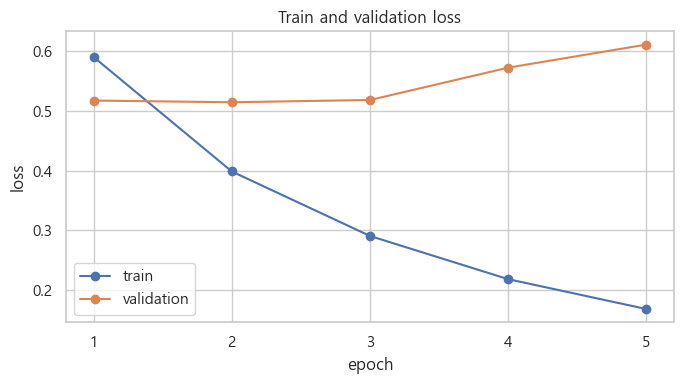

In [69]:
history = []

if RUN_TRAINING:
    best_validation_loss = float("inf")
    for epoch in range(EPOCHS):
        started = time.perf_counter()
        train_loss = train(model, optimizer, train_dataloader)
        validation_loss = evaluation(model, validation_dataloader)
        elapsed_minutes = (time.perf_counter() - started) / 60

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "validation_loss": validation_loss,
            "minutes": elapsed_minutes,
        })
        print(
            f"epoch {epoch + 1}/{EPOCHS} | train {train_loss:.4f} | "
            f"validation {validation_loss:.4f} | {elapsed_minutes:.1f}분"
        )

        if validation_loss < best_validation_loss:
            best_validation_loss = validation_loss
            torch.save(model.state_dict(), MODEL_PATH)
            print("Saved:", MODEL_PATH)

    history_df = pd.DataFrame(history)
    history_df.to_csv(RESULTS / "loss_history.csv", index=False, encoding="utf-8-sig")
    display(history_df)

    plt.figure(figsize=(7, 4))
    plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="train")
    plt.plot(history_df["epoch"], history_df["validation_loss"], marker="o", label="validation")
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.title("Train and validation loss")
    plt.xticks(history_df["epoch"])
    plt.legend()
    plt.tight_layout()
    plt.savefig(RESULTS / "loss_curve.png", dpi=160)
    plt.show()
else:
    print("RUN_TRAINING=False: 학습을 건너뜁니다.")

## 9. 최종 test 평가

이 셀은 모델 설정을 모두 validation으로 결정한 뒤 한 번만 실행합니다. raw baseline의 생성 방식은 greedy decoding(`num_beams=1`)으로 고정합니다.


In [70]:
def generate_predictions(model, dataloader):
    model.eval()
    predictions = []

    with torch.no_grad():
        for step, batch in enumerate(dataloader, start=1):
            input_ids, attention_mask, _ = [tensor.to(device) for tensor in batch]
            generated_ids = model.generate(
                input_ids=input_ids,
                attention_mask=attention_mask,
                max_length=MAX_TARGET_LENGTH,
                num_beams=1,
                do_sample=False,
            )
            predictions.extend(
                tokenizer.batch_decode(
                    generated_ids,
                    skip_special_tokens=True,
                    clean_up_tokenization_spaces=False,
                )
            )
            if step % 200 == 0:
                print(f"  generation {step:,}/{len(dataloader):,}")

    return [prediction.strip() for prediction in predictions]

if RUN_TRAINING:
    best_model = BartForConditionalGeneration.from_pretrained(
        MODEL_ID,
        revision=model_revision,
        use_safetensors=True,
    ).to(device)
    best_model.load_state_dict(torch.load(MODEL_PATH, map_location=device, weights_only=True))

    test_loss = evaluation(best_model, test_dataloader)
    test_predictions = generate_predictions(best_model, test_dataloader)
    test_references = split_frames["test"]["summary"].astype(str).tolist()

    rouge_metric = evaluate.load("rouge")
    rouge_scores = rouge_metric.compute(
        predictions=test_predictions,
        references=test_references,
        tokenizer=lambda text: text.split(),
        use_stemmer=False,
    )
    test_metrics = {
        "test_loss": test_loss,
        **{name: score * 100 for name, score in rouge_scores.items()},
    }

    prediction_df = split_frames["test"][[
        "row_id", "title", "document", "summary"
    ]].copy()
    prediction_df["prediction"] = test_predictions
    prediction_df.to_csv(
        RESULTS / "test_predictions.csv", index=False, encoding="utf-8-sig"
    )
    (RESULTS / "test_metrics.json").write_text(
        json.dumps(test_metrics, ensure_ascii=False, indent=2), encoding="utf-8"
    )

    display(pd.Series(test_metrics, name="raw baseline test"))
    display(prediction_df[["title", "summary", "prediction"]].head(10))
else:
    print("RUN_TRAINING=False: test 평가를 건너뜁니다.")

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


  generation 200/1,370
  generation 400/1,370
  generation 600/1,370
  generation 800/1,370
  generation 1,000/1,370
  generation 1,200/1,370


test_loss     0.512187
rouge1       34.609877
rouge2       28.942334
rougeL       31.755303
rougeLsum    31.726809
Name: raw baseline test, dtype: float64

,title,summary,prediction
0,아이트로닉스 차량용 복합기능형 졸음 방지 단말기 특허 출원,"아이일, 아이트로닉스는 차량용 복합기능형 졸음 방지 단말기 특허를 출원했다고 4일 밝혔으며 신규 특허는 자동차 주행 중 운전자의 졸음운전을 방지하는 상태 검출 기술에 관한 ...",아이엘사이언스의 자회사 아이트로닉스는 자동차 주행 중 운전자의 졸음운전을 방지하는 상태 검출 기술에 관한 차량용 복합기능형 졸음 방지 단말기 특허를 출원했다고 4일 밝혔으며...
1,뉴스페이스로 가는 한국… 우주기업 성장할 기술·터전 만든다,"한국형 우주발사체 누리호가 지난 6월 21일 전남 고흥 나로우주센터 발사대에서 성공적으로 발사됨에 따라, 우주산업 클러스터가 조성될 지역을 8월중 선정하는 등 누리호 설계 ...",한국형 우주발사체 누리호 가 지난 6월 21일 전남 고흥 나로우주센터 발사대에서 성공적으로 발사되어 뉴스페이스 시대를 앞당기기 위한 발걸음이 빨라졌으며 과학기술정보통신부는 ...
2,SP500 올 상반기 21%↓…50년래 최악 월가월부,대 대형주 중심의 미국 스탠더드앤드푸어스 S P 500 지수가 올 상반기 50여년만에 최악의 실적을 기록하고 30일 이하 미국 현지시간 뉴욕 증시 3대 지수도 모두 하락하며...,30일 이하 현지시간 뉴욕 증시 3대 지수가 모두 하락하며 부진한 상반기 실적으로 마감했고 일각에서는 경기침체 우려로 인해 추가 하락이 올 수 있다는 경고 메시지가 나오고 ...
3,풀무원 알래스칸 명태살 ‘볼카츠’ 출시,5일 5일 풀무원식품은 알래스카 청정해역의 신선한 명태살로 만든 연육을 동그랗게 빚은 후 빵가루를 묻혀 튀겨낸 '볼카츠'와 명태 연육을 감싸 고소하고 담백한 맛을 살린 '에...,5일 5일식품은 알래스카 청정해역의 신선한 명태살로 만든 연육을 바삭하게 튀겨낸 ‘볼카츠’를 출시했다고 5일 밝혔는데 신제품 ‘볼카츠’ 2종 통통새우 에그포테이토은 깨끗한 ...
4,일동제약 생산본부장에 강덕원 부사장 영입,일동제약은 생산본부장으로 강덕원 부사장을 영입했다고 지난 1일 밝혔으며 강덕원 본부장은 서울대학교와 서던캘리포니아대학교 USC 를 졸업하고 동대학원에서 생화학 및 분자생물학...,일동제약은 생산본부장으로 서울대학교와 서던캘리포니아대학교 USC 를 졸업하고 동대학원에서 생화학 및 분자생물학 석사학위를 취득한 강덕원 부사장을 영입했다고 지난 1일 밝혔다...
5,강릉커피산업 발전·애로기술 해결 의기투합…출연기관 업무협약,5일 기술회사인 커피커퍼가 KIST 강릉천연물연구소와 5일 커피 산업 발전을 위한 업무협약을 체결함에 따라 기업매출 확대 일자리 창출뿐만 아니라 더 많은 기업의 애로 기술 ...,한국과학기술연구원 이하 KIST 강릉천연물연구소 한국생산기술연구원 강원본부 한국기초과학지원연구원 춘천센터 농업회사법인 커피커퍼가 5일 커피 산업 발전을 위한 업무협약을 체결...
6,약세장에 펀드 회전율 5년새 최저…운용기관 방어적 운용 영향,매매에서 주식을 매매하는 빈도를 뜻하는 매매 회전율이 5년 만에 140%까지 떨어진 것은 연초부터 이어진 약세장에 기관투자자들이 상품을 방어적으로 운용하고 나선 영향으로 풀...,연초부터 이어진 약세장에 기관투자자들이 상품을 방어적으로 운용하고 나선 영향으로 6일 한국펀드평가에 따르면 지난 2분기 기준 국내 공모펀드의 연평균 매매 회전율은 141.4...
7,코오롱 수소 밸류체인 플랫폼 구축… 생산부터 발전까지 원스톱,코오롱그룹은 6일 동대문 디자인플라자에서 열린 ‘코리아 H2 비즈니스 서밋 2022 인베스터데이’에 참가해 그룹이 보유한 첨단기술을 바탕으로 수소 생산부터 운송 저장 발전사...,코오롱그룹은 6일 동대문 디자인플라자에서 열린 ‘코리아 H2 비즈니스 서밋 2022 인베스터데이’에 참가해 수소 생산부터 운송 저장 발전사업까지 아우르는 코오롱 H2 플랫폼...
8,에너지정책 유턴 재생에너지 대신 원전으로,"정부가 정부가 오늘 국무회의에서 의결한 새 에너지 정책 방향의 주요 내용인 원자력 발전의 비중을 더 늘리겠다는 계획과 탄소 감축의 핵심인 석탄 화력발전소를 어떻게 줄일지, ...",정부가 새 에너지 정책 방향을 오늘 국무회의에서 의결한 가운데 원전의 비중을 2030년까지 30% 이상으로 늘리기로 한 것과 달리 석탄 화력발전소를 어떻게 줄일지 신재생에너...
9,산업 디지털전환법 오늘부터 시행…“기업 간 협업 프로젝트 지원 확대”,산업디지털전환촉진법 시행을 하루 앞둔 지난 4일 산업부 장영진 제1차관은 산업 디지털 전환 기업 간담회를 열고 올 하반기 수립할 산업 디지털 전환 종합계획 의견수렴 작업에 ...,산업통상자원부는 5일부터 3년마다 종합계획을 수립해 산업계의 디지털 전환을 지원하는 산업디지털전환촉진법이 시행됨에 따라 기업 간 데이터 연결과 활용 환경 조성 등 다양한 지...


## 10. 실험 설정과 산출물 저장

In [71]:
run_config = {
    "dataset_id": DATASET_ID,
    "dataset_revision": dataset_revision,
    "model_id": MODEL_ID,
    "model_revision": model_revision,
    "seed": SEED,
    "max_source_length": MAX_SOURCE_LENGTH,
    "max_target_length": MAX_TARGET_LENGTH,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "test_policy": "original test fixed; overlapping non-test rows excluded",
    "generation": {"num_beams": 1, "do_sample": False},
    "split_counts": {split: len(frame) for split, frame in split_frames.items()},
    "excluded_test_overlap": int(
        manifest["assigned_split"].eq("excluded_test_overlap").sum()
    ),
}
(RESULTS / "run_config.json").write_text(
    json.dumps(run_config, ensure_ascii=False, indent=2), encoding="utf-8"
)

for path in sorted(RESULTS.rglob("*")):
    if path.is_file():
        print("-", path.relative_to(PROJECT))

- results\03-2_baseline_raw_data\best_model_state.pt
- results\03-2_baseline_raw_data\loss_curve.png
- results\03-2_baseline_raw_data\loss_history.csv
- results\03-2_baseline_raw_data\run_config.json
- results\03-2_baseline_raw_data\split_leakage_check.csv
- results\03-2_baseline_raw_data\split_manifest.csv
- results\03-2_baseline_raw_data\split_summary.csv
- results\03-2_baseline_raw_data\test_metrics.json
- results\03-2_baseline_raw_data\test_predictions.csv



---

# 원본 단계: `03-3_baseline_lead.ipynb`


# 03-3. Lead baseline

이 노트북에서 하는 일: 뉴스 원문의 앞 50어절 또는 80어절을 그대로 요약으로 사용하고, 원본 test summary와 비교한다.

이 실험은 모델을 사용하지 않는 규칙 기반 기준선입니다.

- 학습과 파인튜닝을 하지 않는다.
- 원본 test 2,740건을 그대로 사용한다.
- `summary`는 Lead 요약 생성에 사용하지 않고 ROUGE 평가에만 사용한다.
- 이 데이터는 문장부호가 부족하여 Lead-3 문장 대신 공백 기준 50·80어절을 비교한다.
- 이후 KoBART zero-shot 및 파인튜닝 결과가 단순한 기사 앞부분보다 좋은지 판단하는 기준이 된다.


## 1. 환경 및 설정

In [72]:
import os
import sys
from pathlib import Path

PROJECT = PROJECT_ROOT
assert PROJECT.exists(), "프로젝트 경로를 확인하세요."
assert Path(sys.prefix).resolve() == (PROJECT / ".venv").resolve(), (
    "커널을 Python 3.11 (Team4 News GPU)로 바꾸세요."
)

os.environ["HF_HOME"] = str(PROJECT / ".cache" / "huggingface")
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "120"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

RESULTS = PROJECT / "results" / "03-3_baseline_lead"
RESULTS.mkdir(parents=True, exist_ok=True)

SEED = 42
DATASET_ID = "daekeun-ml/naver-news-summarization-ko"
LEAD_LENGTHS = [50, 80]

print("Python:", sys.version.split()[0])
print("결과 폴더:", RESULTS)

Python: 3.11.9
결과 폴더: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\03-3_baseline_lead


In [73]:
import json
import random

import evaluate
import numpy as np
import pandas as pd
from datasets import load_dataset
from huggingface_hub import HfApi

random.seed(SEED)
np.random.seed(SEED)

## 2. 원본 test 데이터 로드

In [74]:
api = HfApi()
dataset_revision = api.dataset_info(DATASET_ID).sha
raw_dataset = load_dataset(DATASET_ID, revision=dataset_revision)

test_df = raw_dataset["test"].to_pandas().reset_index(drop=True)
test_df.insert(0, "source_index", np.arange(len(test_df), dtype=np.int64))
test_df.insert(0, "row_id", "test:" + test_df["source_index"].astype(str))

assert len(test_df) == 2740
assert test_df[["document", "summary"]].notna().all().all()
assert test_df["document"].str.strip().ne("").all()
assert test_df["summary"].str.strip().ne("").all()

print("dataset revision:", dataset_revision)
print("test rows:", len(test_df))
display(test_df[["title", "document", "summary"]].head(3))

dataset revision: 916dfe6aed651b2ecd9d04fa0a704f8953e90762
test rows: 2740


,title,document,summary
0,아이트로닉스 차량용 복합기능형 졸음 방지 단말기 특허 출원,아이엘사이언스의 자회사 아이트로닉스는 차량용 복합기능형 졸음 방지 단말기 특허를 출원했다고 4일 밝혔다. 신규 특허는 자동차 주행 중 운전자의 졸음운전을 방지하는 상태 검출...,"아이일, 아이트로닉스는 차량용 복합기능형 졸음 방지 단말기 특허를 출원했다고 4일 밝혔으며 신규 특허는 자동차 주행 중 운전자의 졸음운전을 방지하는 상태 검출 기술에 관한 ..."
1,뉴스페이스로 가는 한국… 우주기업 성장할 기술·터전 만든다,한국형 우주발사체 누리호 가 지난 6월 21일 전남 고흥 나로우주센터 발사대에서 날아올라 성공적으로 발사됐다. 한국항공우주연구원 제공 파이낸셜뉴스 한국형 우주발사체 누리호 ...,"한국형 우주발사체 누리호가 지난 6월 21일 전남 고흥 나로우주센터 발사대에서 성공적으로 발사됨에 따라, 우주산업 클러스터가 조성될 지역을 8월중 선정하는 등 누리호 설계 ..."
2,SP500 올 상반기 21%↓…50년래 최악 월가월부,닥터둠 루비니 주가 50% 폭락할 것 뉴욕 증시 3대지수 모두 하락 대형주 중심의 미국 스탠더드앤드푸어스 S P 500 지수가 올 상반기 50여년만에 최악의 실적을 기록했다...,대 대형주 중심의 미국 스탠더드앤드푸어스 S P 500 지수가 올 상반기 50여년만에 최악의 실적을 기록하고 30일 이하 미국 현지시간 뉴욕 증시 3대 지수도 모두 하락하며...


## 3. Lead-50·Lead-80 생성

가이드에서는 일반적인 Lead-3 대신 단어 수 기준을 권장합니다. 한국어에서는 공백으로 나눈 단위를 정확히는 **어절**이라고 하므로, 이 노트북에서는 앞 50어절과 80어절을 사용합니다.


In [75]:
def make_lead_summary(document, word_limit):
    words = str(document).split()
    return " ".join(words[:word_limit])

result_df = test_df[[
    "row_id", "title", "document", "summary", "category", "press", "link"
]].copy()

for word_limit in LEAD_LENGTHS:
    result_df[f"lead_{word_limit}"] = result_df["document"].map(
        lambda document: make_lead_summary(document, word_limit)
    )

assert result_df[[f"lead_{length}" for length in LEAD_LENGTHS]].notna().all().all()

display(result_df[["title", "summary", "lead_50", "lead_80"]].head(5))

,title,summary,lead_50,lead_80
0,아이트로닉스 차량용 복합기능형 졸음 방지 단말기 특허 출원,"아이일, 아이트로닉스는 차량용 복합기능형 졸음 방지 단말기 특허를 출원했다고 4일 밝혔으며 신규 특허는 자동차 주행 중 운전자의 졸음운전을 방지하는 상태 검출 기술에 관한 ...",아이엘사이언스의 자회사 아이트로닉스는 차량용 복합기능형 졸음 방지 단말기 특허를 출원했다고 4일 밝혔다. 신규 특허는 자동차 주행 중 운전자의 졸음운전을 방지하는 상태 검출...,아이엘사이언스의 자회사 아이트로닉스는 차량용 복합기능형 졸음 방지 단말기 특허를 출원했다고 4일 밝혔다. 신규 특허는 자동차 주행 중 운전자의 졸음운전을 방지하는 상태 검출...
1,뉴스페이스로 가는 한국… 우주기업 성장할 기술·터전 만든다,"한국형 우주발사체 누리호가 지난 6월 21일 전남 고흥 나로우주센터 발사대에서 성공적으로 발사됨에 따라, 우주산업 클러스터가 조성될 지역을 8월중 선정하는 등 누리호 설계 ...",한국형 우주발사체 누리호 가 지난 6월 21일 전남 고흥 나로우주센터 발사대에서 날아올라 성공적으로 발사됐다. 한국항공우주연구원 제공 파이낸셜뉴스 한국형 우주발사체 누리호 ...,한국형 우주발사체 누리호 가 지난 6월 21일 전남 고흥 나로우주센터 발사대에서 날아올라 성공적으로 발사됐다. 한국항공우주연구원 제공 파이낸셜뉴스 한국형 우주발사체 누리호 ...
2,SP500 올 상반기 21%↓…50년래 최악 월가월부,대 대형주 중심의 미국 스탠더드앤드푸어스 S P 500 지수가 올 상반기 50여년만에 최악의 실적을 기록하고 30일 이하 미국 현지시간 뉴욕 증시 3대 지수도 모두 하락하며...,닥터둠 루비니 주가 50% 폭락할 것 뉴욕 증시 3대지수 모두 하락 대형주 중심의 미국 스탠더드앤드푸어스 S P 500 지수가 올 상반기 50여년만에 최악의 실적을 기록했다...,닥터둠 루비니 주가 50% 폭락할 것 뉴욕 증시 3대지수 모두 하락 대형주 중심의 미국 스탠더드앤드푸어스 S P 500 지수가 올 상반기 50여년만에 최악의 실적을 기록했다...
3,풀무원 알래스칸 명태살 ‘볼카츠’ 출시,5일 5일 풀무원식품은 알래스카 청정해역의 신선한 명태살로 만든 연육을 동그랗게 빚은 후 빵가루를 묻혀 튀겨낸 '볼카츠'와 명태 연육을 감싸 고소하고 담백한 맛을 살린 '에...,파이낸셜뉴스 풀무원식품은 알래스카 청정해역의 신선한 명태살로 만든 연육을 바삭하게 튀겨낸 ‘볼카츠’를 출시했다고 5일 밝혔다. 신제품 ‘볼카츠’ 2종 통통새우 에그포테이토 ...,파이낸셜뉴스 풀무원식품은 알래스카 청정해역의 신선한 명태살로 만든 연육을 바삭하게 튀겨낸 ‘볼카츠’를 출시했다고 5일 밝혔다. 신제품 ‘볼카츠’ 2종 통통새우 에그포테이토 ...
4,일동제약 생산본부장에 강덕원 부사장 영입,일동제약은 생산본부장으로 강덕원 부사장을 영입했다고 지난 1일 밝혔으며 강덕원 본부장은 서울대학교와 서던캘리포니아대학교 USC 를 졸업하고 동대학원에서 생화학 및 분자생물학...,강덕원 일동제약 생산본부장. 일동제약 제공 일동제약은 생산본부장으로 강덕원 부사장을 영입했다고 지난 1일 밝혔다. 강덕원 본부장은 서울대학교와 서던캘리포니아대학교 USC 를...,강덕원 일동제약 생산본부장. 일동제약 제공 일동제약은 생산본부장으로 강덕원 부사장을 영입했다고 지난 1일 밝혔다. 강덕원 본부장은 서울대학교와 서던캘리포니아대학교 USC 를...


## 4. 한국어 ROUGE 평가

한국어가 제거되는 기본 영문 토큰화 문제를 피하기 위해 모든 베이스라인과 동일하게 공백 기준 토크나이저를 사용합니다.


In [76]:
rouge_metric = evaluate.load("rouge")
references = result_df["summary"].astype(str).tolist()

metric_rows = []
for word_limit in LEAD_LENGTHS:
    prediction_column = f"lead_{word_limit}"
    predictions = result_df[prediction_column].astype(str).tolist()
    scores = rouge_metric.compute(
        predictions=predictions,
        references=references,
        tokenizer=lambda text: text.split(),
        use_stemmer=False,
    )

    prediction_word_counts = result_df[prediction_column].str.split().str.len()
    reference_word_counts = result_df["summary"].str.split().str.len()
    metric_rows.append({
        "strategy": f"lead_{word_limit}",
        "word_limit": word_limit,
        "rouge1": scores["rouge1"] * 100,
        "rouge2": scores["rouge2"] * 100,
        "rougeL": scores["rougeL"] * 100,
        "rougeLsum": scores["rougeLsum"] * 100,
        "average_prediction_words": prediction_word_counts.mean(),
        "average_reference_words": reference_word_counts.mean(),
        "short_document_count": int(prediction_word_counts.lt(word_limit).sum()),
        "evaluated_rows": len(result_df),
    })

metrics_df = pd.DataFrame(metric_rows)
display(metrics_df.round(4))

,strategy,word_limit,rouge1,rouge2,rougeL,rougeLsum,average_prediction_words,average_reference_words,short_document_count,evaluated_rows
0,lead_50,50,46.0085,37.6325,39.2564,39.2702,48.0281,42.1496,261,2740
1,lead_80,80,46.4417,39.2197,39.7188,39.7100,74.0088,42.1496,453,2740


## 5. 두 Lead 기준 비교

In [77]:
best_row = metrics_df.loc[metrics_df["rougeL"].idxmax()]
print("ROUGE-L 기준 더 높은 방식:", best_row["strategy"])
print("ROUGE-L:", round(best_row["rougeL"], 4))

comparison_columns = ["title", "summary", "lead_50", "lead_80"]
display(result_df[comparison_columns].head(10))

ROUGE-L 기준 더 높은 방식: lead_80
ROUGE-L: 39.7188


,title,summary,lead_50,lead_80
0,아이트로닉스 차량용 복합기능형 졸음 방지 단말기 특허 출원,"아이일, 아이트로닉스는 차량용 복합기능형 졸음 방지 단말기 특허를 출원했다고 4일 밝혔으며 신규 특허는 자동차 주행 중 운전자의 졸음운전을 방지하는 상태 검출 기술에 관한 ...",아이엘사이언스의 자회사 아이트로닉스는 차량용 복합기능형 졸음 방지 단말기 특허를 출원했다고 4일 밝혔다. 신규 특허는 자동차 주행 중 운전자의 졸음운전을 방지하는 상태 검출...,아이엘사이언스의 자회사 아이트로닉스는 차량용 복합기능형 졸음 방지 단말기 특허를 출원했다고 4일 밝혔다. 신규 특허는 자동차 주행 중 운전자의 졸음운전을 방지하는 상태 검출...
1,뉴스페이스로 가는 한국… 우주기업 성장할 기술·터전 만든다,"한국형 우주발사체 누리호가 지난 6월 21일 전남 고흥 나로우주센터 발사대에서 성공적으로 발사됨에 따라, 우주산업 클러스터가 조성될 지역을 8월중 선정하는 등 누리호 설계 ...",한국형 우주발사체 누리호 가 지난 6월 21일 전남 고흥 나로우주센터 발사대에서 날아올라 성공적으로 발사됐다. 한국항공우주연구원 제공 파이낸셜뉴스 한국형 우주발사체 누리호 ...,한국형 우주발사체 누리호 가 지난 6월 21일 전남 고흥 나로우주센터 발사대에서 날아올라 성공적으로 발사됐다. 한국항공우주연구원 제공 파이낸셜뉴스 한국형 우주발사체 누리호 ...
2,SP500 올 상반기 21%↓…50년래 최악 월가월부,대 대형주 중심의 미국 스탠더드앤드푸어스 S P 500 지수가 올 상반기 50여년만에 최악의 실적을 기록하고 30일 이하 미국 현지시간 뉴욕 증시 3대 지수도 모두 하락하며...,닥터둠 루비니 주가 50% 폭락할 것 뉴욕 증시 3대지수 모두 하락 대형주 중심의 미국 스탠더드앤드푸어스 S P 500 지수가 올 상반기 50여년만에 최악의 실적을 기록했다...,닥터둠 루비니 주가 50% 폭락할 것 뉴욕 증시 3대지수 모두 하락 대형주 중심의 미국 스탠더드앤드푸어스 S P 500 지수가 올 상반기 50여년만에 최악의 실적을 기록했다...
3,풀무원 알래스칸 명태살 ‘볼카츠’ 출시,5일 5일 풀무원식품은 알래스카 청정해역의 신선한 명태살로 만든 연육을 동그랗게 빚은 후 빵가루를 묻혀 튀겨낸 '볼카츠'와 명태 연육을 감싸 고소하고 담백한 맛을 살린 '에...,파이낸셜뉴스 풀무원식품은 알래스카 청정해역의 신선한 명태살로 만든 연육을 바삭하게 튀겨낸 ‘볼카츠’를 출시했다고 5일 밝혔다. 신제품 ‘볼카츠’ 2종 통통새우 에그포테이토 ...,파이낸셜뉴스 풀무원식품은 알래스카 청정해역의 신선한 명태살로 만든 연육을 바삭하게 튀겨낸 ‘볼카츠’를 출시했다고 5일 밝혔다. 신제품 ‘볼카츠’ 2종 통통새우 에그포테이토 ...
4,일동제약 생산본부장에 강덕원 부사장 영입,일동제약은 생산본부장으로 강덕원 부사장을 영입했다고 지난 1일 밝혔으며 강덕원 본부장은 서울대학교와 서던캘리포니아대학교 USC 를 졸업하고 동대학원에서 생화학 및 분자생물학...,강덕원 일동제약 생산본부장. 일동제약 제공 일동제약은 생산본부장으로 강덕원 부사장을 영입했다고 지난 1일 밝혔다. 강덕원 본부장은 서울대학교와 서던캘리포니아대학교 USC 를...,강덕원 일동제약 생산본부장. 일동제약 제공 일동제약은 생산본부장으로 강덕원 부사장을 영입했다고 지난 1일 밝혔다. 강덕원 본부장은 서울대학교와 서던캘리포니아대학교 USC 를...
5,강릉커피산업 발전·애로기술 해결 의기투합…출연기관 업무협약,5일 기술회사인 커피커퍼가 KIST 강릉천연물연구소와 5일 커피 산업 발전을 위한 업무협약을 체결함에 따라 기업매출 확대 일자리 창출뿐만 아니라 더 많은 기업의 애로 기술 ...,KIST강릉천연물연구소 등 5일 기업 지원·경제활성화 앞장 약속 한국과학기술연구원 KIST 로고 한국과학기술연구원 제공 한국과학기술연구원 KIST 로고 강릉 연합뉴스 유형재...,KIST강릉천연물연구소 등 5일 기업 지원·경제활성화 앞장 약속 한국과학기술연구원 KIST 로고 한국과학기술연구원 제공 한국과학기술연구원 KIST 로고 강릉 연합뉴스 유형재...
6,약세장에 펀드 회전율 5년새 최저…운용기관 방어적 운용 영향,매매에서 주식을 매매하는 빈도를 뜻하는 매매 회전율이 5년 만에 140%까지 떨어진 것은 연초부터 이어진 약세장에 기관투자자들이 상품을 방어적으로 운용하고 나선 영향으로 풀...,매매 수수료 절감 목적도 펀드에서 주식을 매매하는 빈도를 뜻하는 매매 회전율이 5년 만에 최저치를 기록했다. 연초부터 이어진 약세장에 기관투자자들이 상품을 방어적으로 운용하...,매매 수수료 절감 목적도 펀드에서 주식을 매매하는 빈도를 뜻하는 매매 회전율이 5년 만에 최저치를 기록했다. 연초부터 이어진 약세장에 기관투자자들이 상품을 방어적으로 운용하...
7,코오롱 수소 밸류체인 플랫폼 구축… 생산부터 발전까지 원스톱,코오롱그룹은 6일 동대문 디자인플라자에서 열린 ‘코리아 H2 비즈니스 서밋 2022 인베스터데이’에 참가해 그룹이 보유한 첨단기술을 바탕으로 수소 생산부터 운송 저장 발전사...,‘코오롱 H2 플랫폼’ 밸류체인 플랫폼 발표 계열사간 역량 결집과 동시에 대외 파트너십 구축 6일 동대문 DDP에서 열린 코리아 H2서밋 인베스터데이에 참석한 코오롱인더스트...,‘코오롱 H2 플랫폼’ 밸류체인 플랫폼 발표 계열사간 역량 결집과 동시에 대외 파트너십 구축 6일 동대문 DDP에서 열린 코리아 H2서밋 인베스터데이에 참석한 코오롱인더스트...
8,에너지정책 유턴 재생에너지 대신 원전으로,"정부가 정부가 오늘 국무회의에서 의결한 새 에너지 정책 방향의 주요 내용인 원자력 발전의 비중을 더 늘리겠다는 계획과 탄소 감축의 핵심인 석탄 화력발전소를 어떻게 줄일지, ...",뉴스데스크 앵커 정부가 새 에너지 정책 방향을 오늘 국무회의에서 의결했습니다. 예상대로 원자력 발전의 비중을 더 늘리겠다고 했는데요 탄소 감축의 핵심인 석탄 화력발전소를 어...,뉴스데스크 앵커 정부가 새 에너지 정책 방향을 오늘 국무회의에서 의결했습니다. 예상대로 원자력 발전의 비중을 더 늘리겠다고 했는데요 탄소 감축의 핵심인 석탄 화력발전소를 어...
9,산업 디지털전환법 오늘부터 시행…“기업 간 협업 프로젝트 지원 확대”,산업디지털전환촉진법 시행을 하루 앞둔 지난 4일 산업부 장영진 제1차관은 산업 디지털 전환 기업 간담회를 열고 올 하반기 수립할 산업 디지털 전환 종합계획 의견수렴 작업에 ...,연내 첫 번째 종합계획 수립해 지원사업 본격 추진 이데일리 김형욱 기자 정부가 3년마다 종합계획을 수립해 산업계의 디지털 전환을 지원하는 산업디지털전환촉진법이 5일부터 시행...,연내 첫 번째 종합계획 수립해 지원사업 본격 추진 이데일리 김형욱 기자 정부가 3년마다 종합계획을 수립해 산업계의 디지털 전환을 지원하는 산업디지털전환촉진법이 5일부터 시행...


## 6. 결과 저장

In [78]:
result_df.to_csv(
    RESULTS / "lead_test_predictions.csv",
    index=False,
    encoding="utf-8-sig",
)
metrics_df.to_csv(
    RESULTS / "lead_metrics.csv",
    index=False,
    encoding="utf-8-sig",
)

run_config = {
    "experiment": "rule-based Lead baseline",
    "dataset_id": DATASET_ID,
    "dataset_revision": dataset_revision,
    "evaluation_split": "original test",
    "test_rows": len(test_df),
    "lead_lengths": LEAD_LENGTHS,
    "unit": "whitespace-separated Korean eojeol",
    "trained": False,
    "summary_used_for_generation": False,
    "summary_used_only_for_evaluation": True,
    "rouge_tokenizer": "whitespace split",
    "seed": SEED,
}
(RESULTS / "run_config.json").write_text(
    json.dumps(run_config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("저장 완료")
for path in sorted(RESULTS.rglob("*")):
    if path.is_file():
        print("-", path.relative_to(PROJECT))

저장 완료
- results\03-3_baseline_lead\lead_metrics.csv
- results\03-3_baseline_lead\lead_test_predictions.csv
- results\03-3_baseline_lead\run_config.json



---

# 원본 단계: `04-1_raw_candidate_review.ipynb`


# 04-1. 원본 데이터 노이즈 후보 분류

원본을 수정하지 않고 전처리 후보를 유형별 CSV로 저장한다. repeat_4gram은 같은 정규화 4어절이 3회 이상 등장하는 경우다.

In [79]:
import os, re, sys
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
from datasets import load_dataset
from huggingface_hub import HfApi

PROJECT = PROJECT_ROOT
assert Path(sys.prefix).resolve() == (PROJECT / ".venv").resolve(), "커널을 Python 3.11 (Team4 News GPU)로 바꾸세요."
os.environ["HF_HOME"] = str(PROJECT / ".cache" / "huggingface")
DATASET_ID = "daekeun-ml/naver-news-summarization-ko"
RESULTS = PROJECT / "review_data" / "04-1_raw_candidates"
RESULTS.mkdir(parents=True, exist_ok=True)
word_pattern = re.compile(r"[가-힣A-Za-z0-9]+(?:[.,]\d+)?")
print("결과 폴더:", RESULTS)

결과 폴더: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\review_data\04-1_raw_candidates


In [80]:
revision = HfApi().dataset_info(DATASET_ID).sha
dataset = load_dataset(DATASET_ID, revision=revision)
frames=[]
for split in ["train", "validation", "test"]:
    frame=dataset[split].to_pandas().copy()
    frame.insert(0, "source_index", np.arange(len(frame)))
    frame.insert(0, "split", split)
    frame.insert(0, "row_id", split + ":" + frame.source_index.astype(str))
    frames.append(frame)
df=pd.concat(frames, ignore_index=True)

def words(text): return word_pattern.findall(str(text).lower())
def max_4gram(text):
    tokens=words(text); counts=Counter(tuple(tokens[i:i+4]) for i in range(len(tokens)-3))
    return max(counts.values(), default=0)
def overlap(document, summary):
    source=set(words(document)); target=words(summary)
    return np.nan if not target else sum(token in source for token in target)/len(target)
def numbers(text):
    text=re.sub(r"(?<=\d)\s+(?=\d)", "", str(text)).replace(",", "")
    return set(re.findall(r"\d+(?:\.\d+)?", text))

df["document_words"]=df.document.map(lambda x: len(words(x)))
df["document_chars"]=df.document.str.len(); df["summary_chars"]=df.summary.str.len()
df["char_compression_ratio"]=df.summary_chars/df.document_chars
df["max_same_4gram_occurrences"]=df.summary.map(max_4gram)
df["repeat_4gram"]=df.max_same_4gram_occurrences.ge(3)
df["summary_document_overlap"]=[overlap(d,s) for d,s in zip(df.document,df.summary)]
df["low_overlap"]=df.summary_document_overlap.lt(.30)
df["extreme_ratio"]=(df.char_compression_ratio.lt(.02)|df.char_compression_ratio.gt(.80))
df["summary_longer"]=df.summary_chars.gt(df.document_chars)
df["short_document"]=df.document_words.lt(30)
doc_numbers=df.document.map(numbers); sum_numbers=df.summary.map(numbers)
df["numbers_only_in_summary"]=[", ".join(sorted(s-d)) for d,s in zip(doc_numbers,sum_numbers)]
df["number_mismatch"]=df.numbers_only_in_summary.ne("")
df["has_url"]=df.document.str.contains(r"https?://|www\.",case=False,regex=True)
df["has_boilerplate"]=df.document.str.contains(r"무단\s*(?:전재|복제|배포)|재배포\s*금지|인터뷰\s*자료의\s*저작권|실제\s*방송\s*내용과\s*차이",regex=True)
df["replacement_char"]=df.document.str.contains("�",regex=False)
df["exact_document_summary_duplicate"]=df.duplicated(["document","summary"],keep=False)
summary_doc_n=df.groupby("summary").document.transform("nunique")
df["shared_summary_different_document"]=summary_doc_n.gt(1)


In [81]:
BASE=["row_id","split","source_index","date","category","press","title","link","document","summary","document_words","char_compression_ratio","summary_document_overlap","max_same_4gram_occurrences","numbers_only_in_summary"]
RULES={
 "01_repeat_4gram":df.repeat_4gram, "02_low_overlap":df.low_overlap,
 "03_extreme_ratio":df.extreme_ratio, "04_summary_longer":df.summary_longer,
 "05_number_mismatch":df.number_mismatch, "06_short_document":df.short_document,
 "07_url":df.has_url, "08_boilerplate":df.has_boilerplate,
 "09_replacement_char":df.replacement_char,
 "10_exact_document_summary_duplicate":df.exact_document_summary_duplicate,
 "11_shared_summary_different_document":df.shared_summary_different_document}
rows=[]
for name,mask in RULES.items():
    out=df.loc[mask,BASE].copy(); out["review_decision"]=""; out["memo"]=""
    out.to_csv(RESULTS/f"{name}.csv",index=False,encoding="utf-8-sig")
    rows.append({"file":f"{name}.csv","rows":len(out)})
summary=pd.DataFrame(rows); summary.to_csv(RESULTS/"00_export_summary.csv",index=False,encoding="utf-8-sig")
pd.DataFrame([{"dataset_id":DATASET_ID,"dataset_revision":revision,"policy":"read-only candidate export"}]).to_csv(RESULTS/"00_run_info.csv",index=False,encoding="utf-8-sig")
display(summary)

,file,rows
0,01_repeat_4gram.csv,1376
1,02_low_overlap.csv,6
2,03_extreme_ratio.csv,2823
3,04_summary_longer.csv,2132
4,05_number_mismatch.csv,777
5,06_short_document.csv,1514
6,07_url.csv,83
7,08_boilerplate.csv,53
8,09_replacement_char.csv,4
9,10_exact_document_summary_duplicate.csv,3785



---

# 원본 단계: `04-2_clean_dataset.ipynb`


# 04-2. 확정 규칙 기반 데이터 정제

같은 4어절이 3회 이상 반복되는 summary 행을 제외하고, document에서 URL·명확한 저작권/방송 안내 문구·깨진 대체문자만 제거한다. 기자명과 언론사명은 보존한다.

In [82]:
import os, re, sys
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
from datasets import load_dataset
from huggingface_hub import HfApi

PROJECT = PROJECT_ROOT
assert Path(sys.prefix).resolve()==(PROJECT/".venv").resolve(), "커널을 Python 3.11 (Team4 News GPU)로 바꾸세요."
os.environ["HF_HOME"]=str(PROJECT/".cache"/"huggingface")
DATASET_ID="daekeun-ml/naver-news-summarization-ko"
OUTPUT=PROJECT/"processed_data"/"04-2_cleaned"
RESULTS=PROJECT/"review_data"/"04-2_cleaning"
OUTPUT.mkdir(parents=True,exist_ok=True); RESULTS.mkdir(parents=True,exist_ok=True)
word_pattern=re.compile(r"[가-힣A-Za-z0-9]+(?:[.,]\d+)?")


In [83]:
def max_4gram(text):
    tokens=word_pattern.findall(str(text).lower())
    counts=Counter(tuple(tokens[i:i+4]) for i in range(len(tokens)-3))
    return max(counts.values(),default=0)
URL=re.compile(r"(?i)\b(?:https?://|www\.)[^\s<>()\[\]{}]+")
BOILERPLATES=[
 re.compile(r"국내에서만\s*사용가능\.?\s*재배포\s*금지\.?\s*DB\s*금지\.?\s*For\s*Use\s*Only\s*in\s*the\s*Republic\s*of\s*Korea\.?\s*(?:No\s*)?Redistribution\s*Prohibited",re.I),
 re.compile(r"무단\s*(?:전재|복제|배포)\s*(?:및\s*)?재배포\s*금지\.?",re.I),
 re.compile(r"재배포\s*금지\.?",re.I),
 re.compile(r"인터뷰\s*자료의\s*저작권은\s*[^.]{0,120}(?:있습니다|있다)\.?",re.I),
 re.compile(r"(?:전문\s*게재나?\s*)?인터뷰\s*인용\s*보도\s*시\s*[^.]{0,180}(?:바랍니다|바란다)\.?",re.I),
 re.compile(r"인용\s*보도\s*시\s*출처를\s*[^.]{0,120}(?:바랍니다|바란다)\.?",re.I),
 re.compile(r"아래\s*텍스트는\s*실제\s*방송\s*내용과\s*차이가\s*있을\s*수\s*있으니\s*[^.]{0,180}(?:바랍니다|바란다)\.?",re.I)]
def clean_document(text):
    original=str(text); cleaned,url_n=URL.subn("",original); boiler_n=0
    for pattern in BOILERPLATES:
        cleaned,n=pattern.subn("",cleaned); boiler_n+=n
    replacement_n=cleaned.count("�"); cleaned=cleaned.replace("�"," ")
    cleaned=re.sub(r"[ \t]+"," ",cleaned); cleaned=re.sub(r" *\n *","\n",cleaned).strip()
    return cleaned,url_n,boiler_n,replacement_n

revision=HfApi().dataset_info(DATASET_ID).sha; dataset=load_dataset(DATASET_ID,revision=revision)
frames=[]
for split in ["train","validation","test"]:
    frame=dataset[split].to_pandas().copy(); frame.insert(0,"source_index",np.arange(len(frame)))
    frame.insert(0,"split",split); frame.insert(0,"row_id",split+":"+frame.source_index.astype(str))
    frame["max_same_4gram_occurrences"]=frame.summary.map(max_4gram); frame["repeat_4gram"]=frame.max_same_4gram_occurrences.ge(3)
    frames.append(frame)
raw=pd.concat(frames,ignore_index=True); excluded=raw[raw.repeat_4gram].copy(); clean=raw[~raw.repeat_4gram].copy()
processed=clean.document.map(clean_document); clean.insert(clean.columns.get_loc("document")+1,"document_original",clean.document)
clean["document"]=processed.map(lambda x:x[0]); clean["url_removed"]=processed.map(lambda x:x[1])
clean["boilerplate_removed"]=processed.map(lambda x:x[2]); clean["replacement_char_removed"]=processed.map(lambda x:x[3])
clean["document_changed"]=clean.document.ne(clean.document_original)
assert clean.document.str.strip().ne("").all()


In [84]:
for split,frame in clean.groupby("split",sort=False): frame.to_csv(OUTPUT/f"{split}.csv",index=False,encoding="utf-8-sig")
excluded[["row_id","split","title","link","document","summary","max_same_4gram_occurrences"]].to_csv(RESULTS/"excluded_repeat_4gram_rows.csv",index=False,encoding="utf-8-sig")
changed=clean[clean.document_changed][["row_id","split","title","document_original","document","url_removed","boilerplate_removed","replacement_char_removed"]].copy()
changed.to_csv(RESULTS/"changed_document_comparison.csv",index=False,encoding="utf-8-sig")
summary=[]
for split in ["train","validation","test"]:
    before=raw[raw.split.eq(split)]; after=clean[clean.split.eq(split)]
    summary.append({"split":split,"original_rows":len(before),"repeat_excluded":int(before.repeat_4gram.sum()),"clean_rows":len(after),"documents_changed":int(after.document_changed.sum()),"urls_removed":int(after.url_removed.sum()),"boilerplates_removed":int(after.boilerplate_removed.sum()),"replacement_chars_removed":int(after.replacement_char_removed.sum())})
summary=pd.DataFrame(summary); summary.to_csv(RESULTS/"cleaning_summary.csv",index=False,encoding="utf-8-sig")
pd.DataFrame([{"dataset_id":DATASET_ID,"dataset_revision":revision,"output_data":str(OUTPUT),"policy":"drop repeat_4gram>=3; remove URL/explicit boilerplate/U+FFFD; preserve press and reporter names"}]).to_csv(RESULTS/"run_info.csv",index=False,encoding="utf-8-sig")
display(summary)

,split,original_rows,repeat_excluded,clean_rows,documents_changed,urls_removed,boilerplates_removed,replacement_chars_removed
0,train,22194,1121,21073,104,73,52,7
1,validation,2466,121,2345,9,7,8,0
2,test,2740,134,2606,16,20,2,0



---

# 원본 단계: `04-3_dedup_group_split.ipynb`


# 04-3. 완전 중복 제거 및 누수 방지 그룹 분할

모델이 사용하는 document+summary 완전 중복을 하나만 남기고, 같은 document 또는 같은 summary를 공유하는 행을 하나의 연결 그룹으로 묶는다. test는 고정하고 test 그룹과 겹치는 train/validation 행은 제외한다.

In [85]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd

PROJECT = PROJECT_ROOT
assert Path(sys.prefix).resolve()==(PROJECT/".venv").resolve(), "커널을 Python 3.11 (Team4 News GPU)로 바꾸세요."
INPUT=PROJECT/"processed_data"/"04-2_cleaned"
OUTPUT=PROJECT/"processed_data"/"04-3_final"
RESULTS=PROJECT/"review_data"/"04-3_dedup_group_split"
assert INPUT.exists(), "먼저 04-2를 실행하세요."
OUTPUT.mkdir(parents=True,exist_ok=True); RESULTS.mkdir(parents=True,exist_ok=True)


In [86]:
splits=["train","validation","test"]
df=pd.concat([pd.read_csv(INPUT/f"{s}.csv") for s in splits],ignore_index=True)
assert df.row_id.is_unique
priority={"test":0,"validation":1,"train":2}
ordered=df.assign(_priority=df.split.map(priority),_position=np.arange(len(df))).sort_values(["_priority","source_index","_position"])
ordered["keep_exact"]=~ordered.duplicated(["document","summary"],keep="first")
df=df.merge(ordered[["row_id","keep_exact"]],on="row_id",validate="one_to_one")
exact_excluded=df[~df.keep_exact].copy(); work=df[df.keep_exact].copy().reset_index(drop=True)

# 같은 document 또는 같은 summary를 공유하면 같은 연결 요소로 묶습니다.
parent=list(range(len(work)))
def find(x):
    while parent[x]!=x:
        parent[x]=parent[parent[x]]; x=parent[x]
    return x
def union(a,b):
    ra,rb=find(a),find(b)
    if ra!=rb: parent[rb]=ra
for column in ["document","summary"]:
    for indices in work.groupby(column,sort=False).indices.values():
        indices=list(indices)
        for index in indices[1:]: union(indices[0],index)
work["group_id"]=[find(i) for i in range(len(work))]
group_splits=work.groupby("group_id").split.agg(set)
def destination(values):
    if "test" in values: return "test"
    if "validation" in values: return "validation"
    return "train"
destinations=group_splits.map(destination)
work["assigned_split"]=work.group_id.map(destinations)
work["keep_group"]=~((work.assigned_split=="test")&(work.split!="test"))
work["split_action"]="kept"
work.loc[~work.keep_group,"split_action"]="excluded_test_overlap"
moved=work.keep_group & work.split.ne(work.assigned_split)
work.loc[moved,"split_action"]="moved_to_"+work.loc[moved,"assigned_split"]


In [87]:
saved=[]
for split in splits:
    output=work[work.keep_group & work.assigned_split.eq(split)].copy(); output.to_csv(OUTPUT/f"{split}.csv",index=False,encoding="utf-8-sig"); saved.append(output)
final=pd.concat(saved,ignore_index=True)
assert final.duplicated(["document","summary"]).sum()==0
assert final.groupby("document").assigned_split.nunique().max()==1
assert final.groupby("summary").assigned_split.nunique().max()==1
assert len(final[final.split.eq("test")])==len(work[work.split.eq("test")])
exact_excluded[["row_id","split","title","link","document","summary"]].to_csv(RESULTS/"excluded_exact_duplicates.csv",index=False,encoding="utf-8-sig")
work[["row_id","split","assigned_split","group_id","split_action","title","link"]].to_csv(RESULTS/"group_split_manifest.csv",index=False,encoding="utf-8-sig")
summary=pd.DataFrame({"split":splits,"input_rows":[int((df.split==s).sum()) for s in splits],"exact_duplicates_excluded":[int(((df.split==s)&~df.keep_exact).sum()) for s in splits],"final_rows":[int((final.assigned_split==s).sum()) for s in splits],"test_overlap_excluded":[int(((work.split==s)&~work.keep_group).sum()) for s in splits],"moved_in":[int(((final.assigned_split==s)&(final.split!=s)).sum()) for s in splits]})
summary.to_csv(RESULTS/"split_summary.csv",index=False,encoding="utf-8-sig")
pd.DataFrame([{"input_data":str(INPUT),"output_data":str(OUTPUT),"exact_key":"cleaned document + summary","group_rule":"connected component of exact document OR exact summary","test_policy":"original test fixed; overlapping non-test rows excluded"}]).to_csv(RESULTS/"run_info.csv",index=False,encoding="utf-8-sig")
display(summary)

,split,input_rows,exact_duplicates_excluded,final_rows,test_overlap_excluded,moved_in
0,train,21073,1831,19236,4,0
1,validation,2345,106,2240,1,2
2,test,2606,42,2564,0,0



---

# 원본 단계: `04-4_final_quality_review.ipynb`


# 04-4. 최종 데이터 품질 재검토

04-3 최종 데이터를 수정하지 않고 남은 품질 후보를 유형별 CSV로 저장한다. 길이와 숫자 규칙은 자동 삭제 기준이 아니라 수동 검토 후보이다.

In [88]:
import re, sys
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd

PROJECT = PROJECT_ROOT
assert Path(sys.prefix).resolve()==(PROJECT/".venv").resolve(), "커널을 Python 3.11 (Team4 News GPU)로 바꾸세요."
INPUT=PROJECT/"processed_data"/"04-3_final"
RESULTS=PROJECT/"review_data"/"04-4_final_quality_review"
assert INPUT.exists(), "먼저 04-3을 실행하세요."
RESULTS.mkdir(parents=True,exist_ok=True)
word_pattern=re.compile(r"[가-힣A-Za-z0-9]+(?:[.,]\d+)?")


In [89]:
df=pd.concat([pd.read_csv(INPUT/f"{s}.csv") for s in ["train","validation","test"]],ignore_index=True)
def words(text): return word_pattern.findall(str(text).lower())
def max_4gram(text):
    tokens=words(text); counts=Counter(tuple(tokens[i:i+4]) for i in range(len(tokens)-3))
    return max(counts.values(),default=0)
def overlap(document,summary):
    source=set(words(document)); target=words(summary)
    return np.nan if not target else sum(token in source for token in target)/len(target)
def numbers(text):
    text=re.sub(r"(?<=\d)\s+(?=\d)","",str(text)).replace(",","")
    return set(re.findall(r"\d+(?:\.\d+)?",text))
df["document_words"]=df.document.map(lambda x:len(words(x))); df["document_chars"]=df.document.str.len(); df["summary_chars"]=df.summary.str.len()
df["char_compression_ratio"]=df.summary_chars/df.document_chars
df["max_same_4gram_occurrences"]=df.summary.map(max_4gram); df["repeat_4gram_remaining"]=df.max_same_4gram_occurrences.ge(3)
df["summary_document_overlap"]=[overlap(d,s) for d,s in zip(df.document,df.summary)]; df["low_overlap"]=df.summary_document_overlap.lt(.30)
df["extreme_ratio"]=(df.char_compression_ratio.lt(.02)|df.char_compression_ratio.gt(.80)); df["summary_longer"]=df.summary_chars.gt(df.document_chars)
df["short_document"]=df.document_words.lt(30); df["short_and_summary_longer"]=df.short_document & df.summary_longer
doc_numbers=df.document.map(numbers); sum_numbers=df.summary.map(numbers); df["numbers_only_in_summary"]=[", ".join(sorted(s-d)) for d,s in zip(doc_numbers,sum_numbers)]; df["number_mismatch"]=df.numbers_only_in_summary.ne("")
df["remaining_url"]=df.document.str.contains(r"https?://|www\.",case=False,regex=True)
df["remaining_boilerplate"]=df.document.str.contains(r"무단\s*(?:전재|복제|배포)|재배포\s*금지|인터뷰\s*자료의\s*저작권|실제\s*방송\s*내용과\s*차이",regex=True)
df["remaining_replacement_char"]=df.document.str.contains("�",regex=False)
assert not df.repeat_4gram_remaining.any(); assert not df.remaining_url.any(); assert not df.remaining_replacement_char.any()


In [90]:
BASE=["row_id","split","assigned_split","source_index","date","category","press","title","link","document","summary","document_words","document_chars","summary_chars","char_compression_ratio","summary_document_overlap","numbers_only_in_summary"]
RULES={"01_repeat_4gram_remaining":df.repeat_4gram_remaining,"02_low_overlap":df.low_overlap,"03_extreme_ratio":df.extreme_ratio,"04_summary_longer":df.summary_longer,"05_short_document":df.short_document,"06_short_and_summary_longer":df.short_and_summary_longer,"07_number_mismatch":df.number_mismatch,"08_remaining_boilerplate":df.remaining_boilerplate}
def save(frame,path):
    try: frame.to_csv(path,index=False,encoding="utf-8-sig"); return path.name
    except PermissionError:
        fallback=path.with_name(path.stem+"_latest"+path.suffix); frame.to_csv(fallback,index=False,encoding="utf-8-sig"); return fallback.name
rows=[]
for name,mask in RULES.items():
    out=df.loc[mask,BASE].copy(); out["review_decision"]=""; out["drop_reason"]=""; out["memo"]=""
    filename=save(out,RESULTS/f"{name}.csv"); rows.append({"file":filename,"rows":len(out)})
summary=pd.DataFrame(rows); save(summary,RESULTS/"00_export_summary.csv")
flag_cols=["extreme_ratio","summary_longer","short_document","short_and_summary_longer","number_mismatch","remaining_boilerplate"]
flagged=df[df[flag_cols].any(axis=1)][BASE+flag_cols].copy(); flagged["matched_rules"]=flagged[flag_cols].apply(lambda r:", ".join(r.index[r].tolist()),axis=1); flagged["review_decision"]=""; flagged["memo"]=""
save(flagged,RESULTS/"00_all_remaining_flagged_rows.csv")
pd.DataFrame([{"input_data":str(INPUT),"input_rows":len(df),"policy":"review only; no rows removed in 04-4"}]).to_csv(RESULTS/"00_run_info.csv",index=False,encoding="utf-8-sig")
display(summary); print("통합 후보:",len(flagged))

,file,rows
0,01_repeat_4gram_remaining.csv,0
1,02_low_overlap.csv,0
2,03_extreme_ratio.csv,1024
3,04_summary_longer.csv,610
4,05_short_document.csv,486
5,06_short_and_summary_longer.csv,414
6,07_number_mismatch.csv,643
7,08_remaining_boilerplate.csv,2


통합 후보: 1635



---

# 원본 단계: `05-1_noise_ablation.ipynb`


# 05-1. 자동 노이즈 제거 ablation 실험

전처리 단계만 달리한 A-0~A-3을 같은 KoBART 설정과 같은 test set으로 학습·평가한다.

- **A-0**: 원본 document/summary를 복원한 학습 데이터
- **A-1**: A-0에서 `repeat_4gram` 행 제거
- **A-2**: A-1 + URL·재배포 문구·깨진 문자 등 본문 기계 정제
- **A-3**: A-2 + 정확 중복 제거 + document/summary 그룹 split

평가에는 모든 실험에서 `processed_data/04-3_final/test.csv`를 사용한다. 따라서 A-0은 03-2의 원본 test 결과를 대체하지 않으며, 전처리 효과를 공정하게 비교하기 위한 재현 실험이다.

## 1. 설정

처음에는 `RUN_TRAINING=False`로 전체 데이터 구성과 누수 검사를 확인한다. 이상이 없으면 `True`로 바꾸고 실행한다. 이미 완료된 실험은 기본적으로 건너뛰므로 중간에 실행이 끊겨도 이어서 진행할 수 있다.

In [91]:
import gc
import hashlib
import json
import os
import random
import re
import sys
import time
from pathlib import Path

PROJECT = PROJECT_ROOT
assert PROJECT.exists(), "프로젝트 경로를 확인하세요."
assert Path(sys.prefix).resolve() == (PROJECT / ".venv").resolve(), (
    "커널을 Python 3.11 (Team4 News GPU)로 바꾸세요."
)

os.environ["HF_HOME"] = str(PROJECT / ".cache" / "huggingface")
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "120"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

RESULTS = PROJECT / "results" / "05-1_noise_ablation"
CLEANED_DIR = PROJECT / "processed_data" / "04-2_cleaned"
FINAL_DIR = PROJECT / "processed_data" / "04-3_final"
REPEAT_ROWS_PATH = PROJECT / "review_data" / "04-2_cleaning" / "excluded_repeat_4gram_rows.csv"
RAW_MANIFEST_PATH = PROJECT / "results" / "03-2_baseline_raw_data" / "split_manifest.csv"
RESULTS.mkdir(parents=True, exist_ok=True)

SEED = 42
MODEL_ID = "gogamza/kobart-base-v2"
MAX_SOURCE_LENGTH = 512
MAX_TARGET_LENGTH = 256
EPOCHS = 5
BATCH_SIZE = 2
LEARNING_RATE = 3e-5
EXPERIMENTS_TO_RUN = ["A0", "A1", "A2", "A3"]
RUN_TRAINING = True  # 데이터 검증 후 학습을 시작할 때만 True
SKIP_COMPLETED = True
SAVE_MODEL = True

print("Python:", sys.version.split()[0])
print("결과 폴더:", RESULTS)

Python: 3.11.9
결과 폴더: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\05-1_noise_ablation


In [92]:
import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from huggingface_hub import HfApi
from torch import optim
from torch.nn.utils import clip_grad_norm_
from torch.utils.data import DataLoader, RandomSampler, SequentialSampler, TensorDataset
from transformers import AutoTokenizer, BartForConditionalGeneration

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert device.type == "cuda", "CUDA를 사용할 수 없습니다."
print("device:", device)
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM(GB):", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))

device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
VRAM(GB): 7.96


## 2. A-0~A-3 데이터 구성

A-0~A-2의 train/validation 배정은 03-2에서 만든 누수 방지 manifest를 공통으로 사용한다. A-3은 04-3에서 확정한 중복 제거·그룹 split 결과를 그대로 사용한다. test는 네 실험 모두 A-3의 동일한 2,564행으로 고정한다.

In [93]:
required_paths = [
    *(CLEANED_DIR / f"{split}.csv" for split in ["train", "validation", "test"]),
    *(FINAL_DIR / f"{split}.csv" for split in ["train", "validation", "test"]),
    REPEAT_ROWS_PATH,
    RAW_MANIFEST_PATH,
]
missing_paths = [str(path) for path in required_paths if not path.exists()]
assert not missing_paths, f"필요한 파일이 없습니다: {missing_paths}"

base_columns = ["row_id", "title", "document", "summary"]

cleaned_parts = []
for source_split in ["train", "validation", "test"]:
    frame = pd.read_csv(CLEANED_DIR / f"{source_split}.csv")
    assert frame["split"].eq(source_split).all()
    cleaned_parts.append(frame)
cleaned_all = pd.concat(cleaned_parts, ignore_index=True)

repeat_rows = pd.read_csv(REPEAT_ROWS_PATH)
raw_kept = cleaned_all[["row_id", "split", "title", "document_original", "summary"]].rename(
    columns={"document_original": "document"}
)
raw_repeat = repeat_rows[["row_id", "split", "title", "document", "summary"]].copy()
raw_all = pd.concat([raw_kept, raw_repeat], ignore_index=True)
assert len(raw_all) == 27_400
assert raw_all["row_id"].is_unique

manifest = pd.read_csv(RAW_MANIFEST_PATH)[["row_id", "assigned_split"]]
assert manifest["row_id"].is_unique

def apply_baseline_manifest(frame):
    merged = frame.merge(manifest, on="row_id", how="left", validate="one_to_one")
    assert merged["assigned_split"].notna().all()
    return {
        split: merged.loc[merged["assigned_split"].eq(split), base_columns].reset_index(drop=True)
        for split in ["train", "validation"]
    }

a0 = apply_baseline_manifest(raw_all)
repeat_ids = set(repeat_rows["row_id"])
a1 = {
    split: frame.loc[~frame["row_id"].isin(repeat_ids)].reset_index(drop=True)
    for split, frame in a0.items()
}
a2 = apply_baseline_manifest(cleaned_all)
a3 = {
    split: pd.read_csv(FINAL_DIR / f"{split}.csv")[base_columns].reset_index(drop=True)
    for split in ["train", "validation"]
}
common_test = pd.read_csv(FINAL_DIR / "test.csv")[base_columns].reset_index(drop=True)

experiment_frames = {
    "A0": {**a0, "test": common_test},
    "A1": {**a1, "test": common_test},
    "A2": {**a2, "test": common_test},
    "A3": {**a3, "test": common_test},
}
experiment_labels = {
    "A0": "raw_train_common_clean_test",
    "A1": "remove_repeat_4gram",
    "A2": "repeat_removed_and_document_cleaned",
    "A3": "automatic_clean_dedup_group_split",
}

dataset_counts = pd.DataFrame([
    {"experiment": experiment, "description": experiment_labels[experiment],
     **{f"{split}_rows": len(frames[split]) for split in ["train", "validation", "test"]}}
    for experiment, frames in experiment_frames.items()
])
dataset_counts.to_csv(RESULTS / "dataset_counts.csv", index=False, encoding="utf-8-sig")
display(dataset_counts)

,experiment,description,train_rows,validation_rows,test_rows
0,A0,raw_train_common_clean_test,20839,2811,2564
1,A1,remove_repeat_4gram,20058,2605,2564
2,A2,repeat_removed_and_document_cleaned,20058,2605,2564
3,A3,automatic_clean_dedup_group_split,19236,2240,2564


In [94]:
space_pattern = re.compile(r"\s+")

def normalized_values(frame, column):
    return set(frame[column].astype(str).map(lambda value: space_pattern.sub(" ", value).strip()))

leakage_rows = []
common_test_ids = common_test["row_id"].tolist()
common_test_digest = hashlib.sha256(
    "\n".join(common_test_ids).encode("utf-8")
).hexdigest()

for experiment, frames in experiment_frames.items():
    assert frames["test"]["row_id"].tolist() == common_test_ids
    for split, frame in frames.items():
        assert frame["row_id"].is_unique, f"{experiment} {split}: row_id 중복"
        assert frame[["document", "summary"]].notna().all().all()
        assert frame["document"].astype(str).str.strip().ne("").all()
        assert frame["summary"].astype(str).str.strip().ne("").all()

    for column in ["document", "summary"]:
        values = {split: normalized_values(frames[split], column) for split in ["train", "validation", "test"]}
        for left, right in [("train", "validation"), ("train", "test"), ("validation", "test")]:
            overlap = len(values[left] & values[right])
            leakage_rows.append({
                "experiment": experiment, "column": column,
                "left": left, "right": right, "overlap": overlap,
            })

leakage_check = pd.DataFrame(leakage_rows)
assert leakage_check["overlap"].sum() == 0, "split 간 document/summary 중복을 확인하세요."
leakage_check.to_csv(RESULTS / "split_leakage_check.csv", index=False, encoding="utf-8-sig")
display(leakage_check)
print("공통 test 행 수:", len(common_test))
print("공통 test row_id SHA256:", common_test_digest)
print("검증 통과: 모든 실험의 test 동일, split 간 document/summary 중복 0")

,experiment,column,left,right,overlap
0,A0,document,train,validation,0
1,A0,document,train,test,0
2,A0,document,validation,test,0
3,A0,summary,train,validation,0
4,A0,summary,train,test,0
5,A0,summary,validation,test,0
6,A1,document,train,validation,0
7,A1,document,train,test,0
8,A1,document,validation,test,0
9,A1,summary,train,validation,0


공통 test 행 수: 2564
공통 test row_id SHA256: c65a547f703cc84cde13a25f95291d9cf2e45a1f96d4ca830e6b20b6bb6a588f
검증 통과: 모든 실험의 test 동일, split 간 document/summary 중복 0


## 3. 공통 토큰화·학습·평가 함수

각 실험을 시작할 때 seed, 모델, optimizer를 새로 초기화한다. 따라서 이전 실험의 학습 상태가 다음 실험으로 전달되지 않는다.

In [95]:
model_revision = HfApi().model_info(MODEL_ID).sha
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    revision=model_revision,
    clean_up_tokenization_spaces=False,
)
rouge_metric = evaluate.load("rouge")

def reset_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

def make_dataset(frame):
    source = tokenizer(
        text=frame["document"].astype(str).tolist(),
        padding="max_length", truncation=True, max_length=MAX_SOURCE_LENGTH,
        return_token_type_ids=False, return_tensors="pt",
    )
    target = tokenizer(
        text_target=frame["summary"].astype(str).tolist(),
        padding="max_length", truncation=True, max_length=MAX_TARGET_LENGTH,
        return_token_type_ids=False, return_tensors="pt",
    )
    labels = target["input_ids"].clone()
    labels[labels == tokenizer.pad_token_id] = -100
    return TensorDataset(source["input_ids"], source["attention_mask"], labels)

def make_loader(dataset, train_mode):
    sampler = RandomSampler(dataset) if train_mode else SequentialSampler(dataset)
    return DataLoader(dataset, sampler=sampler, batch_size=BATCH_SIZE, num_workers=0, pin_memory=True)

def train_one_epoch(model, optimizer, dataloader):
    model.train()
    total_loss = 0.0
    for step, batch in enumerate(dataloader, start=1):
        input_ids, attention_mask, labels = [tensor.to(device) for tensor in batch]
        optimizer.zero_grad()
        loss = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels).loss
        loss.backward()
        clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item()
        if step % 500 == 0:
            print(f"  step {step:,}/{len(dataloader):,} | loss {total_loss / step:.4f}")
    return total_loss / len(dataloader)

def evaluate_loss(model, dataloader):
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for batch in dataloader:
            input_ids, attention_mask, labels = [tensor.to(device) for tensor in batch]
            total_loss += model(
                input_ids=input_ids, attention_mask=attention_mask, labels=labels
            ).loss.item()
    return total_loss / len(dataloader)

def generate_predictions(model, dataloader):
    model.eval()
    predictions = []
    with torch.no_grad():
        for step, batch in enumerate(dataloader, start=1):
            input_ids, attention_mask, _ = [tensor.to(device) for tensor in batch]
            generated_ids = model.generate(
                input_ids=input_ids, attention_mask=attention_mask,
                max_length=MAX_TARGET_LENGTH, num_beams=1, do_sample=False,
            )
            predictions.extend(tokenizer.batch_decode(
                generated_ids, skip_special_tokens=True, clean_up_tokenization_spaces=False
            ))
            if step % 200 == 0:
                print(f"  generation {step:,}/{len(dataloader):,}")
    return [prediction.strip() for prediction in predictions]

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


## 4. A-0~A-3 순차 학습 및 공통 test 평가

실험별 폴더에 best checkpoint, epoch loss, test 예측, ROUGE 결과가 즉시 저장된다. `SKIP_COMPLETED=True`이면 `test_metrics.json`이 존재하는 실험은 다시 학습하지 않는다.

In [96]:
result_rows = []

if RUN_TRAINING:
    for experiment in EXPERIMENTS_TO_RUN:
        assert experiment in experiment_frames, f"알 수 없는 실험: {experiment}"
        experiment_dir = RESULTS / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        metrics_path = experiment_dir / "test_metrics.json"

        if SKIP_COMPLETED and metrics_path.exists():
            saved_metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
            result_rows.append(saved_metrics)
            print(f"[{experiment}] 완료 결과가 있어 건너뜁니다.")
            continue

        print(f"\n===== {experiment}: {experiment_labels[experiment]} =====")
        reset_seed()
        frames = experiment_frames[experiment]
        train_dataset = make_dataset(frames["train"])
        validation_dataset = make_dataset(frames["validation"])
        test_dataset = make_dataset(frames["test"])
        train_loader = make_loader(train_dataset, train_mode=True)
        validation_loader = make_loader(validation_dataset, train_mode=False)
        test_loader = make_loader(test_dataset, train_mode=False)
        print("train / validation / test:", len(train_dataset), len(validation_dataset), len(test_dataset))

        model = BartForConditionalGeneration.from_pretrained(
            MODEL_ID, revision=model_revision, use_safetensors=True
        ).to(device)
        optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, eps=1e-8)
        model_path = experiment_dir / "best_model_state.pt"
        best_validation_loss = float("inf")
        best_epoch = None
        history = []

        for epoch in range(1, EPOCHS + 1):
            started = time.perf_counter()
            train_loss = train_one_epoch(model, optimizer, train_loader)
            validation_loss = evaluate_loss(model, validation_loader)
            elapsed_minutes = (time.perf_counter() - started) / 60
            history.append({
                "experiment": experiment, "epoch": epoch,
                "train_loss": train_loss, "validation_loss": validation_loss,
                "minutes": elapsed_minutes,
            })
            print(
                f"{experiment} epoch {epoch}/{EPOCHS} | train {train_loss:.4f} | "
                f"validation {validation_loss:.4f} | {elapsed_minutes:.1f}분"
            )
            if validation_loss < best_validation_loss:
                best_validation_loss = validation_loss
                best_epoch = epoch
                torch.save(model.state_dict(), model_path)
                print("Saved:", model_path)

        history_df = pd.DataFrame(history)
        history_df.to_csv(experiment_dir / "loss_history.csv", index=False, encoding="utf-8-sig")
        plt.figure(figsize=(7, 4))
        plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="train")
        plt.plot(history_df["epoch"], history_df["validation_loss"], marker="o", label="validation")
        plt.xlabel("epoch")
        plt.ylabel("loss")
        plt.title(f"{experiment} train and validation loss")
        plt.xticks(history_df["epoch"])
        plt.legend()
        plt.tight_layout()
        plt.savefig(experiment_dir / "loss_curve.png", dpi=160)
        plt.show()

        model.load_state_dict(torch.load(model_path, map_location=device, weights_only=True))
        test_loss = evaluate_loss(model, test_loader)
        predictions = generate_predictions(model, test_loader)
        references = frames["test"]["summary"].astype(str).tolist()
        rouge_scores = rouge_metric.compute(
            predictions=predictions, references=references,
            tokenizer=lambda text: text.split(), use_stemmer=False,
        )
        metrics = {
            "experiment": experiment,
            "description": experiment_labels[experiment],
            "train_rows": len(frames["train"]),
            "validation_rows": len(frames["validation"]),
            "test_rows": len(frames["test"]),
            "best_epoch": best_epoch,
            "best_validation_loss": best_validation_loss,
            "test_loss": test_loss,
            **{name: score * 100 for name, score in rouge_scores.items()},
        }
        metrics_path.write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
        prediction_df = frames["test"].copy()
        prediction_df["prediction"] = predictions
        prediction_df.to_csv(experiment_dir / "test_predictions.csv", index=False, encoding="utf-8-sig")
        result_rows.append(metrics)
        display(pd.Series(metrics, name=experiment))

        if not SAVE_MODEL:
            model_path.unlink(missing_ok=True)
        del model, optimizer, train_dataset, validation_dataset, test_dataset
        del train_loader, validation_loader, test_loader
        gc.collect()
        torch.cuda.empty_cache()

    experiment_results = pd.DataFrame(result_rows).sort_values("experiment").reset_index(drop=True)
    experiment_results.to_csv(RESULTS / "experiment_results.csv", index=False, encoding="utf-8-sig")
    display(experiment_results)
else:
    print("RUN_TRAINING=False: 데이터 구성과 누수 검사까지만 완료했습니다.")

[A0] 완료 결과가 있어 건너뜁니다.
[A1] 완료 결과가 있어 건너뜁니다.
[A2] 완료 결과가 있어 건너뜁니다.
[A3] 완료 결과가 있어 건너뜁니다.


,experiment,description,train_rows,validation_rows,test_rows,best_epoch,best_validation_loss,test_loss,rouge1,rouge2,rougeL,rougeLsum
0,A0,raw_train_common_clean_test,20839,2811,2564,1,0.514719,0.510187,32.527115,27.147362,29.460856,29.426785
1,A1,remove_repeat_4gram,20058,2605,2564,1,0.510889,0.509269,40.689391,34.347865,37.301497,37.296546
2,A2,repeat_removed_and_document_cleaned,20058,2605,2564,2,0.510171,0.510312,32.965013,27.481940,30.024510,30.043241
3,A3,automatic_clean_dedup_group_split,19236,2240,2564,2,0.505654,0.500127,41.932051,35.089334,38.416714,38.431037


In [97]:
run_config = {
    "model_id": MODEL_ID,
    "model_revision": model_revision,
    "seed": SEED,
    "max_source_length": MAX_SOURCE_LENGTH,
    "max_target_length": MAX_TARGET_LENGTH,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "experiments_to_run": EXPERIMENTS_TO_RUN,
    "experiment_labels": experiment_labels,
    "common_test_path": str(FINAL_DIR / "test.csv"),
    "common_test_rows": len(common_test),
    "common_test_row_id_sha256": common_test_digest,
    "generation": {"num_beams": 1, "do_sample": False},
}
(RESULTS / "run_config.json").write_text(
    json.dumps(run_config, ensure_ascii=False, indent=2), encoding="utf-8"
)

print("저장 예정/완료 파일:")
for path in sorted(RESULTS.rglob("*")):
    if path.is_file():
        print("-", path.relative_to(PROJECT))

저장 예정/완료 파일:
- results\05-1_noise_ablation\A0\best_model_state.pt
- results\05-1_noise_ablation\A0\loss_curve.png
- results\05-1_noise_ablation\A0\loss_history.csv
- results\05-1_noise_ablation\A0\test_metrics.json
- results\05-1_noise_ablation\A0\test_predictions.csv
- results\05-1_noise_ablation\A1\best_model_state.pt
- results\05-1_noise_ablation\A1\loss_curve.png
- results\05-1_noise_ablation\A1\loss_history.csv
- results\05-1_noise_ablation\A1\test_metrics.json
- results\05-1_noise_ablation\A1\test_predictions.csv
- results\05-1_noise_ablation\A2\best_model_state.pt
- results\05-1_noise_ablation\A2\loss_curve.png
- results\05-1_noise_ablation\A2\loss_history.csv
- results\05-1_noise_ablation\A2\test_metrics.json
- results\05-1_noise_ablation\A2\test_predictions.csv
- results\05-1_noise_ablation\A3\best_model_state.pt
- results\05-1_noise_ablation\A3\loss_curve.png
- results\05-1_noise_ablation\A3\loss_history.csv
- results\05-1_noise_ablation\A3\test_metrics.json
- results\05-1_no


---

# 원본 단계: `05-2_hyperparameter_tuning.ipynb`


# 05-2. A3 하이퍼파라미터 최적화

A3 전처리 데이터를 고정하고 validation 성능만으로 학습 설정을 선택한다. test는 이 노트북에서 불러오거나 평가하지 않는다.

1. `max_source_length=512`에서 learning rate `1e-5`, `2e-5`, `3e-5` 비교
2. 1단계 최적 learning rate로 source length `512`와 `1024` 비교
3. validation ROUGE-L이 가장 높은 설정을 최종 설정으로 저장

모든 실험은 최대 5 epoch이며 validation loss 기준 early stopping을 적용한다.

## 1. 설정

먼저 `RUN_TRAINING=False`로 데이터와 누수 검사를 확인한다. 이상이 없으면 `True`로 바꾸고 실행한다. 완료된 trial은 자동으로 건너뛴다.

In [98]:
import gc
import json
import os
import random
import re
import sys
import time
from pathlib import Path

PROJECT = PROJECT_ROOT
assert PROJECT.exists(), "프로젝트 경로를 확인하세요."
assert Path(sys.prefix).resolve() == (PROJECT / ".venv").resolve(), (
    "커널을 Python 3.11 (Team4 News GPU)로 바꾸세요."
)

os.environ["HF_HOME"] = str(PROJECT / ".cache" / "huggingface")
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "120"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

FINAL_DIR = PROJECT / "processed_data" / "04-3_final"
RESULTS = PROJECT / "results" / "05-2_hyperparameter_tuning"
RESULTS.mkdir(parents=True, exist_ok=True)

SEED = 42
MODEL_ID = "gogamza/kobart-base-v2"
MAX_TARGET_LENGTH = 256
MAX_EPOCHS = 5
EARLY_STOPPING_PATIENCE = 1
MIN_DELTA = 0.0
LEARNING_RATES = [1e-5, 2e-5]
RUN_TRAINING = True  # 데이터 검증 후 True로 변경
SKIP_COMPLETED = True
SAVE_TRIAL_MODELS = False  # 05-3에서 다시 학습하므로 기본값은 저장하지 않음

print("Python:", sys.version.split()[0])
print("결과 폴더:", RESULTS)

Python: 3.11.9
결과 폴더: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\05-2_hyperparameter_tuning


In [99]:
import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from huggingface_hub import HfApi
from torch import optim
from torch.nn.utils import clip_grad_norm_
from torch.utils.data import DataLoader, RandomSampler, SequentialSampler, TensorDataset
from transformers import AutoTokenizer, BartForConditionalGeneration

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert device.type == "cuda", "CUDA를 사용할 수 없습니다."
print("device:", device)
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM(GB):", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))

device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
VRAM(GB): 7.96


## 2. A3 train/validation 고정 및 누수 검사

`processed_data/04-3_final`의 train과 validation만 사용한다. test 파일은 읽지 않는다.

In [100]:
required_paths = [FINAL_DIR / "train.csv", FINAL_DIR / "validation.csv"]
missing_paths = [str(path) for path in required_paths if not path.exists()]
assert not missing_paths, f"필요한 파일이 없습니다: {missing_paths}"

base_columns = ["row_id", "title", "document", "summary"]
train_df = pd.read_csv(FINAL_DIR / "train.csv")[base_columns].reset_index(drop=True)
validation_df = pd.read_csv(FINAL_DIR / "validation.csv")[base_columns].reset_index(drop=True)

for split, frame in {"train": train_df, "validation": validation_df}.items():
    assert frame["row_id"].is_unique, f"{split}: row_id 중복"
    assert frame[["document", "summary"]].notna().all().all()
    assert frame["document"].astype(str).str.strip().ne("").all()
    assert frame["summary"].astype(str).str.strip().ne("").all()

space_pattern = re.compile(r"\s+")
def normalized_values(frame, column):
    return set(frame[column].astype(str).map(lambda value: space_pattern.sub(" ", value).strip()))

leakage_rows = []
for column in ["document", "summary"]:
    overlap = len(normalized_values(train_df, column) & normalized_values(validation_df, column))
    leakage_rows.append({"column": column, "train_validation_overlap": overlap})
leakage_check = pd.DataFrame(leakage_rows)
assert leakage_check["train_validation_overlap"].sum() == 0
leakage_check.to_csv(RESULTS / "split_leakage_check.csv", index=False, encoding="utf-8-sig")

dataset_counts = pd.DataFrame([{
    "dataset": "A3", "train_rows": len(train_df),
    "validation_rows": len(validation_df), "test_used": False,
}])
dataset_counts.to_csv(RESULTS / "dataset_counts.csv", index=False, encoding="utf-8-sig")
display(dataset_counts)
display(leakage_check)
print("검증 통과: A3 train/validation 고정, document/summary 중복 0, test 미사용")

,dataset,train_rows,validation_rows,test_used
0,A3,19236,2240,False


,column,train_validation_overlap
0,document,0
1,summary,0


검증 통과: A3 train/validation 고정, document/summary 중복 0, test 미사용


## 3. 공통 학습 함수

512는 실제 batch 2를 사용한다. 1024는 GPU 메모리를 고려해 실제 batch 1과 gradient accumulation 2를 사용한다. 두 경우 모두 유효 batch size는 2다.

In [101]:
model_revision = HfApi().model_info(MODEL_ID).sha
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID, revision=model_revision, clean_up_tokenization_spaces=False
)
rouge_metric = evaluate.load("rouge")

def reset_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

def batch_config(max_source_length):
    if max_source_length == 1024:
        return {"train_batch_size": 1, "eval_batch_size": 1, "gradient_accumulation_steps": 2}
    return {"train_batch_size": 2, "eval_batch_size": 2, "gradient_accumulation_steps": 1}

def make_dataset(frame, max_source_length):
    source = tokenizer(
        text=frame["document"].astype(str).tolist(),
        padding="max_length", truncation=True, max_length=max_source_length,
        return_token_type_ids=False, return_tensors="pt",
    )
    target = tokenizer(
        text_target=frame["summary"].astype(str).tolist(),
        padding="max_length", truncation=True, max_length=MAX_TARGET_LENGTH,
        return_token_type_ids=False, return_tensors="pt",
    )
    labels = target["input_ids"].clone()
    labels[labels == tokenizer.pad_token_id] = -100
    return TensorDataset(source["input_ids"], source["attention_mask"], labels)

def make_loader(dataset, train_mode, batch_size):
    sampler = RandomSampler(dataset) if train_mode else SequentialSampler(dataset)
    return DataLoader(
        dataset, sampler=sampler, batch_size=batch_size, num_workers=0, pin_memory=True
    )

def train_one_epoch(model, optimizer, dataloader, gradient_accumulation_steps):
    model.train()
    optimizer.zero_grad()
    total_loss = 0.0
    for step, batch in enumerate(dataloader, start=1):
        input_ids, attention_mask, labels = [tensor.to(device) for tensor in batch]
        raw_loss = model(
            input_ids=input_ids, attention_mask=attention_mask, labels=labels
        ).loss
        (raw_loss / gradient_accumulation_steps).backward()
        total_loss += raw_loss.item()
        if step % gradient_accumulation_steps == 0 or step == len(dataloader):
            clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            optimizer.zero_grad()
        if step % 500 == 0:
            print(f"  step {step:,}/{len(dataloader):,} | loss {total_loss / step:.4f}")
    return total_loss / len(dataloader)

def evaluate_loss(model, dataloader):
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for batch in dataloader:
            input_ids, attention_mask, labels = [tensor.to(device) for tensor in batch]
            total_loss += model(
                input_ids=input_ids, attention_mask=attention_mask, labels=labels
            ).loss.item()
    return total_loss / len(dataloader)

def generate_predictions(model, dataloader):
    model.eval()
    predictions = []
    with torch.no_grad():
        for step, batch in enumerate(dataloader, start=1):
            input_ids, attention_mask, _ = [tensor.to(device) for tensor in batch]
            generated_ids = model.generate(
                input_ids=input_ids, attention_mask=attention_mask,
                max_length=MAX_TARGET_LENGTH, num_beams=1, do_sample=False,
            )
            predictions.extend(tokenizer.batch_decode(
                generated_ids, skip_special_tokens=True, clean_up_tokenization_spaces=False
            ))
            if step % 200 == 0:
                print(f"  generation {step:,}/{len(dataloader):,}")
    return [prediction.strip() for prediction in predictions]

def trial_id(learning_rate, max_source_length):
    lr_text = f"{learning_rate:.0e}".replace("-", "m")
    return f"lr_{lr_text}_len_{max_source_length}"

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


## 4. trial 실행 함수

validation loss가 한 번 연속 개선되지 않으면 학습을 중단한다. 최고 loss checkpoint에서 validation 문장을 생성하고 ROUGE를 계산한다.

In [102]:
def run_trial(learning_rate, max_source_length):
    name = trial_id(learning_rate, max_source_length)
    trial_dir = RESULTS / name
    trial_dir.mkdir(parents=True, exist_ok=True)
    metrics_path = trial_dir / "validation_metrics.json"

    if SKIP_COMPLETED and metrics_path.exists():
        print(f"[{name}] 완료 결과가 있어 건너뜁니다.")
        return json.loads(metrics_path.read_text(encoding="utf-8"))

    print(f"\n===== {name} =====")
    reset_seed()
    config = batch_config(max_source_length)
    train_dataset = make_dataset(train_df, max_source_length)
    validation_dataset = make_dataset(validation_df, max_source_length)
    train_loader = make_loader(
        train_dataset, train_mode=True, batch_size=config["train_batch_size"]
    )
    validation_loader = make_loader(
        validation_dataset, train_mode=False, batch_size=config["eval_batch_size"]
    )
    print("train / validation:", len(train_dataset), len(validation_dataset))
    print("batch config:", config)

    model = BartForConditionalGeneration.from_pretrained(
        MODEL_ID, revision=model_revision, use_safetensors=True
    ).to(device)
    optimizer = optim.AdamW(model.parameters(), lr=learning_rate, eps=1e-8)
    model_path = trial_dir / "best_model_state.pt"
    best_validation_loss = float("inf")
    best_epoch = None
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, MAX_EPOCHS + 1):
        started = time.perf_counter()
        train_loss = train_one_epoch(
            model, optimizer, train_loader, config["gradient_accumulation_steps"]
        )
        validation_loss = evaluate_loss(model, validation_loader)
        elapsed_minutes = (time.perf_counter() - started) / 60
        history.append({
            "trial": name, "epoch": epoch, "train_loss": train_loss,
            "validation_loss": validation_loss, "minutes": elapsed_minutes,
        })
        print(
            f"{name} epoch {epoch}/{MAX_EPOCHS} | train {train_loss:.4f} | "
            f"validation {validation_loss:.4f} | {elapsed_minutes:.1f}분"
        )

        if validation_loss < best_validation_loss - MIN_DELTA:
            best_validation_loss = validation_loss
            best_epoch = epoch
            epochs_without_improvement = 0
            torch.save(model.state_dict(), model_path)
            print("Saved:", model_path)
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
                print(f"Early stopping: best epoch={best_epoch}")
                break

    history_df = pd.DataFrame(history)
    history_df.to_csv(trial_dir / "loss_history.csv", index=False, encoding="utf-8-sig")
    plt.figure(figsize=(7, 4))
    plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="train")
    plt.plot(
        history_df["epoch"], history_df["validation_loss"],
        marker="o", label="validation",
    )
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.title(f"{name} train and validation loss")
    plt.xticks(history_df["epoch"])
    plt.legend()
    plt.tight_layout()
    plt.savefig(trial_dir / "loss_curve.png", dpi=160)
    plt.show()

    model.load_state_dict(torch.load(model_path, map_location=device, weights_only=True))
    predictions = generate_predictions(model, validation_loader)
    references = validation_df["summary"].astype(str).tolist()
    rouge_scores = rouge_metric.compute(
        predictions=predictions, references=references,
        tokenizer=lambda text: text.split(), use_stemmer=False,
    )
    metrics = {
        "trial": name, "learning_rate": learning_rate,
        "max_source_length": max_source_length,
        "train_batch_size": config["train_batch_size"],
        "gradient_accumulation_steps": config["gradient_accumulation_steps"],
        "effective_batch_size": (
            config["train_batch_size"] * config["gradient_accumulation_steps"]
        ),
        "best_epoch": best_epoch, "epochs_ran": len(history_df),
        "best_validation_loss": best_validation_loss,
        **{name: score * 100 for name, score in rouge_scores.items()},
    }
    metrics_path.write_text(
        json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    prediction_df = validation_df.copy()
    prediction_df["prediction"] = predictions
    prediction_df.to_csv(
        trial_dir / "validation_predictions.csv", index=False, encoding="utf-8-sig"
    )
    display(pd.Series(metrics, name=name))

    if not SAVE_TRIAL_MODELS:
        model_path.unlink(missing_ok=True)
    del model, optimizer, train_dataset, validation_dataset, train_loader, validation_loader
    gc.collect()
    torch.cuda.empty_cache()
    return metrics

## 5. 1단계: 512에서 learning rate 비교

세 learning rate를 비교하고 validation ROUGE-L이 가장 높은 값을 선택한다. 동률이면 validation loss가 낮은 값을 선택한다.

In [103]:
stage1_rows = []

if RUN_TRAINING:
    for learning_rate in LEARNING_RATES:
        stage1_rows.append(run_trial(learning_rate, max_source_length=512))

    stage1_results = pd.DataFrame(stage1_rows).sort_values(
        ["rougeL", "best_validation_loss"], ascending=[False, True]
    ).reset_index(drop=True)
    stage1_results.to_csv(
        RESULTS / "stage1_learning_rate_results.csv", index=False, encoding="utf-8-sig"
    )
    display(stage1_results)
    best_learning_rate = float(stage1_results.iloc[0]["learning_rate"])
    print("선택 learning rate:", best_learning_rate)
else:
    print("RUN_TRAINING=False: 1단계 학습을 건너뜁니다.")

[lr_1em05_len_512] 완료 결과가 있어 건너뜁니다.
[lr_2em05_len_512] 완료 결과가 있어 건너뜁니다.


,trial,learning_rate,max_source_length,train_batch_size,gradient_accumulation_steps,effective_batch_size,best_epoch,epochs_ran,best_validation_loss,rouge1,rouge2,rougeL,rougeLsum
0,lr_1em05_len_512,0.00001,512,2,1,2,2,3,0.468172,41.472195,34.688928,37.572240,37.579459
1,lr_2em05_len_512,0.00002,512,2,1,2,2,3,0.486061,40.527423,33.593280,36.767733,36.775009


선택 learning rate: 1e-05


## 6. 2단계: 512와 1024 비교

1단계에서 선택된 learning rate의 512 결과를 재사용하고 1024 trial만 추가로 학습한다.

In [104]:
if RUN_TRAINING:
    best_512 = next(
        row for row in stage1_rows
        if float(row["learning_rate"]) == best_learning_rate
    )
    result_1024 = run_trial(best_learning_rate, max_source_length=1024)
    length_results = pd.DataFrame([best_512, result_1024]).sort_values(
        ["rougeL", "best_validation_loss"], ascending=[False, True]
    ).reset_index(drop=True)
    length_results.to_csv(
        RESULTS / "stage2_source_length_results.csv", index=False, encoding="utf-8-sig"
    )
    display(length_results)
else:
    print("RUN_TRAINING=False: 2단계 학습을 건너뜁니다.")

[lr_1em05_len_1024] 완료 결과가 있어 건너뜁니다.


,trial,learning_rate,max_source_length,train_batch_size,gradient_accumulation_steps,effective_batch_size,best_epoch,epochs_ran,best_validation_loss,rouge1,rouge2,rougeL,rougeLsum
0,lr_1em05_len_512,0.00001,512,2,1,2,2,3,0.468172,41.472195,34.688928,37.572240,37.579459
1,lr_1em05_len_1024,0.00001,1024,1,2,2,2,3,0.490245,38.221776,32.068326,34.656395,34.652475


## 7. 최종 설정 확정 및 저장

validation ROUGE-L 우선, validation loss 보조 기준으로 선택한 설정을 05-3과 05-4에서 공통으로 사용한다.

selection_dataset                                     A3_train_validation_only
selection_metric               validation_rougeL_desc_then_validation_loss_asc
model_id                                                gogamza/kobart-base-v2
model_revision                        f5899cc556216353e23ee36b66fad52b902066c5
seed                                                                        42
learning_rate                                                          0.00001
max_source_length                                                          512
max_target_length                                                          256
train_batch_size                                                             2
gradient_accumulation_steps                                                  1
effective_batch_size                                                         2
max_epochs                                                                   5
early_stopping_patience                             

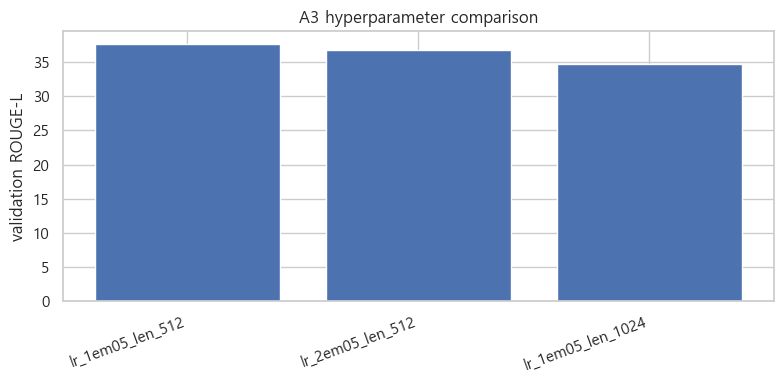

In [105]:
if RUN_TRAINING:
    final_row = length_results.iloc[0].to_dict()
    final_config = {
        "selection_dataset": "A3_train_validation_only",
        "selection_metric": "validation_rougeL_desc_then_validation_loss_asc",
        "model_id": MODEL_ID,
        "model_revision": model_revision,
        "seed": SEED,
        "learning_rate": float(final_row["learning_rate"]),
        "max_source_length": int(final_row["max_source_length"]),
        "max_target_length": MAX_TARGET_LENGTH,
        "train_batch_size": int(final_row["train_batch_size"]),
        "gradient_accumulation_steps": int(final_row["gradient_accumulation_steps"]),
        "effective_batch_size": int(final_row["effective_batch_size"]),
        "max_epochs": MAX_EPOCHS,
        "early_stopping_patience": EARLY_STOPPING_PATIENCE,
        "min_delta": MIN_DELTA,
        "selected_trial": final_row["trial"],
        "selected_best_epoch": int(final_row["best_epoch"]),
        "selected_validation_loss": float(final_row["best_validation_loss"]),
        "selected_validation_rougeL": float(final_row["rougeL"]),
        "test_used_for_selection": False,
        "generation": {"num_beams": 1, "do_sample": False},
    }
    (RESULTS / "selected_hyperparameters.json").write_text(
        json.dumps(final_config, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    display(pd.Series(final_config, name="selected_hyperparameters"))

    comparison_results = pd.concat([
        stage1_results.assign(stage="learning_rate_512"),
        pd.DataFrame([result_1024]).assign(stage="source_length_1024"),
    ], ignore_index=True)
    comparison_results.to_csv(
        RESULTS / "all_trial_results.csv", index=False, encoding="utf-8-sig"
    )

    plot_df = comparison_results.drop_duplicates("trial")
    plt.figure(figsize=(8, 4))
    plt.bar(plot_df["trial"], plot_df["rougeL"])
    plt.ylabel("validation ROUGE-L")
    plt.title("A3 hyperparameter comparison")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.savefig(RESULTS / "validation_rougeL_comparison.png", dpi=160)
    plt.show()
else:
    print("RUN_TRAINING=False: 최종 설정은 학습 후 저장됩니다.")

In [106]:
run_config = {
    "purpose": "A3 hyperparameter tuning using validation only",
    "model_id": MODEL_ID,
    "model_revision": model_revision,
    "seed": SEED,
    "learning_rates": LEARNING_RATES,
    "source_lengths": [512, 1024],
    "max_target_length": MAX_TARGET_LENGTH,
    "max_epochs": MAX_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "min_delta": MIN_DELTA,
    "test_used": False,
}
(RESULTS / "run_config.json").write_text(
    json.dumps(run_config, ensure_ascii=False, indent=2), encoding="utf-8"
)

print("저장 예정/완료 파일:")
for path in sorted(RESULTS.rglob("*")):
    if path.is_file():
        print("-", path.relative_to(PROJECT))

저장 예정/완료 파일:
- results\05-2_hyperparameter_tuning\all_trial_results.csv
- results\05-2_hyperparameter_tuning\dataset_counts.csv
- results\05-2_hyperparameter_tuning\lr_1em05_len_1024\loss_curve.png
- results\05-2_hyperparameter_tuning\lr_1em05_len_1024\loss_history.csv
- results\05-2_hyperparameter_tuning\lr_1em05_len_1024\validation_metrics.json
- results\05-2_hyperparameter_tuning\lr_1em05_len_1024\validation_predictions.csv
- results\05-2_hyperparameter_tuning\lr_1em05_len_512\loss_curve.png
- results\05-2_hyperparameter_tuning\lr_1em05_len_512\loss_history.csv
- results\05-2_hyperparameter_tuning\lr_1em05_len_512\validation_metrics.json
- results\05-2_hyperparameter_tuning\lr_1em05_len_512\validation_predictions.csv
- results\05-2_hyperparameter_tuning\lr_2em05_len_512\loss_curve.png
- results\05-2_hyperparameter_tuning\lr_2em05_len_512\loss_history.csv
- results\05-2_hyperparameter_tuning\lr_2em05_len_512\validation_metrics.json
- results\05-2_hyperparameter_tuning\lr_2em05_len_51


---

# 원본 단계: `05-3_noise_ablation.ipynb`


# 05-3. A3 기준 품질 노이즈 제거 ablation 실험

A-3을 공통 기준으로 두고, 길이·숫자 노이즈 후보를 train에서만 각각 독립적으로 제거한 A-4~A-8을 같은 KoBART 설정과 동일한 validation set으로 학습·평가한다. test는 이 노트북에서 사용하지 않는다.

- **A-4**: A-3에서 extreme_ratio 후보 제거
- **A-5**: A-3에서 summary_longer 후보 제거
- **A-6**: A-3에서 short_document 후보 제거
- **A-7**: A-3에서 short_and_summary_longer 교집합 후보만 제거
- **A-8**: A-3에서 숫자 불일치 후보 중 train 해당 행 제거

각 실험은 누적 방식이 아니라 A-3에서 독립적으로 시작한다. validation은 모든 실험에서 `processed_data/04-3_final/validation.csv`의 동일한 2,240행으로 고정한다. A3 기준 점수는 05-2의 `1e-5`, 512 결과를 재사용한다.


## 1. 설정

먼저 RUN_TRAINING=False로 데이터 구성, 제거 건수, validation 동일성, split 누수 검사를 확인한다. 이상이 없으면 True로 바꿔 실행한다. validation loss가 개선되지 않으면 early stopping하고, 최고 checkpoint에서 validation ROUGE를 계산한다.


In [107]:
import gc
import hashlib
import json
import os
import random
import re
import sys
import time
from pathlib import Path

PROJECT = PROJECT_ROOT
assert PROJECT.exists(), "프로젝트 경로를 확인하세요."
assert Path(sys.prefix).resolve() == (PROJECT / ".venv").resolve(), (
    "커널을 Python 3.11 (Team4 News GPU)로 바꾸세요."
)

os.environ["HF_HOME"] = str(PROJECT / ".cache" / "huggingface")
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "120"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

RESULTS = PROJECT / "results" / "05-3_noise_ablation"
FINAL_DIR = PROJECT / "processed_data" / "04-3_final"
REVIEW_DIR = PROJECT / "review_data" / "04-4_final_quality_review"
A3_METRICS_PATH = (
    PROJECT / "results" / "05-2_hyperparameter_tuning"
    / "lr_1em05_len_512" / "validation_metrics.json"
)
RESULTS.mkdir(parents=True, exist_ok=True)

CANDIDATE_PATHS = {
    "A4": REVIEW_DIR / "03_extreme_ratio.csv",
    "A5": REVIEW_DIR / "04_summary_longer.csv",
    "A6": REVIEW_DIR / "05_short_document.csv",
    "A7": REVIEW_DIR / "06_short_and_summary_longer.csv",
    "A8": REVIEW_DIR / "07_number_mismatch.csv",
}

SEED = 42
MODEL_ID = "gogamza/kobart-base-v2"
MAX_SOURCE_LENGTH = 512
MAX_TARGET_LENGTH = 256
EPOCHS = 5
BATCH_SIZE = 2
LEARNING_RATE = 1e-5
EARLY_STOPPING_PATIENCE = 1
EARLY_STOPPING_MIN_DELTA = 0.0
EXPERIMENTS_TO_RUN = ["A4", "A5", "A6", "A7", "A8"]
RUN_TRAINING = True  # 데이터 검증 후 학습을 시작할 때만 True
SKIP_COMPLETED = True
SAVE_MODEL = True

print("Python:", sys.version.split()[0])
print("결과 폴더:", RESULTS)


Python: 3.11.9
결과 폴더: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\05-3_noise_ablation


In [108]:
import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from huggingface_hub import HfApi
from torch import optim
from torch.nn.utils import clip_grad_norm_
from torch.utils.data import DataLoader, RandomSampler, SequentialSampler, TensorDataset
from transformers import AutoTokenizer, BartForConditionalGeneration

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert device.type == "cuda", "CUDA를 사용할 수 없습니다."
print("device:", device)
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM(GB):", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))

device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
VRAM(GB): 7.96


## 2. A-4~A-8 데이터 구성

모든 실험은 `processed_data/04-3_final`의 A3 train/validation에서 시작한다. 해당 실험의 후보 row_id는 train에서만 제거하고 validation은 완전히 고정한다. 따라서 각 실험의 차이는 train에 적용한 한 가지 추가 제거 규칙뿐이다.


In [109]:
required_paths = [
    FINAL_DIR / "train.csv",
    FINAL_DIR / "validation.csv",
    A3_METRICS_PATH,
    *CANDIDATE_PATHS.values(),
]
missing_paths = [str(path) for path in required_paths if not path.exists()]
assert not missing_paths, f"필요한 파일이 없습니다: {missing_paths}"

base_columns = ["row_id", "title", "document", "summary"]
a3 = {
    split: pd.read_csv(FINAL_DIR / f"{split}.csv")[base_columns].reset_index(drop=True)
    for split in ["train", "validation"]
}
for split, frame in a3.items():
    assert frame["row_id"].is_unique, f"A3 {split}: row_id 중복"

candidate_ids = {}
candidate_total_rows = {}
for experiment, path in CANDIDATE_PATHS.items():
    candidates = pd.read_csv(path, usecols=["row_id"])
    assert candidates["row_id"].is_unique, f"{path.name}: row_id 중복"
    candidate_ids[experiment] = set(candidates["row_id"])
    candidate_total_rows[experiment] = len(candidates)

common_validation = a3["validation"].copy()
experiment_frames = {}
removal_rows = []
for experiment, ids in candidate_ids.items():
    train = a3["train"].loc[~a3["train"]["row_id"].isin(ids)].reset_index(drop=True)
    experiment_frames[experiment] = {
        "train": train,
        "validation": common_validation.copy(),
    }
    removal_rows.append({
        "experiment": experiment,
        "candidate_file": CANDIDATE_PATHS[experiment].name,
        "candidate_rows_all_splits": candidate_total_rows[experiment],
        "removed_train_rows": len(a3["train"]) - len(train),
        "candidate_validation_rows_kept": int(common_validation["row_id"].isin(ids).sum()),
    })

experiment_labels = {
    "A4": "a3_remove_extreme_ratio",
    "A5": "a3_remove_summary_longer",
    "A6": "a3_remove_short_document",
    "A7": "a3_remove_short_and_summary_longer",
    "A8": "a3_remove_all_number_mismatch_candidates",
}

removal_counts = pd.DataFrame(removal_rows)
removal_counts.to_csv(RESULTS / "removal_counts.csv", index=False, encoding="utf-8-sig")

dataset_counts = pd.DataFrame([
    {
        "experiment": experiment,
        "description": experiment_labels[experiment],
        **{f"{split}_rows": len(frames[split]) for split in ["train", "validation"]},
    }
    for experiment, frames in experiment_frames.items()
])
dataset_counts.to_csv(RESULTS / "dataset_counts.csv", index=False, encoding="utf-8-sig")

overlap_matrix = pd.DataFrame(
    {
        right: {
            left: len(candidate_ids[left] & candidate_ids[right])
            for left in EXPERIMENTS_TO_RUN
        }
        for right in EXPERIMENTS_TO_RUN
    }
)
overlap_matrix.index.name = "experiment"
overlap_matrix.to_csv(RESULTS / "candidate_overlap_matrix.csv", encoding="utf-8-sig")

display(removal_counts)
display(dataset_counts)
display(overlap_matrix)


,experiment,candidate_file,candidate_rows_all_splits,removed_train_rows,candidate_validation_rows_kept
0,A4,03_extreme_ratio.csv,1024,756,115
1,A5,04_summary_longer.csv,610,450,71
2,A6,05_short_document.csv,486,368,51
3,A7,06_short_and_summary_longer.csv,414,314,46
4,A8,07_number_mismatch.csv,643,514,59


,experiment,description,train_rows,validation_rows
0,A4,a3_remove_extreme_ratio,18480,2240
1,A5,a3_remove_summary_longer,18786,2240
2,A6,a3_remove_short_document,18868,2240
3,A7,a3_remove_short_and_summary_longer,18922,2240
4,A8,a3_remove_all_number_mismatch_candidates,18722,2240


,A4,A5,A6,A7,A8
experiment,,,,,
A4,1024,610,470,414,50
A5,610,610,414,414,32
A6,470,414,486,414,24
A7,414,414,414,414,22
A8,50,32,24,22,643


In [110]:
space_pattern = re.compile(r"\s+")

def normalized_values(frame, column):
    return set(frame[column].astype(str).map(lambda value: space_pattern.sub(" ", value).strip()))

leakage_rows = []
common_validation_ids = common_validation["row_id"].tolist()
common_validation_digest = hashlib.sha256(
    "\n".join(common_validation_ids).encode("utf-8")
).hexdigest()

for experiment, frames in experiment_frames.items():
    assert frames["validation"]["row_id"].tolist() == common_validation_ids
    for split, frame in frames.items():
        assert frame["row_id"].is_unique, f"{experiment} {split}: row_id 중복"
        assert frame[["document", "summary"]].notna().all().all()
        assert frame["document"].astype(str).str.strip().ne("").all()
        assert frame["summary"].astype(str).str.strip().ne("").all()

    for column in ["document", "summary"]:
        train_values = normalized_values(frames["train"], column)
        validation_values = normalized_values(frames["validation"], column)
        leakage_rows.append({
            "experiment": experiment, "column": column,
            "left": "train", "right": "validation",
            "overlap": len(train_values & validation_values),
        })

leakage_check = pd.DataFrame(leakage_rows)
assert leakage_check["overlap"].sum() == 0, "split 간 document/summary 중복을 확인하세요."
leakage_check.to_csv(RESULTS / "split_leakage_check.csv", index=False, encoding="utf-8-sig")
display(leakage_check)
print("공통 validation 행 수:", len(common_validation))
print("공통 validation row_id SHA256:", common_validation_digest)
print("검증 통과: 모든 실험의 validation 동일, train-validation 중복 0, test 미사용")

,experiment,column,left,right,overlap
0,A4,document,train,validation,0
1,A4,summary,train,validation,0
2,A5,document,train,validation,0
3,A5,summary,train,validation,0
4,A6,document,train,validation,0
5,A6,summary,train,validation,0
6,A7,document,train,validation,0
7,A7,summary,train,validation,0
8,A8,document,train,validation,0
9,A8,summary,train,validation,0


공통 validation 행 수: 2240
공통 validation row_id SHA256: a8fbd4e4c551a61d4ef7ab3cfae85c701d385a3c2a8d81ea74cf3ec406af7a35
검증 통과: 모든 실험의 validation 동일, train-validation 중복 0, test 미사용


## 3. 공통 토큰화·학습·평가 함수

각 실험을 시작할 때 seed, 모델, optimizer를 새로 초기화한다. 따라서 이전 실험의 학습 상태가 다음 실험으로 전달되지 않는다.

In [111]:
model_revision = HfApi().model_info(MODEL_ID).sha
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    revision=model_revision,
    clean_up_tokenization_spaces=False,
)
rouge_metric = evaluate.load("rouge")

def reset_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

def make_dataset(frame):
    source = tokenizer(
        text=frame["document"].astype(str).tolist(),
        padding="max_length", truncation=True, max_length=MAX_SOURCE_LENGTH,
        return_token_type_ids=False, return_tensors="pt",
    )
    target = tokenizer(
        text_target=frame["summary"].astype(str).tolist(),
        padding="max_length", truncation=True, max_length=MAX_TARGET_LENGTH,
        return_token_type_ids=False, return_tensors="pt",
    )
    labels = target["input_ids"].clone()
    labels[labels == tokenizer.pad_token_id] = -100
    return TensorDataset(source["input_ids"], source["attention_mask"], labels)

def make_loader(dataset, train_mode):
    sampler = RandomSampler(dataset) if train_mode else SequentialSampler(dataset)
    return DataLoader(dataset, sampler=sampler, batch_size=BATCH_SIZE, num_workers=0, pin_memory=True)

def train_one_epoch(model, optimizer, dataloader):
    model.train()
    total_loss = 0.0
    for step, batch in enumerate(dataloader, start=1):
        input_ids, attention_mask, labels = [tensor.to(device) for tensor in batch]
        optimizer.zero_grad()
        loss = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels).loss
        loss.backward()
        clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item()
        if step % 500 == 0:
            print(f"  step {step:,}/{len(dataloader):,} | loss {total_loss / step:.4f}")
    return total_loss / len(dataloader)

def evaluate_loss(model, dataloader):
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for batch in dataloader:
            input_ids, attention_mask, labels = [tensor.to(device) for tensor in batch]
            total_loss += model(
                input_ids=input_ids, attention_mask=attention_mask, labels=labels
            ).loss.item()
    return total_loss / len(dataloader)

def generate_predictions(model, dataloader):
    model.eval()
    predictions = []
    with torch.no_grad():
        for step, batch in enumerate(dataloader, start=1):
            input_ids, attention_mask, _ = [tensor.to(device) for tensor in batch]
            generated_ids = model.generate(
                input_ids=input_ids, attention_mask=attention_mask,
                max_length=MAX_TARGET_LENGTH, num_beams=1, do_sample=False,
            )
            predictions.extend(tokenizer.batch_decode(
                generated_ids, skip_special_tokens=True, clean_up_tokenization_spaces=False
            ))
            if step % 200 == 0:
                print(f"  generation {step:,}/{len(dataloader):,}")
    return [prediction.strip() for prediction in predictions]

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


## 4. A-4~A-8 순차 학습 및 공통 validation 평가

실험별 폴더에 best checkpoint, epoch loss, validation 예측, ROUGE 결과가 즉시 저장된다. validation loss가 EARLY_STOPPING_PATIENCE회 연속 개선되지 않으면 학습을 종료한다. SKIP_COMPLETED=True이면 validation_metrics.json이 존재하는 실험은 다시 학습하지 않는다. 마지막 표에는 05-2의 A3 기준 결과가 함께 들어간다.


In [112]:
a3_saved = json.loads(A3_METRICS_PATH.read_text(encoding="utf-8"))
assert float(a3_saved["learning_rate"]) == LEARNING_RATE
assert int(a3_saved["max_source_length"]) == MAX_SOURCE_LENGTH
assert int(a3_saved["effective_batch_size"]) == BATCH_SIZE
a3_baseline_metrics = {
    "experiment": "A3",
    "description": "automatic_clean_dedup_group_split_reference",
    "train_rows": len(a3["train"]),
    "validation_rows": len(a3["validation"]),
    "removed_train_rows": 0,
    "epochs_ran": int(a3_saved["epochs_ran"]),
    "best_epoch": int(a3_saved["best_epoch"]),
    "stopped_epoch": int(a3_saved["epochs_ran"]),
    "best_validation_loss": float(a3_saved["best_validation_loss"]),
    **{name: float(a3_saved[name]) for name in ["rouge1", "rouge2", "rougeL", "rougeLsum"]},
}
result_rows = [a3_baseline_metrics]

if RUN_TRAINING:
    for experiment in EXPERIMENTS_TO_RUN:
        assert experiment in experiment_frames, f"알 수 없는 실험: {experiment}"
        experiment_dir = RESULTS / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        metrics_path = experiment_dir / "validation_metrics.json"

        if SKIP_COMPLETED and metrics_path.exists():
            saved_metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
            result_rows.append(saved_metrics)
            print(f"[{experiment}] 완료 결과가 있어 건너뜁니다.")
            continue

        print(f"\n===== {experiment}: {experiment_labels[experiment]} =====")
        reset_seed()
        frames = experiment_frames[experiment]
        train_dataset = make_dataset(frames["train"])
        validation_dataset = make_dataset(frames["validation"])
        train_loader = make_loader(train_dataset, train_mode=True)
        validation_loader = make_loader(validation_dataset, train_mode=False)
        print("train / validation:", len(train_dataset), len(validation_dataset))

        model = BartForConditionalGeneration.from_pretrained(
            MODEL_ID, revision=model_revision, use_safetensors=True
        ).to(device)
        optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, eps=1e-8)
        model_path = experiment_dir / "best_model_state.pt"
        best_validation_loss = float("inf")
        best_epoch = None
        stopped_epoch = None
        epochs_without_improvement = 0
        history = []

        for epoch in range(1, EPOCHS + 1):
            started = time.perf_counter()
            train_loss = train_one_epoch(model, optimizer, train_loader)
            validation_loss = evaluate_loss(model, validation_loader)
            elapsed_minutes = (time.perf_counter() - started) / 60
            history.append({
                "experiment": experiment,
                "epoch": epoch,
                "train_loss": train_loss,
                "validation_loss": validation_loss,
                "minutes": elapsed_minutes,
            })
            print(
                f"{experiment} epoch {epoch}/{EPOCHS} | train {train_loss:.4f} | "
                f"validation {validation_loss:.4f} | {elapsed_minutes:.1f}분"
            )

            improved = validation_loss < (best_validation_loss - EARLY_STOPPING_MIN_DELTA)
            if improved:
                best_validation_loss = validation_loss
                best_epoch = epoch
                epochs_without_improvement = 0
                torch.save(model.state_dict(), model_path)
                print("Saved:", model_path)
            else:
                epochs_without_improvement += 1
                print(
                    f"validation 미개선: {epochs_without_improvement}/"
                    f"{EARLY_STOPPING_PATIENCE}"
                )
                if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
                    stopped_epoch = epoch
                    print(f"Early stopping: epoch {epoch}")
                    break

        history_df = pd.DataFrame(history)
        history_df.to_csv(experiment_dir / "loss_history.csv", index=False, encoding="utf-8-sig")
        plt.figure(figsize=(7, 4))
        plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="train")
        plt.plot(history_df["epoch"], history_df["validation_loss"], marker="o", label="validation")
        plt.xlabel("epoch")
        plt.ylabel("loss")
        plt.title(f"{experiment} train and validation loss")
        plt.xticks(history_df["epoch"])
        plt.legend()
        plt.tight_layout()
        plt.savefig(experiment_dir / "loss_curve.png", dpi=160)
        plt.show()

        assert model_path.exists(), f"best checkpoint가 없습니다: {model_path}"
        model.load_state_dict(torch.load(model_path, map_location=device, weights_only=True))
        predictions = generate_predictions(model, validation_loader)
        references = frames["validation"]["summary"].astype(str).tolist()
        rouge_scores = rouge_metric.compute(
            predictions=predictions,
            references=references,
            tokenizer=lambda text: text.split(),
            use_stemmer=False,
        )
        metrics = {
            "experiment": experiment,
            "description": experiment_labels[experiment],
            "train_rows": len(frames["train"]),
            "validation_rows": len(frames["validation"]),
            "removed_train_rows": len(a3["train"]) - len(frames["train"]),
            "epochs_ran": len(history_df),
            "best_epoch": best_epoch,
            "stopped_epoch": stopped_epoch,
            "best_validation_loss": best_validation_loss,
            **{name: score * 100 for name, score in rouge_scores.items()},
        }
        metrics_path.write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
        prediction_df = frames["validation"].copy()
        prediction_df["prediction"] = predictions
        prediction_df.to_csv(experiment_dir / "validation_predictions.csv", index=False, encoding="utf-8-sig")
        result_rows.append(metrics)
        display(pd.Series(metrics, name=experiment))

        if not SAVE_MODEL:
            model_path.unlink(missing_ok=True)
        del model, optimizer, train_dataset, validation_dataset
        del train_loader, validation_loader
        gc.collect()
        torch.cuda.empty_cache()

    experiment_results = pd.DataFrame(result_rows).sort_values("experiment").reset_index(drop=True)
    experiment_results["validation_rank"] = experiment_results["rougeL"].rank(
        method="min", ascending=False
    ).astype(int)
    experiment_results.to_csv(RESULTS / "experiment_results.csv", index=False, encoding="utf-8-sig")
    display(experiment_results.sort_values(["validation_rank", "best_validation_loss"]))
    best_row = experiment_results.sort_values(
        ["rougeL", "best_validation_loss"], ascending=[False, True]
    ).iloc[0].to_dict()
    (RESULTS / "best_validation_experiment.json").write_text(
        json.dumps(best_row, ensure_ascii=False, indent=2), encoding="utf-8"
    )
else:
    print("RUN_TRAINING=False: 데이터 구성과 누수 검사까지만 완료했습니다.")


[A4] 완료 결과가 있어 건너뜁니다.
[A5] 완료 결과가 있어 건너뜁니다.
[A6] 완료 결과가 있어 건너뜁니다.
[A7] 완료 결과가 있어 건너뜁니다.
[A8] 완료 결과가 있어 건너뜁니다.


,experiment,description,train_rows,validation_rows,removed_train_rows,epochs_ran,best_epoch,stopped_epoch,best_validation_loss,rouge1,rouge2,rougeL,rougeLsum,validation_rank
1,A4,a3_remove_extreme_ratio,18480,2240,756,4,3,4,0.477737,45.874813,38.483782,41.967754,41.977610,1
2,A5,a3_remove_summary_longer,18786,2240,450,4,3,4,0.473132,43.168150,35.970892,39.427803,39.428312,2
0,A3,automatic_clean_dedup_group_split_reference,19236,2240,0,3,2,3,0.468172,41.472195,34.688928,37.572240,37.579459,3
4,A7,a3_remove_short_and_summary_longer,18922,2240,314,4,3,4,0.481504,39.606101,33.077492,35.917317,36.034344,4
5,A8,a3_remove_all_number_mismatch_candidates,18722,2240,514,3,2,3,0.476129,38.759065,32.333363,35.196486,35.239697,5
3,A6,a3_remove_short_document,18868,2240,368,3,2,3,0.473784,35.510930,29.431607,32.370269,32.427130,6


In [113]:
run_config = {
    "model_id": MODEL_ID,
    "model_revision": model_revision,
    "seed": SEED,
    "max_source_length": MAX_SOURCE_LENGTH,
    "max_target_length": MAX_TARGET_LENGTH,
    "max_epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "early_stopping_min_delta": EARLY_STOPPING_MIN_DELTA,
    "experiments_to_run": EXPERIMENTS_TO_RUN,
    "experiment_labels": experiment_labels,
    "candidate_paths": {key: str(path) for key, path in CANDIDATE_PATHS.items()},
    "a3_reference_metrics_path": str(A3_METRICS_PATH),
    "candidate_removal_scope": "train_only",
    "common_validation_path": str(FINAL_DIR / "validation.csv"),
    "common_validation_rows": len(common_validation),
    "common_validation_row_id_sha256": common_validation_digest,
    "test_used": False,
    "generation": {"num_beams": 1, "do_sample": False},
}
(RESULTS / "run_config.json").write_text(
    json.dumps(run_config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("저장 예정/완료 파일:")
for path in sorted(RESULTS.rglob("*")):
    if path.is_file():
        print("-", path.relative_to(PROJECT))


저장 예정/완료 파일:
- results\05-3_noise_ablation\A4\best_model_state.pt
- results\05-3_noise_ablation\A4\loss_curve.png
- results\05-3_noise_ablation\A4\loss_history.csv
- results\05-3_noise_ablation\A4\validation_metrics.json
- results\05-3_noise_ablation\A4\validation_predictions.csv
- results\05-3_noise_ablation\A5\best_model_state.pt
- results\05-3_noise_ablation\A5\loss_curve.png
- results\05-3_noise_ablation\A5\loss_history.csv
- results\05-3_noise_ablation\A5\validation_metrics.json
- results\05-3_noise_ablation\A5\validation_predictions.csv
- results\05-3_noise_ablation\A6\best_model_state.pt
- results\05-3_noise_ablation\A6\loss_curve.png
- results\05-3_noise_ablation\A6\loss_history.csv
- results\05-3_noise_ablation\A6\validation_metrics.json
- results\05-3_noise_ablation\A6\validation_predictions.csv
- results\05-3_noise_ablation\A7\best_model_state.pt
- results\05-3_noise_ablation\A7\loss_curve.png
- results\05-3_noise_ablation\A7\loss_history.csv
- results\05-3_noise_ablation\A7


---

# 원본 단계: `05-4_decoding_validation.ipynb`


## 05-4. Validation 디코딩 비교

원본 `decoding_validation.py`의 실행 코드를 내장했습니다.


In [114]:
"""05-4: fixed A4 checkpoint, validation-only decoding comparison."""
import os
from pathlib import Path

PROJECT = PROJECT_ROOT
os.environ['HF_HOME'] = str(PROJECT / '.cache' / 'huggingface')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

import hashlib
import json
import time
import numpy as np
import pandas as pd
import torch
import evaluate
from transformers import AutoTokenizer, BartForConditionalGeneration


def run():
    source = PROJECT / 'results' / '05-3_noise_ablation'
    output = PROJECT / 'results' / '05-4_decoding_validation'
    config = json.loads((source / 'run_config.json').read_text(encoding='utf-8'))
    winner = json.loads((source / 'best_validation_experiment.json').read_text(encoding='utf-8'))
    assert winner['experiment'] == 'A4'
    validation = pd.read_csv(PROJECT / 'processed_data/04-3_final/validation.csv')
    digest = hashlib.sha256('\n'.join(validation.row_id).encode()).hexdigest()
    assert digest == config['common_validation_row_id_sha256']
    saved = pd.read_csv(source / 'A4/validation_predictions.csv', keep_default_na=False)
    for column in ['row_id', 'document', 'summary']:
        assert saved[column].tolist() == validation[column].tolist(), column
    assert len(saved) == 2240
    assert torch.cuda.is_available()
    output.mkdir(parents=True, exist_ok=True)
    checkpoint = source / 'A4/best_model_state.pt'
    checkpoint_hash = hashlib.file_digest(checkpoint.open('rb'), 'sha256').hexdigest()
    settings = dict(model_id=config['model_id'], model_revision=config['model_revision'],
                    checkpoint_sha256=checkpoint_hash, validation_sha256=digest,
                    max_source_length=512, max_length=256, batch_size=2,
                    strategies=[1, 3, 5], do_sample=False, test_used=False)
    settings_path = output / 'run_config.json'
    if settings_path.exists():
        assert json.loads(settings_path.read_text()) == settings, 'Existing settings differ'
    else:
        settings_path.write_text(json.dumps(settings, indent=2), encoding='utf-8')
    tokenizer = AutoTokenizer.from_pretrained(config['model_id'], revision=config['model_revision'],
                                            local_files_only=True, clean_up_tokenization_spaces=False)
    model = BartForConditionalGeneration.from_pretrained(config['model_id'],
                revision=config['model_revision'], local_files_only=True, use_safetensors=True)
    model.load_state_dict(torch.load(checkpoint, map_location='cpu', weights_only=True))
    model.to('cuda').eval()
    metric = evaluate.load('rouge')
    rows = []
    for beams in [1, 3, 5]:
        name = 'greedy' if beams == 1 else f'beam_{beams}'
        partial = output / f'{name}_partial.json'
        predictions = saved.prediction.tolist() if beams == 1 else []
        if beams != 1 and partial.exists():
            predictions = json.loads(partial.read_text(encoding='utf-8'))
        assert len(predictions) <= len(validation)
        started = time.perf_counter()
        for start in range(len(predictions), len(validation), 2):
            batch = tokenizer(validation.document.iloc[start:start+2].tolist(),
                    padding='max_length', truncation=True, max_length=512,
                    return_token_type_ids=False, return_tensors='pt').to('cuda')
            with torch.inference_mode():
                generated = model.generate(**batch, max_length=256, num_beams=beams, do_sample=False)
            predictions.extend(x.strip() for x in tokenizer.batch_decode(generated,
                skip_special_tokens=True, clean_up_tokenization_spaces=False))
            if len(predictions) % 100 == 0 or len(predictions) == len(validation):
                temporary = partial.with_suffix('.tmp')
                temporary.write_text(json.dumps(predictions, ensure_ascii=False), encoding='utf-8')
                temporary.replace(partial)
                print(name, len(predictions), '/', len(validation), flush=True)
        np.random.seed(42)
        scores = metric.compute(predictions=predictions, references=validation.summary.tolist(),
                                tokenizer=lambda text: text.split(), use_stemmer=False)
        row = {'strategy': name, 'num_beams': beams, 'validation_rows': len(validation),
               'seconds_this_run': time.perf_counter()-started,
               **{key: value*100 for key, value in scores.items()}}
        frame = validation[['row_id', 'title', 'document', 'summary']].copy()
        frame['prediction'] = predictions
        frame.to_csv(output / f'{name}_validation_predictions.csv', index=False, encoding='utf-8-sig')
        (output / f'{name}_metrics.json').write_text(json.dumps(row, indent=2), encoding='utf-8')
        rows.append(row)
        print(row, flush=True)
    results = pd.DataFrame(rows).sort_values(['rougeL', 'num_beams'], ascending=[False, True])
    results.to_csv(output / 'decoding_results.csv', index=False, encoding='utf-8-sig')
    selected = {
        key: value.item() if hasattr(value, 'item') else value
        for key, value in results.iloc[0].items()
    }
    selected.update(experiment='A4', checkpoint=str(checkpoint), test_used=False)
    (output / 'selected_decoding.json').write_text(json.dumps(selected, indent=2), encoding='utf-8')
    print('Completed validation decoding comparison', flush=True)


if __name__ == '__main__':
    run()


You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


{'strategy': 'greedy', 'num_beams': 1, 'validation_rows': 2240, 'seconds_this_run': 2.34747520000019, 'rouge1': 45.87329637453921, 'rouge2': 38.50758634867972, 'rougeL': 42.005173933776135, 'rougeLsum': 42.00941629940686}
{'strategy': 'beam_3', 'num_beams': 3, 'validation_rows': 2240, 'seconds_this_run': 2.3597561000005953, 'rouge1': 48.28682598149403, 'rouge2': 40.805114868771795, 'rougeL': 44.15913331376537, 'rougeLsum': 44.15005164895947}
{'strategy': 'beam_5', 'num_beams': 5, 'validation_rows': 2240, 'seconds_this_run': 2.406602400000338, 'rouge1': 49.00700575586151, 'rouge2': 41.49762903675099, 'rougeL': 44.9422409568983, 'rougeLsum': 44.93542751638898}
Completed validation decoding comparison


## 05-5. 최종 test 1회 평가

원본 `final_test_evaluation.py`의 실행 코드를 내장했습니다.


In [115]:
"""05-5: one final test evaluation after data and decoding are fixed."""
import hashlib
import json
import os
import time
from pathlib import Path

PROJECT = PROJECT_ROOT
os.environ['HF_HOME'] = str(PROJECT / '.cache' / 'huggingface')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

import evaluate
import pandas as pd
import torch
from transformers import AutoTokenizer, BartForConditionalGeneration


def json_ready(values):
    return {key: value.item() if hasattr(value, 'item') else value for key, value in values.items()}


def run():
    decoding_dir = PROJECT / 'results/05-4_decoding_validation'
    output = PROJECT / 'results/05-5_final_test_evaluation'
    selected = json.loads((decoding_dir / 'selected_decoding.json').read_text(encoding='utf-8'))
    assert selected['experiment'] == 'A4'
    assert selected['strategy'] == 'beam_5'
    assert selected['test_used'] is False
    checkpoint = Path(selected['checkpoint'])
    test = pd.read_csv(PROJECT / 'processed_data/04-3_final/test.csv', keep_default_na=False)
    assert len(test) == 2564 and test.row_id.is_unique
    test_hash = hashlib.sha256('\n'.join(test.row_id).encode()).hexdigest()
    output.mkdir(parents=True, exist_ok=True)
    config = {
        'experiment': 'A4', 'checkpoint': str(checkpoint),
        'checkpoint_sha256': hashlib.file_digest(checkpoint.open('rb'), 'sha256').hexdigest(),
        'decoding_strategy': 'beam_5', 'num_beams': 5,
        'test_rows': len(test), 'test_row_id_sha256': test_hash,
        'model_id': 'gogamza/kobart-base-v2', 'max_source_length': 512,
        'max_target_length': 256, 'batch_size': 2,
        'bertscore_model': 'xlm-roberta-base', 'bertscore_rescale_with_baseline': False,
        'test_used_before_this_run': False,
    }
    config_path = output / 'run_config.json'
    if config_path.exists():
        assert json.loads(config_path.read_text(encoding='utf-8')) == config
    else:
        config_path.write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')
    partial_path = output / 'test_predictions_partial.json'
    predictions = json.loads(partial_path.read_text(encoding='utf-8')) if partial_path.exists() else []
    assert len(predictions) <= len(test)
    assert torch.cuda.is_available()
    tokenizer = AutoTokenizer.from_pretrained(config['model_id'], local_files_only=True,
                                              clean_up_tokenization_spaces=False)
    model = BartForConditionalGeneration.from_pretrained(config['model_id'], local_files_only=True,
                                                          use_safetensors=True)
    model.load_state_dict(torch.load(checkpoint, map_location='cpu', weights_only=True))
    model.to('cuda').eval()
    started = time.perf_counter()
    for start in range(len(predictions), len(test), config['batch_size']):
        batch = tokenizer(test.document.iloc[start:start+config['batch_size']].tolist(),
                          padding='max_length', truncation=True,
                          max_length=config['max_source_length'], return_token_type_ids=False,
                          return_tensors='pt').to('cuda')
        with torch.inference_mode():
            generated = model.generate(**batch, max_length=config['max_target_length'],
                                       num_beams=config['num_beams'], do_sample=False)
        predictions.extend(text.strip() for text in tokenizer.batch_decode(
            generated, skip_special_tokens=True, clean_up_tokenization_spaces=False
        ))
        if len(predictions) % 100 == 0 or len(predictions) == len(test):
            temp = partial_path.with_suffix('.tmp')
            temp.write_text(json.dumps(predictions, ensure_ascii=False), encoding='utf-8')
            temp.replace(partial_path)
            print(f'generation {len(predictions)}/{len(test)}', flush=True)
    prediction_path = output / 'test_predictions.csv'
    if not prediction_path.exists():
        prediction_frame = test[['row_id', 'title', 'document', 'summary']].copy()
        prediction_frame['prediction'] = predictions
        prediction_frame.to_csv(prediction_path, index=False, encoding='utf-8-sig')
    rouge = evaluate.load('rouge').compute(predictions=predictions, references=test.summary.tolist(),
                                           tokenizer=lambda text: text.split(), use_stemmer=False)
    rouge_scores = {key: value * 100 for key, value in rouge.items()}
    print({'rouge': rouge_scores}, flush=True)
    bertscore = evaluate.load('bertscore').compute(
        predictions=predictions, references=test.summary.tolist(), lang='ko',
        model_type=config['bertscore_model'], device='cuda', batch_size=16,
        rescale_with_baseline=config['bertscore_rescale_with_baseline'],
    )
    bert_scores = {
        'bertscore_precision': sum(bertscore['precision']) / len(predictions) * 100,
        'bertscore_recall': sum(bertscore['recall']) / len(predictions) * 100,
        'bertscore_f1': sum(bertscore['f1']) / len(predictions) * 100,
    }
    metrics = json_ready({
        'experiment': 'A4', 'decoding_strategy': 'beam_5', 'num_beams': 5,
        'test_rows': len(test), 'generation_seconds': time.perf_counter() - started,
        **rouge_scores, **bert_scores,
    })
    (output / 'test_metrics.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')
    pd.DataFrame([metrics]).to_csv(output / 'test_metrics.csv', index=False, encoding='utf-8-sig')
    print(metrics, flush=True)


if __name__ == '__main__':
    run()


You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


{'rouge': {'rouge1': 49.437224384822706, 'rouge2': 41.91670323522841, 'rougeL': 45.6556372058231, 'rougeLsum': 45.6758112583049}}


c:\Users\KDS-30\Desktop\Projects\06_Team_Project4\.venv\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


{'experiment': 'A4', 'decoding_strategy': 'beam_5', 'num_beams': 5, 'test_rows': 2564, 'generation_seconds': 65.86212390000037, 'rouge1': 49.437224384822706, 'rouge2': 41.91670323522841, 'rougeL': 45.6556372058231, 'rougeLsum': 45.6758112583049, 'bertscore_precision': 90.89477488570577, 'bertscore_recall': 92.78156321943271, 'bertscore_f1': 91.77552111993155}


## 05-6. 최종 test 오류 분석

원본 `error_analysis.py`의 실행 코드를 내장했습니다.


In [116]:
"""05-6: final test error analysis and four figures."""
from pathlib import Path
import json
import random

import matplotlib.pyplot as plt
import pandas as pd
from rouge_score.rouge_scorer import RougeScorer

PROJECT = PROJECT_ROOT
INPUT = PROJECT / 'results/05-5_final_test_evaluation'
OUTPUT = PROJECT / 'results/05-6_error_analysis'


def words(text):
    return len(str(text).split())


class WhitespaceTokenizer:
    def tokenize(self, text):
        return str(text).split()


def run():
    OUTPUT.mkdir(parents=True, exist_ok=True)
    test_metrics = json.loads((INPUT / 'test_metrics.json').read_text(encoding='utf-8'))
    frame = pd.read_csv(INPUT / 'test_predictions.csv', keep_default_na=False)
    metadata = pd.read_csv(PROJECT / 'processed_data/04-3_final/test.csv', usecols=['row_id', 'category'])
    frame = frame.merge(metadata, on='row_id', how='left', validate='one_to_one')
    assert len(frame) == 2564 and frame.row_id.is_unique
    assert {'summary', 'prediction', 'category'}.issubset(frame.columns)
    assert frame.category.notna().all()
    scorer = RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=False,
                         tokenizer=WhitespaceTokenizer())
    row_scores = []
    for reference, prediction in zip(frame.summary, frame.prediction):
        score = scorer.score(reference, prediction)
        row_scores.append({name: score[name].fmeasure * 100 for name in score})
    scores = pd.DataFrame(row_scores)
    result = pd.concat([frame, scores], axis=1)
    result['reference_words'] = result.summary.map(words)
    result['prediction_words'] = result.prediction.map(words)
    result['prediction_reference_ratio'] = result.prediction_words / result.reference_words.clip(lower=1)
    result['length_bin'] = pd.cut(
        result.document.map(words), bins=[0, 100, 250, 500, 1000, float('inf')],
        labels=['≤100', '101–250', '251–500', '501–1000', '>1000'], include_lowest=True,
    )
    result.to_csv(OUTPUT / 'test_row_scores.csv', index=False, encoding='utf-8-sig')
    category = result.groupby('category', observed=True).agg(
        rows=('row_id', 'size'), rouge1=('rouge1', 'mean'), rouge2=('rouge2', 'mean'),
        rougeL=('rougeL', 'mean'), reference_words=('reference_words', 'mean'),
        prediction_words=('prediction_words', 'mean'),
    ).reset_index()
    category.to_csv(OUTPUT / 'category_metrics.csv', index=False, encoding='utf-8-sig')
    lengths = result.groupby('length_bin', observed=True).agg(
        rows=('row_id', 'size'), rougeL=('rougeL', 'mean'),
        reference_words=('reference_words', 'mean'), prediction_words=('prediction_words', 'mean'),
    ).reset_index()
    lengths.to_csv(OUTPUT / 'length_bin_metrics.csv', index=False, encoding='utf-8-sig')
    low = result.nsmallest(50, 'rougeL')
    low.to_csv(OUTPUT / 'low_rougeL_50.csv', index=False, encoding='utf-8-sig')
    result.sample(50, random_state=42).to_csv(OUTPUT / 'random_50.csv', index=False, encoding='utf-8-sig')
    summary = {
        'test_metrics': test_metrics,
        'rows': len(result), 'low_rougeL_threshold_50th': float(low.rougeL.max()),
        'mean_row_rougeL': float(result.rougeL.mean()),
        'median_row_rougeL': float(result.rougeL.median()),
        'analysis_rule': 'per-row ROUGE uses whitespace-tokenized F1; corpus ROUGE remains the official final metric',
    }
    (OUTPUT / 'analysis_summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
    plt.rcParams['font.family'] = 'Malgun Gothic'
    plt.rcParams['axes.unicode_minus'] = False
    figure_dir = OUTPUT / 'figures'
    figure_dir.mkdir(exist_ok=True)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(result.rougeL, bins=30, color='#3b73af', edgecolor='white')
    ax.axvline(result.rougeL.mean(), color='#d95f02', linestyle='--', label=f'평균 {result.rougeL.mean():.1f}')
    ax.set(xlabel='기사별 ROUGE-L F1', ylabel='기사 수', title='Test 기사별 ROUGE-L 분포')
    ax.legend(); fig.tight_layout(); fig.savefig(figure_dir / '01_rougeL_distribution.png', dpi=160); plt.close(fig)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(category.category, category.rougeL, color=['#3b73af', '#77aadd'][:len(category)])
    ax.set_ylim(0, max(category.rougeL.max() + 5, 50))
    ax.set(xlabel='카테고리', ylabel='평균 ROUGE-L F1', title='카테고리별 요약 성능')
    for index, value in enumerate(category.rougeL): ax.text(index, value + .4, f'{value:.1f}', ha='center')
    fig.tight_layout(); fig.savefig(figure_dir / '02_category_rougeL.png', dpi=160); plt.close(fig)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(lengths.length_bin.astype(str), lengths.rougeL, color='#4daf4a')
    ax.set(xlabel='본문 길이(어절)', ylabel='평균 ROUGE-L F1', title='본문 길이 구간별 요약 성능')
    ax.tick_params(axis='x', rotation=20)
    fig.tight_layout(); fig.savefig(figure_dir / '03_length_bin_rougeL.png', dpi=160); plt.close(fig)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.scatter(result.reference_words, result.prediction_words, s=8, alpha=.25, color='#984ea3')
    upper = max(result.reference_words.max(), result.prediction_words.max())
    ax.plot([0, upper], [0, upper], color='#d95f02', linestyle='--', label='동일 길이')
    ax.set(xlabel='정답 요약 길이(어절)', ylabel='생성 요약 길이(어절)', title='생성 요약과 정답 요약의 길이 비교')
    ax.legend(); fig.tight_layout(); fig.savefig(figure_dir / '04_prediction_reference_length.png', dpi=160); plt.close(fig)
    print(json.dumps(summary, ensure_ascii=False, indent=2))


if __name__ == '__main__':
    run()


{
  "test_metrics": {
    "experiment": "A4",
    "decoding_strategy": "beam_5",
    "num_beams": 5,
    "test_rows": 2564,
    "generation_seconds": 65.86212390000037,
    "rouge1": 49.437224384822706,
    "rouge2": 41.91670323522841,
    "rougeL": 45.6556372058231,
    "rougeLsum": 45.6758112583049,
    "bertscore_precision": 90.89477488570577,
    "bertscore_recall": 92.78156321943271,
    "bertscore_f1": 91.77552111993155
  },
  "rows": 2564,
  "low_rougeL_threshold_50th": 4.878048780487805,
  "mean_row_rougeL": 45.63496310902099,
  "median_row_rougeL": 44.651525658807216,
  "analysis_rule": "per-row ROUGE uses whitespace-tokenized F1; corpus ROUGE remains the official final metric"
}



---

# 원본 단계: `06_project_summary.ipynb`


# 뉴스 기사 요약 프로젝트 통합 정리

환경 점검부터 최종 평가까지의 핵심 코드·저장 결과·해석을 한 파일로 정리했다. 작성 기준: 2026-09-21.

**실행하지 않은 설명용 통합본**이다. 실행 번호와 출력은 비워 두었고, 아래 결과표는 기존 산출물에서 읽어 Markdown으로 넣었다. 코드 예제는 `RUN_EXAMPLES=False`로 차단되어 있다. 원본 실험이나 결과 파일을 덮어쓰지 않는다.

흐름: 00 환경 → 01 EDA → 02 토큰화·임베딩 → 03 베이스라인 → 04 정제·그룹 분할 → 05-1 A0~A3 → 05-2 설정 비교 → 05-3 A4~A8 → 05-4 디코딩 → 05-5 test → 05-6 기초 오류 분석.

In [117]:
from pathlib import Path
import json, re, random
from collections import Counter
import pandas as pd
from IPython.display import display, Image
PROJECT = PROJECT_ROOT
RUN_EXAMPLES = False  # 핵심 코드 열람용; 전체 재현은 원본 노트북 사용
SEED = 42
random.seed(SEED)
def saved_json(relative_path):
    return json.loads((PROJECT / relative_path).read_text(encoding='utf-8-sig'))


## 00. 환경과 입력·정답
데이터는 총 27,400건(train 22,194 / validation 2,466 / test 2,740). 2022년 7월 1~10일 경제·IT과학 기사다. 모델 입력은 document, 학습 정답은 summary이며 제목·언론사·날짜·링크는 입력하지 않는다. 사전학습 자체는 외부에서 완료된 모델을 사용했고, 이 프로젝트에서는 파인튜닝을 수행했다.

In [118]:
display(saved_json('results/00_environment_data_kobart/report.json')['environment'])


{'python': '3.11.9',
 'torch': '2.7.1+cu128',
 'cuda': '12.8',
 'gpu': 'NVIDIA GeForce RTX 5060 Laptop GPU',
 'vram_gib': 7.96,
 'cuda_matmul_passed': True,
 'packages': {'transformers': '4.44.2',
  'datasets': '2.21.0',
  'tokenizers': '0.19.1',
  'huggingface-hub': '0.24.7'}}

## 01. EDA: 문제 발견
길이·분야 분포, 결측·중복, 반복 요약, 숫자 불일치, 본문 대비 요약 길이를 검사했다. 자동 플래그는 오류 확정이 아닌 검토 후보다. 짧은 사진기사와 긴 방송 대본은 길이 분포에 영향을 준다.

In [119]:
def noise_features(document, summary):
    d, s = str(document), str(summary)
    tokens = re.findall(r'[가-힣A-Za-z0-9]+(?:[.,]\d+)?', s.lower())
    counts = Counter(tuple(tokens[i:i+4]) for i in range(len(tokens)-3))
    overlap = sum(w in set(d.split()) for w in s.split()) / max(len(s.split()), 1)
    ratio = len(s) / max(len(d), 1)
    return dict(repeat_4gram=max(counts.values(), default=0)>=3,
                low_overlap=overlap<0.3, extreme_ratio=ratio<0.02 or ratio>0.8,
                summary_longer=len(s)>len(d), short_document=len(d.split())<30)


### 원본 노이즈 후보
저장된 결과: `review_data/04-1_raw_candidates/00_export_summary.csv`

| file | rows |
| --- | --- |
| 01_repeat_4gram.csv | 1376 |
| 02_low_overlap.csv | 6 |
| 03_extreme_ratio.csv | 2823 |
| 04_summary_longer.csv | 2132 |
| 05_number_mismatch.csv | 777 |
| 06_short_document.csv | 1514 |
| 07_url.csv | 83 |
| 08_boilerplate.csv | 53 |
| 09_replacement_char.csv | 4 |
| 10_exact_document_summary_duplicate.csv | 3785 |
| 11_shared_summary_different_document.csv | 100 |

In [120]:
display(pd.read_csv(PROJECT / 'review_data/04-1_raw_candidates/00_export_summary.csv'))


,file,rows
0,01_repeat_4gram.csv,1376
1,02_low_overlap.csv,6
2,03_extreme_ratio.csv,2823
3,04_summary_longer.csv,2132
4,05_number_mismatch.csv,777
5,06_short_document.csv,1514
6,07_url.csv,83
7,08_boilerplate.csv,53
8,09_replacement_char.csv,4
9,10_exact_document_summary_duplicate.csv,3785


## 02. 토큰화·임베딩 및 모델 선택
KoBART의 encoder-decoder 구조는 본문을 조건으로 요약을 생성하기에 적합하다. KoGPT2의 decoder-only 구조와는 이론·토큰화만 비교했으며, 동일 조건 파인튜닝 대결은 아직 하지 않았다. BPE가 보편적으로 WordPiece보다 우월하다는 결론이 아니라, 선택한 KoBART 가중치와 기존 토크나이저의 호환성을 유지했다.

### 같은 문장 토큰화 비교
출처: `02_tokenize_embedding.ipynb`. 아래 코드는 기존 구현의 핵심 발췌이며 재실행용 전체 파이프라인은 원본 노트북을 사용한다. 기본값에서는 실행하지 않는다.

In [121]:
if RUN_EXAMPLES:
    from transformers import AutoTokenizer
    specs = {'KoBART': 'gogamza/kobart-base-v2', 'KoGPT2': 'skt/kogpt2-base-v2',
             'KoELECTRA': 'monologg/koelectra-base-v3-discriminator'}
    text = '정부가 수출 중소기업의 물류난 해소를 위해 무역금융 규모를 40조 원 이상 확대한다'
    for name, model_id in specs.items():
        tok = AutoTokenizer.from_pretrained(model_id)
        print(name, tok.tokenize(text))


### 토큰 길이 비교
저장된 결과: `results/02_tokenize_embedding/token_length_comparison.csv`

| tokenizer | mean | over_512_pct | over_1024_pct |
| --- | --- | --- | --- |
| KoBART_BPE | 418.1155 | 27.5210 | 4.1363 |
| KoGPT2_BPE | 422.6594 | 28.0752 | 4.2489 |
| KoELECTRA_WordPiece | 501.9608 | 37.8345 | 7.6237 |

In [122]:
display(pd.read_csv(PROJECT / 'results/02_tokenize_embedding/token_length_comparison.csv'))


,tokenizer,rows,mean,median,p95,p99,max,over_512_count,over_512_pct,over_1024_count,over_1024_pct
0,KoBART_BPE,22194,418.115527,357.0,970.00,1548.28,6781,6108,27.520952,918,4.136253
1,KoGPT2_BPE,22194,422.659367,361.0,977.00,1564.07,6993,6231,28.075155,943,4.248896
2,KoELECTRA_WordPiece,22194,501.960800,428.0,1163.35,1875.07,8431,8397,37.834550,1692,7.623682


예시 문장의 특수 토큰 제외 토큰 수는 KoBART 17, KoGPT2 19, KoELECTRA 20이다. KoELECTRA의 22는 특수 토큰을 포함한 수다. 서로 다른 집계 기준을 혼동하지 않는다.

### Word2Vec의 고정 임베딩
출처: `02_tokenize_embedding.ipynb`. 아래 코드는 기존 구현의 핵심 발췌이며 재실행용 전체 파이프라인은 원본 노트북을 사용한다. 기본값에서는 실행하지 않는다.

In [123]:
if RUN_EXAMPLES:
    from gensim.models import Word2Vec
    from konlpy.tag import Okt
    okt = Okt()
    # train_df는 원본 train 22,194건을 불러온 DataFrame
    corpus = [okt.morphs(x, stem=True) for x in train_df.document.astype(str)]
    w2v = Word2Vec(corpus, vector_size=100, window=5, min_count=5,
                   workers=1, sg=1, seed=42, epochs=5)
    print(w2v.wv.most_similar('수출', topn=10))


### 문맥 벡터와 shape 흐름
출처: `02_tokenize_embedding.ipynb, sample inputs / kobart_model은 앞 단계에서 준비`. 아래 코드는 기존 구현의 핵심 발췌이며 재실행용 전체 파이프라인은 원본 노트북을 사용한다. 기본값에서는 실행하지 않는다.

In [124]:
if RUN_EXAMPLES:
    sample_text = train_df.loc[0, "document"]
    sample_inputs = kobart_tokenizer(
        sample_text,
        return_tensors="pt",
        max_length=512,
        truncation=True,
        return_token_type_ids=False,
    )
    sample_inputs = {key: value.to(device) for key, value in sample_inputs.items()}

    decoder_start_token_id = kobart_model.config.decoder_start_token_id
    if decoder_start_token_id is None:
        decoder_start_token_id = (
            kobart_tokenizer.bos_token_id
            if kobart_tokenizer.bos_token_id is not None
            else kobart_tokenizer.eos_token_id
        )
    decoder_input_ids = torch.tensor([[decoder_start_token_id]], device=device)

    with torch.no_grad():
        input_embeddings = kobart_model.model.shared(sample_inputs["input_ids"])
        encoder_output = kobart_model.model.encoder(**sample_inputs).last_hidden_state
        model_output = kobart_model(
            **sample_inputs,
            decoder_input_ids=decoder_input_ids,
        )

    shape_log = {
        "input_ids": list(sample_inputs["input_ids"].shape),
        "attention_mask": list(sample_inputs["attention_mask"].shape),
        "token_embedding": list(input_embeddings.shape),
        "encoder_last_hidden_state": list(encoder_output.shape),
        "decoder_input_ids": list(decoder_input_ids.shape),
        "decoder_logits": list(model_output.logits.shape),
        "hidden_size": kobart_model.config.d_model,
        "vocab_size": kobart_model.config.vocab_size,
    }


In [125]:
display(saved_json('results/02_tokenize_embedding/kobart_shape_log.json'))
display(pd.read_csv(PROJECT/'results/02_tokenize_embedding/embedding_context_comparison.csv'))


{'input_ids': [1, 315],
 'attention_mask': [1, 315],
 'token_embedding': [1, 315, 768],
 'encoder_last_hidden_state': [1, 315, 768],
 'decoder_input_ids': [1, 1],
 'decoder_logits': [1, 1, 30000],
 'hidden_size': 768,
 'vocab_size': 30000}

,representation,cosine_similarity,interpretation
0,input_embedding,1.000000,토큰 자체의 기본 벡터
1,encoder_contextual_output,0.355976,문장 전체 문맥이 반영된 벡터


동일한 ‘수출’ 토큰의 입력 벡터 코사인 유사도는 약 1.000, 문맥을 반영한 encoder 벡터는 약 0.356이었다. 이는 문맥 표현이 달라짐을 보여주며 성능 우열 점수는 아니다.

## 03. 베이스라인
03-1: KoBART base를 파인튜닝 없이 적용. 03-2: raw에 가까운 데이터로 파인튜닝. 03-3: 앞 50/80어절을 사용하는 Lead. 세 방식은 원래 test 2,740건을 사용했다. 이후 정제 test 2,564건의 점수와 직접 같은 조건으로 비교하지 않는다.

In [126]:
def lead_summary(document, n=50):
    return ' '.join(str(document).split()[:n])
display(saved_json('results/03-1_baseline_no_summary/zero_shot_metrics.json'))
display(saved_json('results/03-2_baseline_raw_data/test_metrics.json'))
display(pd.read_csv(PROJECT/'results/03-3_baseline_lead/lead_metrics.csv'))


{'rouge1': 19.759299832111775,
 'rouge2': 15.104643863734124,
 'rougeL': 17.118358790456366,
 'rougeLsum': 17.107262087846742,
 'evaluated_rows': 2740,
 'generation_seconds': 490.9139624000002,
 'peak_memory_mib': 1095.94677734375}

{'test_loss': 0.512187167534428,
 'rouge1': 34.60987672752075,
 'rouge2': 28.942333974831136,
 'rougeL': 31.75530298731547,
 'rougeLsum': 31.72680904573464}

,strategy,word_limit,rouge1,rouge2,rougeL,rougeLsum,average_prediction_words,average_reference_words,short_document_count,evaluated_rows
0,lead_50,50,46.008549,37.632471,39.256422,39.270158,48.028102,42.149635,261,2740
1,lead_80,80,46.441708,39.219675,39.718763,39.709966,74.008759,42.149635,453,2740


ROUGE-L: zero-shot 17.12 / raw 파인튜닝 32.18 / Lead-50 39.26 / Lead-80 39.72. Lead가 강한 이유로 정답의 추출적 성격과 기사 앞부분 편향이 관찰됐다. raw 학습은 epoch 2 이후 validation loss가 상승했다.

## 04. 공통 전처리와 누수 방지
04-1 후보 분류 → 04-2 반복 행 제외·본문 정리 → 04-3 완전 중복 제거·동일 document/summary 그룹 → 04-4 남은 후보 재분류. 반복 구절 축약을 검토했으나 완전한 복원 보장이 어려워 행 제외를 채택했다. 기자·언론사 이름은 유지한다. 숫자 수동 검토는 탐색했지만 현재 A 계열 학습에는 채택하지 않았다.

### 실제 문자열 정리 규칙
출처: `04-2_clean_dataset.ipynb`. 아래 코드는 기존 구현의 핵심 발췌이며 재실행용 전체 파이프라인은 원본 노트북을 사용한다. 기본값에서는 실행하지 않는다.

In [127]:
if RUN_EXAMPLES:
    word_pattern=re.compile(r"[가-힣A-Za-z0-9]+(?:[.,]\d+)?")
    def max_4gram(text):
        tokens=word_pattern.findall(str(text).lower())
        counts=Counter(tuple(tokens[i:i+4]) for i in range(len(tokens)-3))
        return max(counts.values(),default=0)
    URL=re.compile(r"(?i)\b(?:https?://|www\.)[^\s<>()\[\]{}]+")
    BOILERPLATES=[
     re.compile(r"국내에서만\s*사용가능\.?\s*재배포\s*금지\.?\s*DB\s*금지\.?\s*For\s*Use\s*Only\s*in\s*the\s*Republic\s*of\s*Korea\.?\s*(?:No\s*)?Redistribution\s*Prohibited",re.I),
     re.compile(r"무단\s*(?:전재|복제|배포)\s*(?:및\s*)?재배포\s*금지\.?",re.I),
     re.compile(r"재배포\s*금지\.?",re.I),
     re.compile(r"인터뷰\s*자료의\s*저작권은\s*[^.]{0,120}(?:있습니다|있다)\.?",re.I),
     re.compile(r"(?:전문\s*게재나?\s*)?인터뷰\s*인용\s*보도\s*시\s*[^.]{0,180}(?:바랍니다|바란다)\.?",re.I),
     re.compile(r"인용\s*보도\s*시\s*출처를\s*[^.]{0,120}(?:바랍니다|바란다)\.?",re.I),
     re.compile(r"아래\s*텍스트는\s*실제\s*방송\s*내용과\s*차이가\s*있을\s*수\s*있으니\s*[^.]{0,180}(?:바랍니다|바란다)\.?",re.I)]
    def clean_document(text):
        original=str(text); cleaned,url_n=URL.subn("",original); boiler_n=0
        for pattern in BOILERPLATES:
            cleaned,n=pattern.subn("",cleaned); boiler_n+=n
        replacement_n=cleaned.count("�"); cleaned=cleaned.replace("�"," ")
        cleaned=re.sub(r"[ \t]+"," ",cleaned); cleaned=re.sub(r" *\n *","\n",cleaned).strip()
        return cleaned,url_n,boiler_n,replacement_n


### 반복 제거와 본문 정리
저장된 결과: `review_data/04-2_cleaning/cleaning_summary.csv`

| split | original_rows | repeat_excluded | clean_rows | documents_changed |
| --- | --- | --- | --- | --- |
| train | 22194 | 1121 | 21073 | 104 |
| validation | 2466 | 121 | 2345 | 9 |
| test | 2740 | 134 | 2606 | 16 |

In [128]:
display(pd.read_csv(PROJECT / 'review_data/04-2_cleaning/cleaning_summary.csv'))


,split,original_rows,repeat_excluded,clean_rows,documents_changed,urls_removed,boilerplates_removed,replacement_chars_removed
0,train,22194,1121,21073,104,73,52,7
1,validation,2466,121,2345,9,7,8,0
2,test,2740,134,2606,16,20,2,0


### 완전 중복 제거와 연결 그룹
출처: `04-3_dedup_group_split.ipynb; INPUT은 04-2_cleaned 폴더`. 아래 코드는 기존 구현의 핵심 발췌이며 재실행용 전체 파이프라인은 원본 노트북을 사용한다. 기본값에서는 실행하지 않는다.

In [129]:
if RUN_EXAMPLES:
    splits=["train","validation","test"]
    df=pd.concat([pd.read_csv(INPUT/f"{s}.csv") for s in splits],ignore_index=True)
    assert df.row_id.is_unique
    priority={"test":0,"validation":1,"train":2}
    ordered=df.assign(_priority=df.split.map(priority),_position=np.arange(len(df))).sort_values(["_priority","source_index","_position"])
    ordered["keep_exact"]=~ordered.duplicated(["document","summary"],keep="first")
    df=df.merge(ordered[["row_id","keep_exact"]],on="row_id",validate="one_to_one")
    exact_excluded=df[~df.keep_exact].copy(); work=df[df.keep_exact].copy().reset_index(drop=True)

    # 같은 document 또는 같은 summary를 공유하면 같은 연결 요소로 묶습니다.
    parent=list(range(len(work)))
    def find(x):
        while parent[x]!=x:
            parent[x]=parent[parent[x]]; x=parent[x]
        return x
    def union(a,b):
        ra,rb=find(a),find(b)
        if ra!=rb: parent[rb]=ra
    for column in ["document","summary"]:
        for indices in work.groupby(column,sort=False).indices.values():
            indices=list(indices)
            for index in indices[1:]: union(indices[0],index)
    work["group_id"]=[find(i) for i in range(len(work))]
    group_splits=work.groupby("group_id").split.agg(set)
    def destination(values):
        if "test" in values: return "test"
        if "validation" in values: return "validation"
        return "train"
    destinations=group_splits.map(destination)
    work["assigned_split"]=work.group_id.map(destinations)
    work["keep_group"]=~((work.assigned_split=="test")&(work.split!="test"))
    work["split_action"]="kept"
    work.loc[~work.keep_group,"split_action"]="excluded_test_overlap"
    moved=work.keep_group & work.split.ne(work.assigned_split)
    work.loc[moved,"split_action"]="moved_to_"+work.loc[moved,"assigned_split"]


### 그룹 처리 후 데이터
저장된 결과: `review_data/04-3_dedup_group_split/split_summary.csv`

| split | input_rows | exact_duplicates_excluded | final_rows | test_overlap_excluded |
| --- | --- | --- | --- | --- |
| train | 21073 | 1831 | 19236 | 4 |
| validation | 2345 | 106 | 2240 | 1 |
| test | 2606 | 42 | 2564 | 0 |

In [130]:
display(pd.read_csv(PROJECT / 'review_data/04-3_dedup_group_split/split_summary.csv'))


,split,input_rows,exact_duplicates_excluded,final_rows,test_overlap_excluded,moved_in
0,train,21073,1831,19236,4,0
1,validation,2345,106,2240,1,2
2,test,2606,42,2564,0,0


원본 test에서 반복·중복 행을 제외한 test를 고정했다. 동일 document 또는 summary로 test와 연결된 비-test 행은 제외하고, train/validation 사이 연결 그룹은 validation으로 모았다. 이는 정확히 동일한 텍스트 기준이며 모든 유사 사건 기사 누수까지 제거했다는 뜻은 아니다.

### 04-4 잔여 후보
저장된 결과: `review_data/04-4_final_quality_review/00_export_summary.csv`

| file | rows |
| --- | --- |
| 01_repeat_4gram_remaining.csv | 0 |
| 02_low_overlap.csv | 0 |
| 03_extreme_ratio.csv | 1024 |
| 04_summary_longer.csv | 610 |
| 05_short_document.csv | 486 |
| 06_short_and_summary_longer.csv | 414 |
| 07_number_mismatch.csv | 643 |
| 08_remaining_boilerplate.csv | 2 |

In [131]:
display(pd.read_csv(PROJECT / 'review_data/04-4_final_quality_review/00_export_summary.csv'))


,file,rows
0,01_repeat_4gram_remaining.csv,0
1,02_low_overlap.csv,0
2,03_extreme_ratio.csv,1024
3,04_summary_longer.csv,610
4,05_short_document.csv,486
5,06_short_and_summary_longer.csv,414
6,07_number_mismatch.csv,643
7,08_remaining_boilerplate.csv,2


## 05. 공통 학습 핵심
입력 512토큰, 정답 256토큰, pad 정답은 -100으로 loss에서 제외한다. loss는 다음 정답 토큰 예측의 손실이며 ROUGE와 동일한 지표가 아니다. 아래는 Dataset·학습·validation·생성 함수의 기존 구현 발췌다.

### 학습·평가 함수
출처: `05-3_noise_ablation.ipynb; torch/np, DataLoader 및 tokenizer/model 설정은 원본 참고`. 아래 코드는 기존 구현의 핵심 발췌이며 재실행용 전체 파이프라인은 원본 노트북을 사용한다. 기본값에서는 실행하지 않는다.

In [132]:
if RUN_EXAMPLES:
    def reset_seed():
        random.seed(SEED)
        np.random.seed(SEED)
        torch.manual_seed(SEED)
        torch.cuda.manual_seed_all(SEED)

    def make_dataset(frame):
        source = tokenizer(
            text=frame["document"].astype(str).tolist(),
            padding="max_length", truncation=True, max_length=MAX_SOURCE_LENGTH,
            return_token_type_ids=False, return_tensors="pt",
        )
        target = tokenizer(
            text_target=frame["summary"].astype(str).tolist(),
            padding="max_length", truncation=True, max_length=MAX_TARGET_LENGTH,
            return_token_type_ids=False, return_tensors="pt",
        )
        labels = target["input_ids"].clone()
        labels[labels == tokenizer.pad_token_id] = -100
        return TensorDataset(source["input_ids"], source["attention_mask"], labels)

    def make_loader(dataset, train_mode):
        sampler = RandomSampler(dataset) if train_mode else SequentialSampler(dataset)
        return DataLoader(dataset, sampler=sampler, batch_size=BATCH_SIZE, num_workers=0, pin_memory=True)

    def train_one_epoch(model, optimizer, dataloader):
        model.train()
        total_loss = 0.0
        for step, batch in enumerate(dataloader, start=1):
            input_ids, attention_mask, labels = [tensor.to(device) for tensor in batch]
            optimizer.zero_grad()
            loss = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels).loss
            loss.backward()
            clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item()
            if step % 500 == 0:
                print(f"  step {step:,}/{len(dataloader):,} | loss {total_loss / step:.4f}")
        return total_loss / len(dataloader)

    def evaluate_loss(model, dataloader):
        model.eval()
        total_loss = 0.0
        with torch.no_grad():
            for batch in dataloader:
                input_ids, attention_mask, labels = [tensor.to(device) for tensor in batch]
                total_loss += model(
                    input_ids=input_ids, attention_mask=attention_mask, labels=labels
                ).loss.item()
        return total_loss / len(dataloader)

    def generate_predictions(model, dataloader):
        model.eval()
        predictions = []
        with torch.no_grad():
            for step, batch in enumerate(dataloader, start=1):
                input_ids, attention_mask, _ = [tensor.to(device) for tensor in batch]
                generated_ids = model.generate(
                    input_ids=input_ids, attention_mask=attention_mask,
                    max_length=MAX_TARGET_LENGTH, num_beams=1, do_sample=False,
                )
                predictions.extend(tokenizer.batch_decode(
                    generated_ids, skip_special_tokens=True, clean_up_tokenization_spaces=False
                ))
                if step % 200 == 0:
                    print(f"  generation {step:,}/{len(dataloader):,}")
        return [prediction.strip() for prediction in predictions]


### best checkpoint와 early stopping
출처: `05-3_noise_ablation.ipynb의 핵심 흐름 축약`. 아래 코드는 기존 구현의 핵심 발췌이며 재실행용 전체 파이프라인은 원본 노트북을 사용한다. 기본값에서는 실행하지 않는다.

In [133]:
if RUN_EXAMPLES:
    best_loss, stale = float('inf'), 0
    for epoch in range(1, 6):
        train_loss = train_one_epoch(model, optimizer, train_loader)
        val_loss = evaluate_loss(model, validation_loader)
        history.append({'epoch': epoch, 'train_loss': train_loss, 'validation_loss': val_loss})
        if val_loss < best_loss:
            best_loss, stale = val_loss, 0
            torch.save(model.state_dict(), model_path)
        else:
            stale += 1
            if stale >= 1:
                break
    model.load_state_dict(torch.load(model_path, map_location=device, weights_only=True))


### 05-1 A0~A3 초기 실험
저장된 결과: `results/05-1_noise_ablation/experiment_results.csv`

| experiment | train_rows | validation_rows | best_epoch | best_validation_loss | rougeL |
| --- | --- | --- | --- | --- | --- |
| A0 | 20839 | 2811 | 1 | 0.5147 | 29.4609 |
| A1 | 20058 | 2605 | 1 | 0.5109 | 37.3015 |
| A2 | 20058 | 2605 | 2 | 0.5102 | 30.0245 |
| A3 | 19236 | 2240 | 2 | 0.5057 | 38.4167 |

In [134]:
display(pd.read_csv(PROJECT / 'results/05-1_noise_ablation/experiment_results.csv'))


,experiment,description,train_rows,validation_rows,test_rows,best_epoch,best_validation_loss,test_loss,rouge1,rouge2,rougeL,rougeLsum
0,A0,raw_train_common_clean_test,20839,2811,2564,1,0.514719,0.510187,32.527115,27.147362,29.460856,29.426785
1,A1,remove_repeat_4gram,20058,2605,2564,1,0.510889,0.509269,40.689391,34.347865,37.301497,37.296546
2,A2,repeat_removed_and_document_cleaned,20058,2605,2564,2,0.510171,0.510312,32.965013,27.481940,30.024510,30.043241
3,A3,automatic_clean_dedup_group_split,19236,2240,2564,2,0.505654,0.500127,41.932051,35.089334,38.416714,38.431037


A0 원본에 가까운 train, A1 반복 오류 제외, A2 본문 정리 추가, A3 중복·그룹 처리 추가. 학습률 3e-5, 5 epoch. 표의 ROUGE-L은 test 점수다. validation 구성도 달라 val loss만으로 전처리 효과를 단정할 수 없다. 단일 seed 결과로 통계적 유의성을 검증하지 않았다.

### 05-2 A3 하이퍼파라미터
저장된 결과: `results/05-2_hyperparameter_tuning/all_trial_results.csv`

| trial | effective_batch_size | best_epoch | best_validation_loss | rougeL |
| --- | --- | --- | --- | --- |
| lr_1em05_len_512 | 2 | 2 | 0.4682 | 37.5722 |
| lr_2em05_len_512 | 2 | 2 | 0.4861 | 36.7677 |
| lr_1em05_len_1024 | 2 | 2 | 0.4902 | 34.6564 |

In [135]:
display(pd.read_csv(PROJECT / 'results/05-2_hyperparameter_tuning/all_trial_results.csv'))


,trial,learning_rate,max_source_length,train_batch_size,gradient_accumulation_steps,effective_batch_size,best_epoch,epochs_ran,best_validation_loss,rouge1,rouge2,rougeL,rougeLsum,stage
0,lr_1em05_len_512,0.00001,512,2,1,2,2,3,0.468172,41.472195,34.688928,37.572240,37.579459,learning_rate_512
1,lr_2em05_len_512,0.00002,512,2,1,2,2,3,0.486061,40.527423,33.593280,36.767733,36.775009,learning_rate_512
2,lr_1em05_len_1024,0.00001,1024,1,2,2,2,3,0.490245,38.221776,32.068326,34.656395,34.652475,source_length_1024


1e-5 / 512를 선택했다. 1024는 물리 batch 1 × accumulation 2로 유효 batch 2를 유지했지만 성능은 낮았다. 기존 3e-5의 test ROUGE와 이 validation ROUGE를 직접 비교하지 않는다.

### 05-3 독립 노이즈 제거
저장된 결과: `results/05-3_noise_ablation/experiment_results.csv`

| experiment | removed_train_rows | best_epoch | best_validation_loss | rougeL |
| --- | --- | --- | --- | --- |
| A3 | 0 | 2 | 0.4682 | 37.5722 |
| A4 | 756 | 3 | 0.4777 | 41.9678 |
| A5 | 450 | 3 | 0.4731 | 39.4278 |
| A6 | 368 | 2 | 0.4738 | 32.3703 |
| A7 | 314 | 3 | 0.4815 | 35.9173 |
| A8 | 514 | 2 | 0.4761 | 35.1965 |

In [136]:
display(pd.read_csv(PROJECT / 'results/05-3_noise_ablation/experiment_results.csv'))


,experiment,description,train_rows,validation_rows,removed_train_rows,epochs_ran,best_epoch,stopped_epoch,best_validation_loss,rouge1,rouge2,rougeL,rougeLsum,validation_rank
0,A3,automatic_clean_dedup_group_split_reference,19236,2240,0,3,2,3,0.468172,41.472195,34.688928,37.572240,37.579459,3
1,A4,a3_remove_extreme_ratio,18480,2240,756,4,3,4,0.477737,45.874813,38.483782,41.967754,41.977610,1
2,A5,a3_remove_summary_longer,18786,2240,450,4,3,4,0.473132,43.168150,35.970892,39.427803,39.428312,2
3,A6,a3_remove_short_document,18868,2240,368,3,2,3,0.473784,35.510930,29.431607,32.370269,32.427130,6
4,A7,a3_remove_short_and_summary_longer,18922,2240,314,4,3,4,0.481504,39.606101,33.077492,35.917317,36.034344,4
5,A8,a3_remove_all_number_mismatch_candidates,18722,2240,514,3,2,3,0.476129,38.759065,32.333363,35.196486,35.239697,5


### A4~A8 train 구성
출처: `05-3_noise_ablation.ipynb`. 아래 코드는 기존 구현의 핵심 발췌이며 재실행용 전체 파이프라인은 원본 노트북을 사용한다. 기본값에서는 실행하지 않는다.

In [137]:
if RUN_EXAMPLES:
    candidate_files = {'A4':'03_extreme_ratio.csv', 'A5':'04_summary_longer.csv',
                       'A6':'05_short_document.csv', 'A7':'06_short_and_summary_longer.csv',
                       'A8':'07_number_mismatch.csv'}
    base_train = pd.read_csv(PROJECT/'processed_data/04-3_final/train.csv')
    validation = pd.read_csv(PROJECT/'processed_data/04-3_final/validation.csv')
    for experiment, filename in candidate_files.items():
        candidates = pd.read_csv(PROJECT/'review_data/04-4_final_quality_review'/filename)
        train = base_train.loc[~base_train.row_id.isin(candidates.row_id)].copy()
        print(experiment, len(train), len(validation))


각 실험은 A3에서 독립적으로 train 후보만 제거했다. A4 756건, A5 450건, A6 368건, A7 314건, A8 514건 제외. A4의 validation ROUGE-L이 가장 높았다. 숫자 후보 전부 제외한 A8은 기준보다 낮았으므로 채택하지 않았다. best epoch 이후 loss 상승이 남아 과적합이 해소됐다고 표현하지 않는다.

### 05-4 디코딩
저장된 결과: `results/05-4_decoding_validation/decoding_results.csv`

| strategy | num_beams | rouge1 | rouge2 | rougeL |
| --- | --- | --- | --- | --- |
| beam_5 | 5 | 49.0211 | 41.4913 | 44.9142 |
| beam_3 | 3 | 48.2627 | 40.8088 | 44.1263 |
| greedy | 1 | 45.8705 | 38.4971 | 41.9741 |

In [138]:
display(pd.read_csv(PROJECT / 'results/05-4_decoding_validation/decoding_results.csv'))


,strategy,num_beams,validation_rows,seconds_this_run,rouge1,rouge2,rougeL,rougeLsum
0,beam_5,5,2240,2.406602,49.007006,41.497629,44.942241,44.935428
1,beam_3,3,2240,2.359756,48.286826,40.805115,44.159133,44.150052
2,greedy,1,2240,2.347475,45.873296,38.507586,42.005174,42.009416


### 같은 모델의 디코딩 비교
출처: `decoding_validation.py; A4 best checkpoint, 동일 validation`. 아래 코드는 기존 구현의 핵심 발췌이며 재실행용 전체 파이프라인은 원본 노트북을 사용한다. 기본값에서는 실행하지 않는다.

In [139]:
if RUN_EXAMPLES:
    model.eval()
    for beams in [1, 3, 5]:
        with torch.inference_mode():
            generated = model.generate(**inputs, max_length=256,
                                       num_beams=beams, do_sample=False)
        prediction = tokenizer.batch_decode(generated, skip_special_tokens=True,
                                           clean_up_tokenization_spaces=False)


## 06. 최종 test 평가
validation에서 A4 + beam 5를 선택한 뒤 test 2,564건의 요약을 생성했다. 저장 예측으로 평가 패키지 설치·파일 잠금·평가 모델 설정 문제를 해결하며 점수를 재계산했다. 추가 파인튜닝은 하지 않았다.

### 한국어 ROUGE와 BERTScore
출처: `final_test_evaluation.py`. 아래 코드는 기존 구현의 핵심 발췌이며 재실행용 전체 파이프라인은 원본 노트북을 사용한다. 기본값에서는 실행하지 않는다.

In [140]:
if RUN_EXAMPLES:
    import evaluate
    rouge = evaluate.load('rouge').compute(
        predictions=predictions, references=references,
        tokenizer=lambda text: text.split(), use_stemmer=False)
    bert = evaluate.load('bertscore').compute(
        predictions=predictions, references=references, model_type='xlm-roberta-base',
        lang='ko', device='cuda', batch_size=16, rescale_with_baseline=False)


| rouge1 | rouge2 | rougeL | bertscore_precision | bertscore_recall | bertscore_f1 |
| --- | --- | --- | --- | --- | --- |
| 49.4328 | 41.9345 | 45.6207 | 90.8948 | 92.7816 | 91.7755 |

BERTScore F1 91.78은 원점수 0.9178에 100을 곱한 값이며 정답률 91.78%가 아니다. evaluator는 XLM-R base, baseline rescaling 미사용이다. 초기 KoBART 실험에서 test를 이미 확인했으므로 완전히 미관측 test를 단 한 번만 사용했다는 주장은 하지 않는다. 저장 generation_seconds는 재시도 실행 구간을 포함한 값으로 실제 최초 생성 시간으로 쓰지 않는다.

## 07. 기초 오류 분석과 시각화
기사별 공백 ROUGE F1, 분야별·길이별 집계, 하위 50건 및 무작위 50건을 저장했다. 이는 오류 유형 수동 판정 완료를 의미하지 않는다. 두 표본은 중복될 수 있어 합친 뒤 row_id 중복을 제거해야 한다.

### 기사별 평가와 검토 표본
출처: `error_analysis.py의 핵심과 검토용 표 결합 예시`. 아래 코드는 기존 구현의 핵심 발췌이며 재실행용 전체 파이프라인은 원본 노트북을 사용한다. 기본값에서는 실행하지 않는다.

In [141]:
if RUN_EXAMPLES:
    from rouge_score.rouge_scorer import RougeScorer
    class SpaceTokenizer:
        def tokenize(self, text): return str(text).split()
    scorer = RougeScorer(['rouge1','rouge2','rougeL'], tokenizer=SpaceTokenizer())
    frame['rougeL'] = [scorer.score(r,p)['rougeL'].fmeasure*100
                       for r,p in zip(frame.summary,frame.prediction)]
    review = pd.concat([frame.nsmallest(50,'rougeL'),frame.sample(50,random_state=42)])
    review = review.drop_duplicates('row_id').assign(오류유형='', 메모='')


### 본문 길이별 성능
저장된 결과: `results/05-6_error_analysis/length_bin_metrics.csv`

| length_bin | rows | rougeL |
| --- | --- | --- |
| ≤100 | 438 | 49.2979 |
| 101–250 | 1199 | 46.0371 |
| 251–500 | 757 | 43.8177 |
| 501–1000 | 154 | 42.8557 |
| >1000 | 16 | 27.9587 |

In [142]:
display(pd.read_csv(PROJECT / 'results/05-6_error_analysis/length_bin_metrics.csv'))


,length_bin,rows,rougeL,reference_words,prediction_words
0,≤100,438,49.297934,34.970320,67.744292
1,101–250,1199,46.037081,40.577148,62.927440
2,251–500,757,43.817658,42.327609,54.293263
3,501–1000,154,42.855739,43.279221,56.266234
4,>1000,16,27.958720,37.000000,39.562500


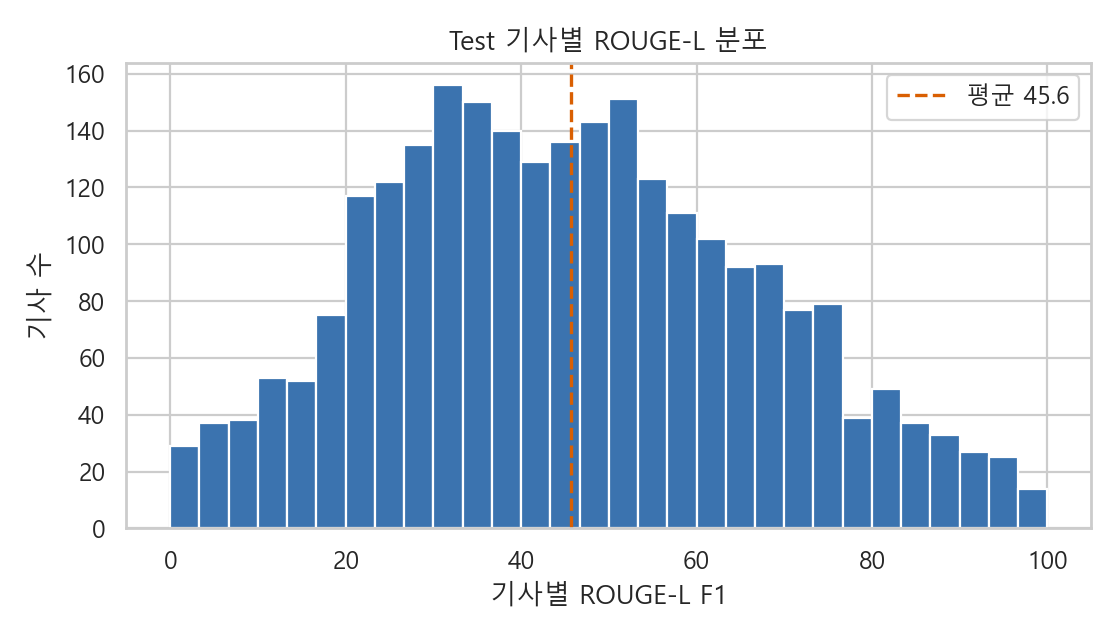

In [143]:
display(Image(filename=str(PROJECT / 'results/05-6_error_analysis/figures/01_rougeL_distribution.png')))


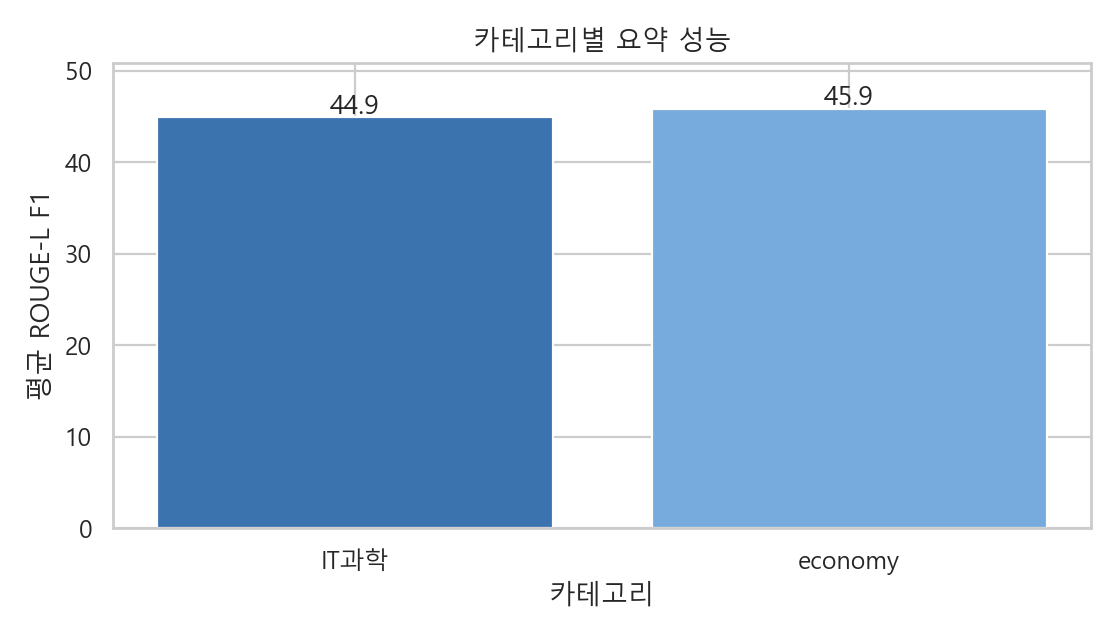

In [144]:
display(Image(filename=str(PROJECT / 'results/05-6_error_analysis/figures/02_category_rougeL.png')))


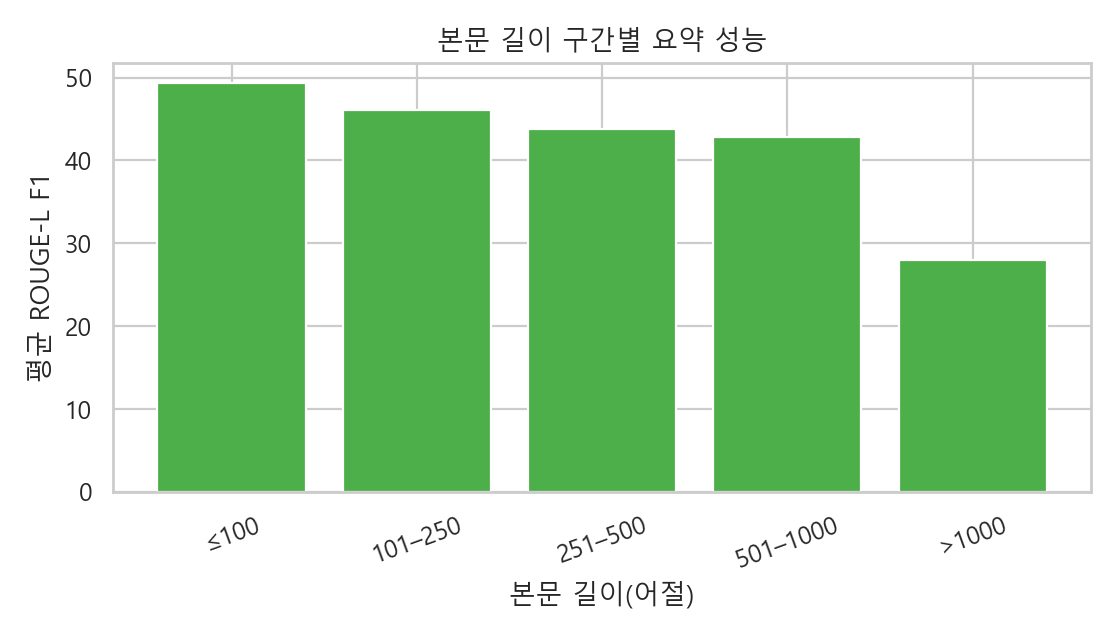

In [145]:
display(Image(filename=str(PROJECT / 'results/05-6_error_analysis/figures/03_length_bin_rougeL.png')))


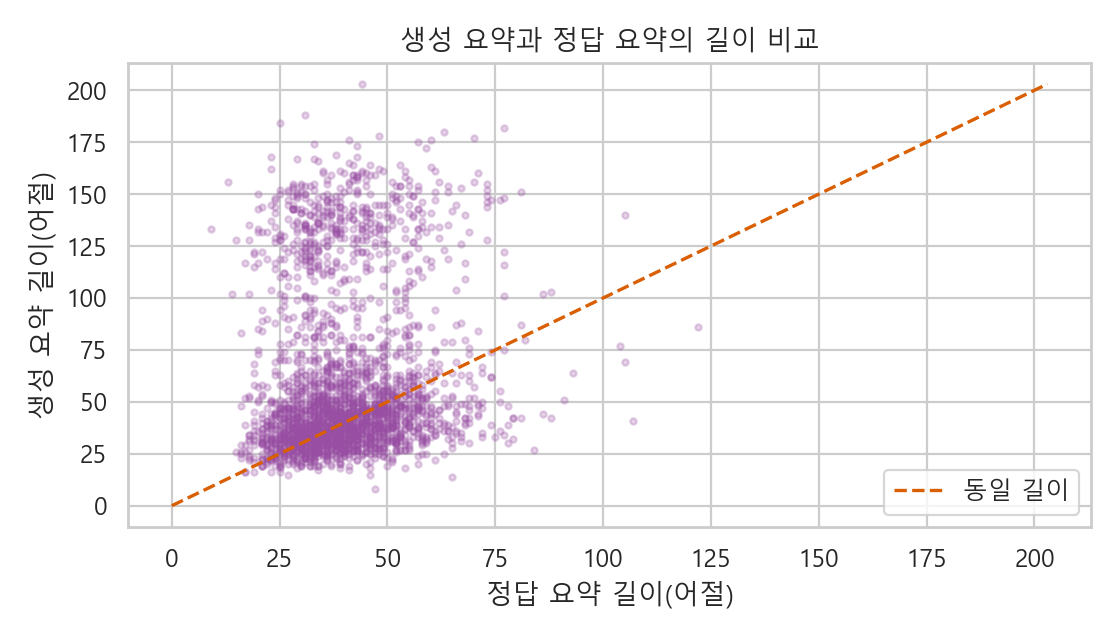

In [146]:
display(Image(filename=str(PROJECT / 'results/05-6_error_analysis/figures/04_prediction_reference_length.png')))


## 08. 완료 범위와 한계
완료: EDA, 토큰화·임베딩, 3종 베이스라인, 자동 전처리, 정확 중복 그룹 처리, A0~A8, 학습률·입력 길이, greedy/beam, 최종 점수, 기초 분석.

미완료: KoGPT2 파인튜닝 구조 비교, split 비율 비교, train 양 10/50/100%, batch 독립 비교, 명시적 epoch 비교표, 반복억제·sampling·길이 조절, 형태소 ROUGE 비교, 통합 experiment_log.csv, 사람의 오류 유형 판정과 지정 그래프, 발표자료. 현재 PDF는 진행 결과 보고서이며 가이드 전체 완료 보고서는 아니다.

현재 네 그래프는 성능 분포·분야·길이·생성 길이 분석이다. 가이드 지정의 오류 유형 막대·길이×오류 유형 히트맵·길이 vs ROUGE 산점도·개선 전후 오류 비교는 별도로 필요하다.